# Notebook 1 of 5 · Data Foundation: Cleaning, Leakage-Safe Splits, Threat Model and EDA

**Project:** Confidence-Aware and Adversarially Robust Cyber Threat Analysis Using Explainable Machine Learning and Evidence-Grounded AI Agents · MSc Data Science Final Project · Spoorthi Hosakote Suresh

This notebook is one of five that together make up the project. It contains the original code **and the outputs of the reported run**, plus guidance added for reading, running and presenting it.

| # | Notebook | Parts of the original notebook | Answers | Needs as input |
|---|---|---|---|---|
| 1 | `01_data_foundation` | Part 1 (+ project overview) | O1 (threat model) | CIC-IDS2017 Kaggle dataset |
| 2 | `02_detectors` | Part 2 | baselines for all RQs | output of 1 |
| 3 | `03_adversarial_attacks` | Part 3 | **RQ1** | outputs of 1, 2 |
| 4 | `04_confidence_mechanism` | Parts 4 and 4b | **RQ2** | outputs of 1, 2, 3 |
| 5 | `05_agents_results_deployment` | Parts 5, 6, 7, 7b, 8 | **RQ3, RQ4**, final answers | outputs of 1, 2, 3, 4 |

**How this notebook is organised:** sections 1–5 below explain the notebook (what it does, how to run it, key concepts, methodology, key results). The original project code and outputs follow. A **viva guide** is at the end.

### Setup · presentation helpers
Writes the small flowchart helper used by every flowchart in this notebook. **Run this cell first** if you re-run any flowchart cell on its own.

In [1]:
# Presentation helpers (flowcharts, colours) are written once to a small module, so every Part can use them
import os, sys
from pathlib import Path
PRES_DIR = Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working")) / "presentation"
PRES_DIR.mkdir(parents=True, exist_ok=True)
(PRES_DIR / "present_lib.py").write_text(r'''"""Presentation helpers for the combined notebook: flowcharts and a shared colour palette."""
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

FILL = {"data": "#DCE9F5", "model": "#E1F0DC", "attack": "#F8DEDB", "policy": "#FFEFD2",
        "agent": "#E9E1F4", "out": "#EFEFEF", "rq": "#FFFFFF", "accept": "#D7EFD7", "flag": "#FFE9B8", "escalate": "#F6C9C4"}
EDGE = {"data": "#3B6EA8", "model": "#4E9A47", "attack": "#C0453F", "policy": "#D9822B",
        "agent": "#7A5DB0", "out": "#7A7A7A", "rq": "#333333", "accept": "#3E8E41", "flag": "#C99100", "escalate": "#B3261E"}
SYSTEM_COLORS = {"A": "#9E9E9E", "B": "#4C72B0", "C": "#DD8452", "D": "#8172B3", "E": "#55A868"}
MODEL_COLORS = {"rf": "#4C72B0", "xgb": "#55A868", "mlp": "#C44E52"}


def _anchor(node, toward):
    x, y, w, h = node[:4]
    tx, ty = toward
    dx, dy = tx - x, ty - y
    if abs(dx) * h >= abs(dy) * w:           # leave through the left or right side
        return (x + (w / 2 + 0.6) * (1 if dx > 0 else -1), y)
    return (x, y + (h / 2 + 0.6) * (1 if dy > 0 else -1))


def flowchart(nodes, edges, size=(15, 6.5), title=None, fontsize=9.5, legend=None):
    """nodes: {key: (x, y, w, h, text, kind)} in a 0-100 x 0-50 canvas (centre coordinates).
    edges: [(from, to, label, rad)] - label and rad optional."""
    fig, ax = plt.subplots(figsize=size)
    ax.set_xlim(0, 100); ax.set_ylim(0, 50); ax.axis("off")
    for k, (x, y, w, h, text, kind) in nodes.items():
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.35,rounding_size=1.0",
                                    fc=FILL[kind], ec=EDGE[kind], lw=1.6, zorder=2))
        ax.text(x, y, text, ha="center", va="center", fontsize=fontsize, zorder=3, linespacing=1.25)
    for e in edges:
        a, b = e[0], e[1]
        label = e[2] if len(e) > 2 else ""
        rad = e[3] if len(e) > 3 else 0.0
        pa = _anchor(nodes[a], nodes[b][:2]); pb = _anchor(nodes[b], nodes[a][:2])
        ax.annotate("", xy=pb, xytext=pa, zorder=1,
                    arrowprops=dict(arrowstyle="-|>", color="#444444", lw=1.4, mutation_scale=14,
                                    connectionstyle=f"arc3,rad={rad}"))
        if label:
            mx, my = (pa[0] + pb[0]) / 2, (pa[1] + pb[1]) / 2
            ax.text(mx, my + 1.0 + 6 * abs(rad), label, ha="center", va="bottom", fontsize=fontsize - 1.5,
                    color="#333333", style="italic", zorder=4,
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    if legend:
        handles = [plt.Rectangle((0, 0), 1, 1, fc=FILL[k], ec=EDGE[k]) for k in legend]
        ax.legend(handles, list(legend.values()), loc="lower center", ncol=len(legend), frameon=False,
                  fontsize=fontsize - 1, bbox_to_anchor=(0.5, -0.04))
    if title:
        ax.set_title(title, fontsize=fontsize + 3, fontweight="bold", loc="left")
    plt.tight_layout()
    return fig, ax
''')
sys.path.insert(0, str(PRES_DIR))
print("presentation helpers ready:", PRES_DIR / "present_lib.py")

presentation helpers ready: /kaggle/working/presentation/present_lib.py


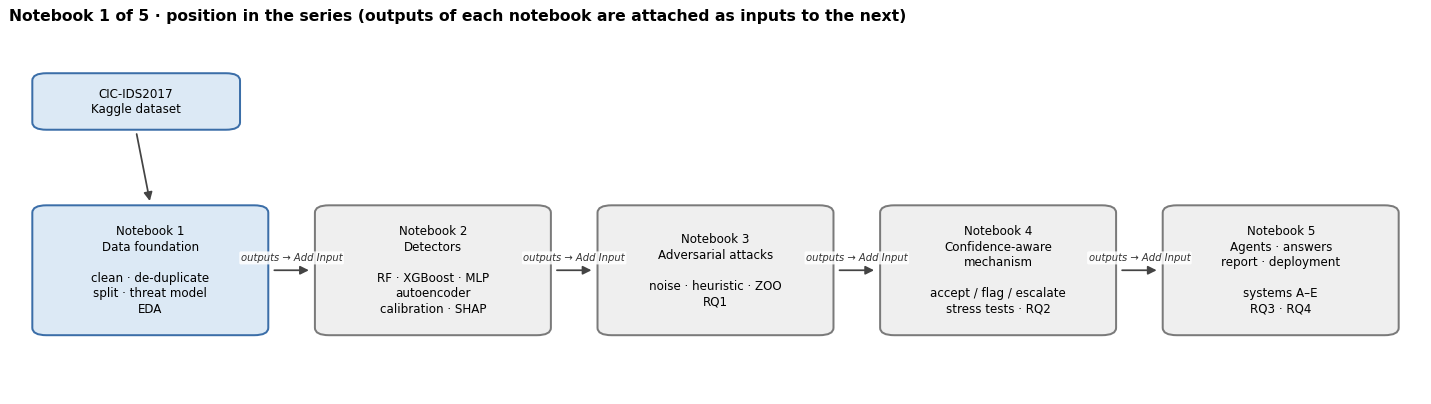

In [ ]:
import os, sys
from pathlib import Path
sys.path.insert(0, str(Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working")) / "presentation"))
import matplotlib.pyplot as plt
from present_lib import flowchart

# Where this notebook sits in the five-notebook series (highlighted box = this notebook)
nodes = {
    "data": (9, 40, 14, 7, "CIC-IDS2017\nKaggle dataset", "data"),
    "n1": (10, 17, 16, 17, 'Notebook 1\nData foundation\n\nclean · de-duplicate\nsplit · threat model\nEDA', "data"),
    "n2": (30, 17, 16, 17, 'Notebook 2\nDetectors\n\nRF · XGBoost · MLP\nautoencoder\ncalibration · SHAP', "out"),
    "n3": (50, 17, 16, 17, 'Notebook 3\nAdversarial attacks\n\nnoise · heuristic · ZOO\nRQ1', "out"),
    "n4": (70, 17, 16, 17, 'Notebook 4\nConfidence-aware\nmechanism\n\naccept / flag / escalate\nstress tests · RQ2', "out"),
    "n5": (90, 17, 16, 17, 'Notebook 5\nAgents · answers\nreport · deployment\n\nsystems A–E\nRQ3 · RQ4', "out"),
}
edges = [("data", "n1")] + [(f"n{i}", f"n{i+1}", "outputs → Add Input") for i in range(1, 5)]
flowchart(nodes, edges, size=(16, 4.6), title="Notebook 1 of 5 · position in the series (outputs of each notebook are attached as inputs to the next)")
plt.show()

## 1 · What this notebook does

This notebook turns the raw CIC-IDS2017 flow files into a **clean, leakage-safe dataset** that every later notebook uses. It removes errors and duplicates, splits the data so that no information from the test set can reach training, prepares the features, handles class imbalance, defines the **threat model** (which features an attacker can change), and explores the data.

| Item | Detail |
|---|---|
| Role in the project | Foundation for all four research questions; delivers **objective O1** (threat model of the attacker-controllable feature space) |
| Input | CIC-IDS2017 *MachineLearningCVE* CSV files: Kaggle dataset `chethuhn/network-intrusion-dataset` (2,830,743 flows, 15 labels) |
| Output folder | `/kaggle/working/nb1_data_foundation/` (model-ready parquet, feature sets, preprocessing parameters, threat model, class weights, `preprocess_lib.py`, figures) |
| Run time | estimated 10–15 minutes on CPU (the timed cleaning steps take about 1–2 minutes; EDA and t-SNE take most of the rest) |
| Hardware | CPU is enough (GPU optional) · Internet not needed |
| Report sections | 3.1–3.6 · Table 3 · Figures 1, 2, 3 and 4 |

## 2 · How to run

**General Kaggle steps (same for every notebook)**
1. On Kaggle, click **Create → New Notebook**, then **File → Import Notebook** and upload this `.ipynb` file.
2. In the right-hand panel, open **Session options** and set the **Accelerator** and **Internet** as listed below.
3. Click **+ Add Input** and attach the inputs listed below. Outputs of your earlier notebooks are found under **Your Work → Notebooks**: choose the notebook and attach its latest **output** version.
4. Click **Save Version → Save & Run All (Commit)**. Running as a saved version keeps the files in `/kaggle/working/` as this notebook's **output**, which the next notebook attaches.
5. When the run finishes, open the version and check the **Final checks** section (every row should show ✔).

**Why this works.** Every Part starts from a clean memory state and finds what it needs by file name, first in `/kaggle/working/` and then anywhere under `/kaggle/input/`. Attached outputs are therefore found automatically; no paths need to be edited.

**For the viva you do not need to re-run anything.** This file already contains every output of the reported run, so all tables and figures can be shown immediately.

**Settings for this notebook**

| Setting | Value |
|---|---|
| Accelerator | None (CPU) is enough |
| Internet | Off |
| Input to attach | Dataset **chethuhn/network-intrusion-dataset** (search for "network intrusion dataset CIC-IDS2017") |

**Settings you can change** (Section 1.1, first code cell)

| Constant | Reported value | Meaning |
|---|---|---|
| `SPLIT_FRACTIONS` | 0.60 / 0.10 / 0.10 / 0.20 | train / calibration / threshold-tuning / test |
| `HOLDOUT_FAMILIES` | Heartbleed, Infiltration | never-seen attacks, kept out of training |
| `CORR_THRESHOLD` | 0.98 | drop one of each feature pair with abs(r) ≥ 0.98 |
| `WINSOR_Q` | (0.0001, 0.9999) | outlier capping at training quantiles |
| `TRAIN_CAPS` | Benign 200,000; others 50,000 | training subsample size per original label |
| `IMBALANCE_STRATEGY` | both | saves class weights and SMOTE; Notebook 2 chooses |
| `BOUND_QUANTILE` | 0.999 | attacker cannot exceed this training quantile |
| `SEED` | 42 | all random steps |

## 3 · Key concepts and techniques

| Concept | In plain words | Why it is used here | Section |
|---|---|---|---|
| Network flow / CICFlowMeter | One row = one bidirectional connection, described by ~80 statistics (packet counts, sizes, timings, flags) | The unit the IDS classifies | 1.2 |
| Data leakage | Information from the test data reaching training, which inflates scores | Every statistic is learned from the training split only | 1.9–1.11 |
| Exact duplicates and conflicting labels | Identical flows repeated, or identical flows with different labels | Removed **before** splitting, otherwise the same flow is in train and test (PortScan was 98.8 % duplicated) | 1.8 |
| Stratified split | Random split that keeps every label's share in each set | Each attack family occurs on only one capture day, so a time split would remove whole classes | 1.9 |
| Never-seen families | Heartbleed and Infiltration held out completely | Test whether the system notices attacks it was never trained on | 1.9 |
| Feature engineering | New row-wise features, e.g. forward byte share, header overhead | Behavioural ratios; computed per row, so no leakage | 1.6 |
| Correlation filter | Drop one of each nearly identical feature pair | Removes copies that would split SHAP credit | 1.10 |
| Winsorising, signed log, standardisation | Cap extreme values, compress heavy tails, put features on one scale | Heavy-tailed flow statistics; bounds wide because extremes are attack signal | 1.11 |
| Class weights / SMOTE | Weight rare classes more / create synthetic rare-class rows | Imbalance of 1,340 : 1 between Benign and Bot | 1.13 |
| Threat model | Which features the attacker controls (13), which follow by formula (33), which they cannot change (35) | Makes adversarial flows realistic (Apruzzese et al., 2022) | 1.15 |
| Projection function | Turns any proposed change into a flow the attacker could really send | Used by every attack in Notebook 3 | 1.15 |
| Mutual information | How much knowing a feature reduces uncertainty about the family | Feature relevance in EDA; three engineered features are in the top 12 | 1.E5 |

## 4 · Methodology at a glance

| Step | What happens | Why | Section |
|---|---|---|---|
| Load | 8 CSV files → 2,830,743 flows, 15 labels → 9 families | Raw data | 1.2 |
| Hygiene | Strip names, fix broken web-attack labels, drop 12 columns that copy others | 66 usable feature columns | 1.3 |
| Infinite / missing | Infinite rates (zero duration) → missing; imputed later with training medians + indicator | 2,867 rows (0.101 %) affected; none dropped | 1.4 |
| Negatives | Drop impossible negatives (150 benign rows); keep the −1 "not recorded" TCP-window code | Physically impossible values | 1.5 |
| Feature engineering | 15 behavioural features | Captures behaviour, not raw counts | 1.6 |
| Duplicates / conflicts | Remove 596,747 exact duplicates and 544 conflicting rows | 2,233,302 flows remain (−21.1 %) | 1.8 |
| Split | Unseen families held out; 60/10/10/20 stratified | 1,339,953 / 223,325 / 223,326 / 446,651 (+ 47 unseen) | 1.9 |
| Feature selection (train) | Constant (2) and redundant (19) features removed | 59 model features + 2 missing indicators; 14 of 15 engineered kept | 1.10 |
| Transformation (train) | Median imputation, capping, signed log, standardisation | Same saved statistics applied to every set | 1.11 |
| Subsample | Cap Benign, DoS Hulk, DDoS per day | 321,277 training rows; imbalance 1,340 : 1 → 235 : 1; still representative (KS ≤ 0.004) | 1.12 |
| Imbalance | Class weights and SMOTE prepared | Choice made in Notebook 2 | 1.13 |
| Evaluation subsets | test-lite (2,083), thr-lite (1,740), agent-eval | Keep attacks, SHAP and LLM runs affordable | 1.14 |
| Threat model | 13 / 33 / 35 features; projection validated | 0 constraint violations; 9 of 12 formulas exact | 1.15 |
| Final checks + EDA | 17 automated checks; EDA on training data only | All 17 passed | 1.17, 1.E |

## 5 · Key results to remember

| Result | Value |
|---|---|
| Raw → clean flows | 2,830,743 → **2,233,302** (596,747 duplicates and 544 conflicting rows removed) |
| Split (train / cal / thr / test / unseen) | 1,339,953 / 223,325 / 223,326 / 446,651 / 47 |
| Model features | **59** + 2 missing-value indicators (19 redundant and 2 constant removed) |
| Training subsample | **321,277** rows; imbalance **1,340 : 1 → 235 : 1** |
| Threat model | **13** controllable / **33** dependent / **35** uncontrollable; **0** violations |
| PCA | 14 of 59 components for 90 % of the variance (first two: 50.6 %) |
| Final checks | 17 of 17 passed |

---
# Original project code and outputs
Everything below is the project code exactly as in the reported run, with its outputs. Grey **Findings** boxes are generated by the code above them.

<a id="top"></a>
# Confidence-Aware and Adversarially Robust Cyber Threat Analysis
### Using Explainable Machine Learning and Evidence-Grounded AI Agents

**Spoorthi Hosakote Suresh (3043NUQT)** · MSc Data Science · University of Hertfordshire · Data Science Project, 2026

---

**Abstract.** Machine-learning intrusion detection systems (IDS) report excellent accuracy on benchmark data, yet their predictions and SHAP explanations can be changed by small, realistic manipulations of network traffic, and agentic IDS pipelines treat every prediction as equally trustworthy. This project builds a **confidence-aware decision mechanism** that combines a classifier's calibrated confidence, an anomaly detector's evidence and the robustness of the SHAP explanation, and decides for each network flow whether to **accept** it, **flag** it for more evidence or **escalate** it to an analyst. Four models are compared: XGBoost and Random Forest as baselines, a multilayer perceptron as the deep-learning model and the Gemma 4 E2B language model; XGBoost (macro-F1 0.956) serves as the detector. On CIC-IDS2017 with a validated attacker-controllable threat model, the detector's macro-F1 collapses from 0.95 to 0.25 under attack; the mechanism keeps 96 % of the resulting wrong decisions away from automatic acceptance (91 % of evasions by an adaptive attacker it was never tuned on) while flagging only 5 % of correctly classified normal traffic. Its novel indicator, the robustness of the SHAP explanation, is a better warning sign of a wrong prediction than the classifier's own confidence (AUROC 0.867 vs 0.738) and catches about one in eight of the errors that confidence and anomaly evidence together still miss. Two stress tests bound this result: an attacker who knows the mechanism still gets 44 % of evasions past it (56 % caught), and adversarial training restores macro-F1 to 0.96 against the attack family it was trained on, so the two defences are complementary rather than competing. Evidence-grounded LLM agents (Gemma 4, LangGraph, retrieval over MITRE ATT&CK) turn flagged flows into evidence-cited threat reports at half the cost of a conventional multi-agent system, but do not improve reliability further; used on its own as a classifier, the LLM reaches macro-F1 0.05 where XGBoost reaches 0.63 on the same flows.

## Research questions and objectives

> **Main research question.** *Is there a confidence-based decision-making algorithm that includes classifier confidence, anomaly evidence and explanation robustness and makes the intrusion detection system more robust to attacks?*

| | Research question | Objective | Answered in |
|---|---|---|---|
| **RQ1** | How does controlled adversarial perturbation affect the detection performance and explanation stability of the selected intrusion-detection models? | **O1** — threat model of the attacker-controllable feature space; decline in macro-F1 and stability of SHAP rankings after the attack | Parts 1, 3 · 6.1 (Notebook 5) |
| **RQ2** | Can a confidence-aware decision mechanism identify cases where the classifier, anomaly detector and explanations disagree? | **O2** — decision strategy combining classifier confidence, anomaly score and SHAP stability to detect disagreement | Part 4 · 6.2 (Notebook 5) |
| **RQ3** | Does the proposed mechanism improve detection reliability compared with the individual models and a conventional multi-agent baseline? | **O3** — compare with classifiers, anomaly detector and multi-agent system on macro-F1 for perturbed data and number of errors identified | Parts 4, 5 · 6.3 (Notebook 5) |
| **RQ4** | What trade-offs arise between robustness, detection performance, processing latency and computational cost? | **O4** — robustness, detection, latency and cost (incl. LLM tokens) of each configuration | Parts 2, 4, 5 · 6.4 (Notebook 5) |

## Results at a glance

| | Key result (reported run) | Verdict |
|---|---|---|
| **RQ1** | Adaptive attack within the threat model: macro-F1 **0.95 → 0.25** (XGBoost), **0.92 → 0.21** (RF), **0.92 → 0.19** (MLP); SHAP rankings significantly less stable than under random noise in 15/15 model/budget cases | ✔ answered |
| **RQ2** | Mechanism catches **96.0 %** of wrong predictions under attack (confidence alone 41.4 %) and **91.4 %** of unseen adaptive evasions at **5 %** false flags on correctly classified clean traffic; 94 % of never-seen attacks not accepted. The novel **explanation-robustness** indicator beats confidence as an error indicator (AUROC **0.867** vs 0.738) and catches **about 1 in 8** of the errors the other two indicators miss | ✔ yes |
| **RQ3** | Better than every individual detector (accepted attacked macro-F1 **0.850** vs 0.602, established); **no reliability gain** over the multi-agent system (errors handled E **0.937** vs D **0.962**, difference −0.024 [−0.059, 0.000], not established) at about half its cost. Guarded agents that may only add caution (G, Section 5.12b, post-hoc) handle **96.4 %** (rules only 92.4 %; not established) while sending 41.8 % of flows to analysts (E 38.1 %) | ✔ answered |
| **RQ4** | Mechanism ≈ **8.7 ms**/flow; agents 22–64 s/flow; proposed system E uses **≈ 51 % fewer tokens** and **≈ 54 % less time** than multi-agent D, with no established difference in reliability. The LLM as a stand-alone classifier: 0.9 s per flow (≈ 10 days per million flows) | ✔ answered |
| **Limits** | Defence-aware attacker: evasions caught **92 % → 56 %**. Adversarial training: **0.960** macro-F1 against the attack family it was trained on (mechanism, accepted flows: 0.465). LLM comparison covers Gemma 4 E2B vs E4B only | see Part 4b, 6.9 |

#### The four models compared
| Role | Model | Key result (reported run) |
|---|---|---|
| Baseline 1 · **main detector** | **XGBoost** | macro-F1 **0.956** [0.950, 0.961], recall 0.949, 0.20 % of attacks missed; smallest drop under the strongest adaptive attack (0.95 → 0.25) |
| Baseline 2 | Random Forest | macro-F1 0.946 [0.939, 0.954]; lowest false-alarm rate on benign traffic (0.031 %) |
| Deep learning | MLP | macro-F1 0.936 [0.929, 0.943]; fastest prediction (0.6 ms); largest drop under the strongest adaptive attack (0.92 → 0.19), but highest macro-F1 over all attack types (0.73) |
| LLM | Gemma 4 E2B | inside the mechanism (system E): 93.7 % of detector errors handled, 0 % unsupported claims, 1,506 tokens and 29 s per flow; as a stand-alone classifier only macro-F1 0.05 (XGBoost 0.63 on the same flows, Section 5.19) |

Also tested but not carried forward: Isolation Forest (AUROC 0.895, far below the autoencoder's 0.976) and Gemma 4 E4B (no established gain in errors handled, 95.1 % vs 93.7 %; lower macro-F1 of automatic decisions, 0.887 vs 0.954; 23 s slower per flow). The autoencoder is not one of the compared models: it is the anomaly detector *inside* the mechanism.


<a id="related"></a>
## Related work and research gap

This section places the project in four lines of prior work and states the gap each research question addresses.

**1 · Machine learning for network intrusion detection.** Flow-based classifiers trained on labelled captures such as CIC-IDS2017 (Sharafaldin, Lashkari and Ghorbani, 2018) routinely report macro-F1 above 0.95 with tree ensembles such as random forests (Breiman, 2001) and gradient boosting (Chen and Guestrin, 2016). Anomaly detectors, such as isolation forests (Liu, Ting and Zhou, 2008) and autoencoder ensembles (Mirsky *et al.*, 2018), model normal traffic instead and can flag attacks never seen in training. Sommer and Paxson (2010) warned early that high benchmark accuracy rarely transfers to operational networks, and Arp *et al.* (2022) catalogue recurring pitfalls, among them data leakage, inappropriate baselines and lab-only evaluation. Engelen, Rimmer and Joosen (2021) document labelling and flow-construction errors in CIC-IDS2017 itself. *This project's response:* a leakage-safe pipeline, calibrated probabilities, confidence intervals and an explicit discussion of the dataset's limits (Part 1, Part 8).

**2 · Adversarial attacks on detectors and on their explanations.** Small, targeted input changes can flip the predictions of neural networks (Szegedy *et al.*, 2014; Goodfellow, Shlens and Szegedy, 2015; Carlini and Wagner, 2017), and black-box attacks such as ZOO need only query access (Chen *et al.*, 2017). For intrusion detection, Corona, Giacinto and Roli (2013) set out a taxonomy of attacks on IDS, generative attacks such as IDSGAN produce evasive flows (Lin, Shi and Xue, 2022), and Apruzzese *et al.* (2022) show that many published attacks change features an attacker cannot control, so realistic threat models are essential. Explanations are vulnerable as well: SHAP (Lundberg and Lee, 2017; Lundberg *et al.*, 2020) and LIME (Ribeiro, Singh and Guestrin, 2016) can be manipulated (Slack *et al.*, 2020), gradient-based interpretations are fragile under imperceptible perturbations (Ghorbani, Abid and Zou, 2019; Dombrowski *et al.*, 2019), and explanation robustness is not guaranteed even without an attacker (Alvarez-Melis and Jaakkola, 2018). Adversarial training (Madry *et al.*, 2018) is the standard defence, but it requires examples of the attack. *Gap → RQ1:* few studies measure the effect of a *physically realisable* attack on both the detection performance and the explanation stability of several IDS models at once.

**3 · Knowing when not to trust a prediction.** The reject option (Chow, 1970) and selective classification (Geifman and El-Yaniv, 2017) let a model abstain when it is uncertain; softmax confidence is a useful but imperfect indicator of errors (Hendrycks and Gimpel, 2017) and is often miscalibrated in modern models (Guo *et al.*, 2017), which temperature and Dirichlet calibration correct (Kull *et al.*, 2019). Conformal prediction (Vovk, Gammerman and Shafer, 2005; Angelopoulos and Bates, 2023) turns nonconformity scores into p-values with a guaranteed false-alarm rate. In security, Transcend (Jordaney *et al.*, 2017) uses conformal evaluation to reject malware-classifier decisions under concept drift, and TESSERACT (Pendlebury *et al.*, 2019) shows how biased evaluation hides such drift. *Gap → RQ2:* these approaches rely on one indicator (confidence or conformity). None of the cited work combines calibrated confidence, anomaly evidence and explanation robustness into one decision rule, or tests such a rule against an adaptive attacker, including one that knows the rule.

**4 · LLM agents for security operations.** Retrieval-augmented generation grounds a language model in an external knowledge base (Lewis *et al.*, 2020), and agent designs interleave reasoning with tool use (Yao *et al.*, 2023). In cyber defence, CyberRAG uses a central LLM agent with fine-tuned classifiers per attack family and iterative retrieval to classify and explain web-payload attacks (Blefari *et al.*, 2026). Chou, Sudheer and Park (2026) combine ensemble IDS models, SHAP and a graph-based multi-agent RAG pipeline to write incident reports for IoT traffic, judged by an LLM for faithfulness and groundedness. Hallucination remains the main risk of such systems (Ji *et al.*, 2023), and MITRE ATT&CK (MITRE, 2026) is the usual shared vocabulary for grounding. *Gap → RQ3, RQ4:* agentic IDS pipelines usually send every prediction to the agents, are evaluated on clean data, and check reports with another LLM. This project tests whether a confidence-aware mechanism should decide *which* flows reach the agents, compares that design with a conventional multi-agent system under attack, checks every agent claim with a deterministic verifier, and reports the cost in tokens, time and energy.

**Summary of the gap.** To the author's knowledge, no prior study (i) evaluates IDS detection *and* explanation stability under a validated, attacker-realistic threat model, (ii) fuses calibrated confidence, conformal anomaly evidence and explanation robustness into a transparent accept / flag / escalate rule, and (iii) measures whether such a rule makes evidence-grounded LLM agents more reliable or only cheaper. Parts 3, 4 and 5 address (i), (ii) and (iii) in turn.

[↑ back to contents](#top)

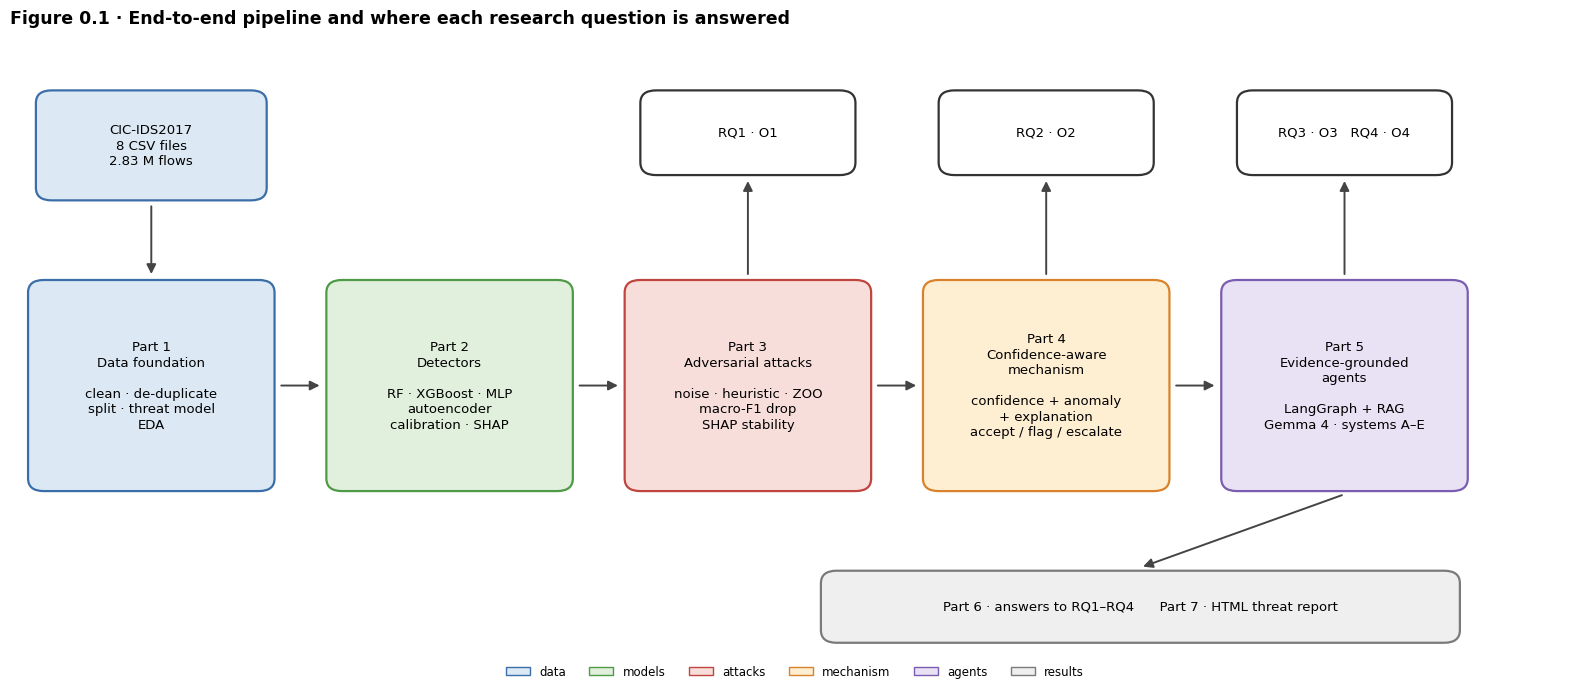

In [2]:
import os, sys
from pathlib import Path
sys.path.insert(0, str(Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working")) / "presentation"))
import matplotlib.pyplot as plt
from present_lib import flowchart

nodes = {
    "data": (9, 41, 14, 8, "CIC-IDS2017\n8 CSV files\n2.83 M flows", "data"),
    "p1": (9, 22, 15, 16, "Part 1\nData foundation\n\nclean · de-duplicate\nsplit · threat model\nEDA", "data"),
    "p2": (28, 22, 15, 16, "Part 2\nDetectors\n\nRF · XGBoost · MLP\nautoencoder\ncalibration · SHAP", "model"),
    "p3": (47, 22, 15, 16, "Part 3\nAdversarial attacks\n\nnoise · heuristic · ZOO\nmacro-F1 drop\nSHAP stability", "attack"),
    "p4": (66, 22, 15, 16, "Part 4\nConfidence-aware\nmechanism\n\nconfidence + anomaly\n+ explanation\naccept / flag / escalate", "policy"),
    "p5": (85, 22, 15, 16, "Part 5\nEvidence-grounded\nagents\n\nLangGraph + RAG\nGemma 4 · systems A–E", "agent"),
    "rq1": (47, 42, 13, 6, "RQ1 · O1", "rq"),
    "rq2": (66, 42, 13, 6, "RQ2 · O2", "rq"),
    "rq34": (85, 42, 13, 6, "RQ3 · O3   RQ4 · O4", "rq"),
    "p67": (72, 4.5, 40, 5, "Part 6 · answers to RQ1–RQ4      Part 7 · HTML threat report", "out"),
}
edges = [("data", "p1"), ("p1", "p2"), ("p2", "p3"), ("p3", "p4"), ("p4", "p5"),
         ("p3", "rq1"), ("p4", "rq2"), ("p5", "rq34"), ("p5", "p67")]
flowchart(nodes, edges, size=(16, 7), title="Figure 0.1 · End-to-end pipeline and where each research question is answered",
          legend={"data": "data", "model": "models", "attack": "attacks", "policy": "mechanism", "agent": "agents", "out": "results"})
plt.show()

<a id="part1"></a>
# Part 1 · Data Foundation: Cleaning, Splits, Threat Model and EDA

| | |
|---|---|
| **Goal** | Turn the raw CIC-IDS2017 capture into clean, de-duplicated, leakage-safe data; define the threat model; explore the data. |
| **Answers** | foundation for every RQ; threat model for **O1** |
| **Inputs** | 8 raw CSV files (2.83 M flows) |
| **Outputs used later** | clean and model-ready tables, fixed splits, preprocessing library, threat model, evaluation subsets, feature dictionary |
| **Run time** | ≈ 25 min (CPU) |

#### Main research question
*Is there a confidence-based decision-making algorithm that combines classifier confidence, anomaly scores and explanation robustness to make an intrusion detection system more robust to attacks?*

#### Project map: where each research question is answered
| Notebook | Content | Objective / RQ |
|---|---|---|
| **1 · Data foundation** (this) | cleaning, leakage-safe splits, preprocessing, imbalance, evaluation subsets, **threat model**, feature dictionary, EDA | foundation; threat model for **O1** |
| 2 · Detectors | Random Forest, XGBoost, MLP; Isolation Forest + autoencoder; calibration; clean SHAP baseline; latency and compute cost | baselines for RQ1–RQ4 |
| 3 · Adversarial attacks | constrained attacks within the threat model; macro-F1 decline; SHAP-ranking stability | **answers RQ1 (O1)** |
| 4 · Confidence-aware mechanism | fuses calibrated confidence, anomaly p-value and deployable explanation robustness; detects classifier / anomaly / explanation disagreement; accept / flag / escalate; unseen-family check | **answers RQ2 (O2)** |
| 5 · Agents, comparison and trade-offs | LangGraph + RAG (MITRE ATT&CK, feature dictionary, similar training cases) with Gemma 4 (`google/gemma-4-E2B-it`) on Kaggle; single-agent and multi-agent baselines vs the proposed mechanism; latency, GPU time, tokens | **answers RQ3 (O3) and RQ4 (O4)**; final answers to RQ1–RQ4 |

#### What this part delivers to later parts
| Deliverable | Used for |
|---|---|
| Clean, de-duplicated data with fixed `train / cal / thr / test / unseen` splits | every part uses the same rows |
| Fitted preprocessing (`preprocess_lib.py` + statistics fitted on `train` only) | perturbed flows are transformed exactly like clean ones |
| Training subsample, class weights, SMOTE set | Part 2 |
| **Threat model** (`threat_model.json`): which features an attacker controls, in which direction, within which bounds, and how dependent features follow | O1: realistic perturbations in Part 3 |
| **Evaluation subsets** (`test-lite`, `thr-lite`, `agent-eval`) | expensive steps (attacks, SHAP, LLM agents) all run on the *same* flows, so configurations are comparable (O3, O4) |
| **Feature dictionary** with feature groups | SHAP stability per feature group (O1, O2); RAG knowledge source for the agents (O3) |
| EDA (Part E) | justification of every preprocessing decision |

#### Leakage rule
Fixed row-wise rules run **before** the split; everything that learns numbers from data (feature selection, imputation, scaling, bounds of the threat model, subsampling, SMOTE) is fitted on **`train` only**. EDA looks at `train` only; `test` is never inspected.

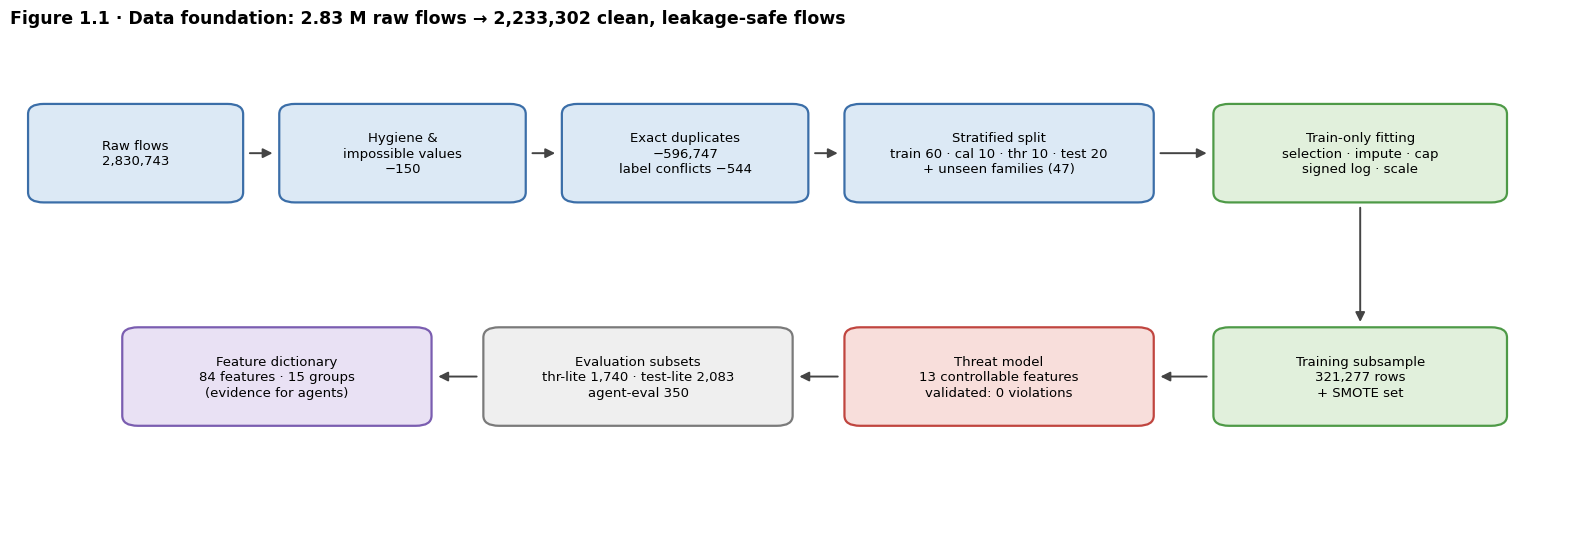

In [3]:
import os, sys
from pathlib import Path
sys.path.insert(0, str(Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working")) / "presentation"))
import matplotlib.pyplot as plt
from present_lib import flowchart

nodes = {
    "raw": (8, 38, 13, 9, "Raw flows\n2,830,743", "data"),
    "hyg": (25, 38, 15, 9, "Hygiene &\nimpossible values\n−150", "data"),
    "dup": (43, 38, 15, 9, "Exact duplicates\n−596,747\nlabel conflicts −544", "data"),
    "split": (63, 38, 19, 9, "Stratified split\ntrain 60 · cal 10 · thr 10 · test 20\n+ unseen families (47)", "data"),
    "fit": (86, 38, 18, 9, "Train-only fitting\nselection · impute · cap\nsigned log · scale", "model"),
    "sub": (86, 16, 18, 9, "Training subsample\n321,277 rows\n+ SMOTE set", "model"),
    "tm": (63, 16, 19, 9, "Threat model\n13 controllable features\nvalidated: 0 violations", "attack"),
    "lite": (40, 16, 19, 9, "Evaluation subsets\nthr-lite 1,740 · test-lite 2,083\nagent-eval 350", "out"),
    "dict": (17, 16, 19, 9, "Feature dictionary\n84 features · 15 groups\n(evidence for agents)", "agent"),
}
edges = [("raw", "hyg"), ("hyg", "dup"), ("dup", "split"), ("split", "fit"), ("fit", "sub"),
         ("sub", "tm"), ("tm", "lite"), ("lite", "dict")]
flowchart(nodes, edges, size=(16, 5.6), title="Figure 1.1 · Data foundation: 2.83 M raw flows → 2,233,302 clean, leakage-safe flows")
plt.show()

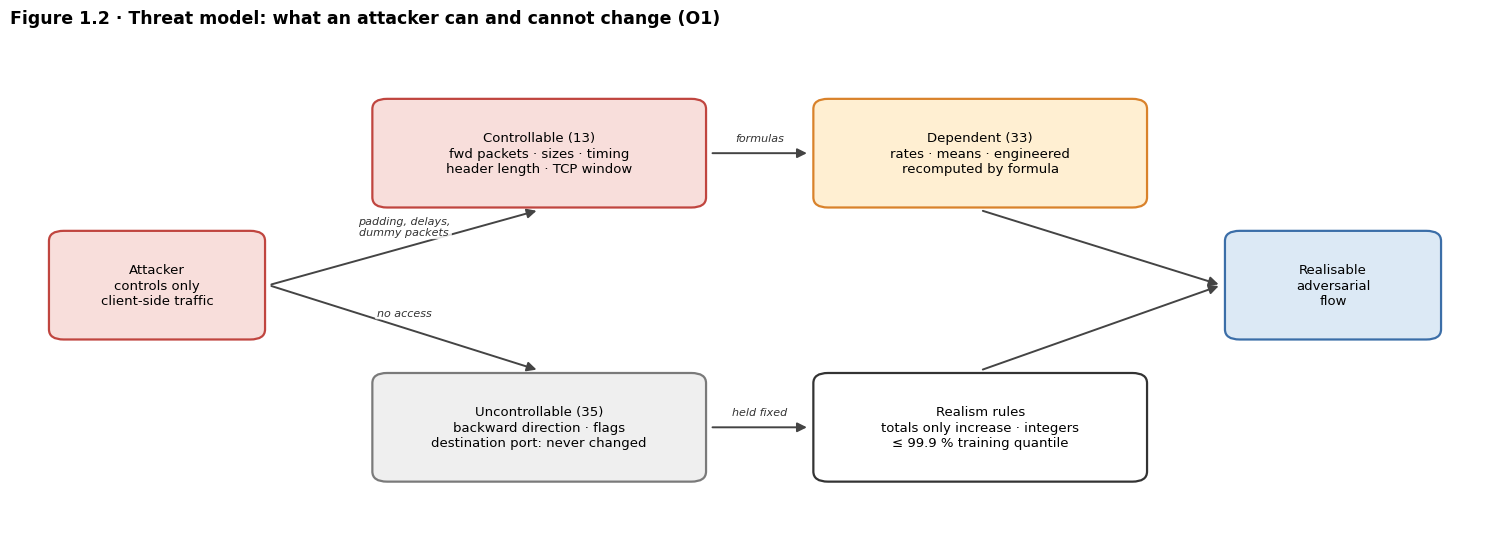

In [4]:
import os, sys
from pathlib import Path
sys.path.insert(0, str(Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working")) / "presentation"))
import matplotlib.pyplot as plt
from present_lib import flowchart

nodes = {
    "att": (10, 25, 14, 10, "Attacker\ncontrols only\nclient-side traffic", "attack"),
    "ctrl": (36, 38, 22, 10, "Controllable (13)\nfwd packets · sizes · timing\nheader length · TCP window", "attack"),
    "dep": (66, 38, 22, 10, "Dependent (33)\nrates · means · engineered\nrecomputed by formula", "policy"),
    "unc": (36, 11, 22, 10, "Uncontrollable (35)\nbackward direction · flags\ndestination port: never changed", "out"),
    "rules": (66, 11, 22, 10, "Realism rules\ntotals only increase · integers\n≤ 99.9 % training quantile", "rq"),
    "flow": (90, 25, 14, 10, "Realisable\nadversarial\nflow", "data"),
}
edges = [("att", "ctrl", "padding, delays,\ndummy packets"), ("ctrl", "dep", "formulas"), ("dep", "flow"),
         ("unc", "rules", "held fixed"), ("rules", "flow"), ("att", "unc", "no access", 0.0)]
flowchart(nodes, edges, size=(15, 5.6), title="Figure 1.2 · Threat model: what an attacker can and cannot change (O1)")
plt.show()

## 1.1 · Setup and decisions
Every decision is a setting here. Change a setting and re-run the whole notebook; all Findings boxes update automatically.

In [5]:
import os, re, sys, json, time, platform, warnings, importlib
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow, pyarrow.parquet as pq
import sklearn
from scipy.stats import ks_2samp
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 60); pd.set_option("display.width", 220)

# ---------------- Paths ----------------
INPUT_ROOT = Path(os.environ.get("IDS_INPUT_ROOT", "/kaggle/input"))
WORK_ROOT  = Path(os.environ.get("IDS_WORK_ROOT", "/kaggle/working"))
OUT_DIR    = WORK_ROOT / "nb1_data_foundation"
FIG_DIR    = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
NOTEBOOK_ID = "nb1_data_foundation_v1"

SEED = 42
rng = np.random.default_rng(SEED)

# ---------------- Input ----------------
NB01_PARQUET = "cicids2017_audited.parquet"     # alternative input: output of an earlier audit notebook
RAW_CSV_GLOB = "*pcap_ISCX*.csv"                 # preferred input: the 8 raw MachineLearningCVE files
LABEL_COL, TARGET_COL = "Label", "label_family"
META_KNOWN = [LABEL_COL, TARGET_COL, "source_file", "row_in_file"]

FAMILY_MAP = {
    "BENIGN": "Benign",
    "DoS Hulk": "DoS", "DoS GoldenEye": "DoS", "DoS slowloris": "DoS", "DoS Slowhttptest": "DoS",
    "DDoS": "DDoS", "PortScan": "PortScan", "Bot": "Bot",
    "FTP-Patator": "BruteForce", "SSH-Patator": "BruteForce",
    "Web Attack - Brute Force": "WebAttack", "Web Attack - XSS": "WebAttack",
    "Web Attack - Sql Injection": "WebAttack",
    "Infiltration": "Infiltration", "Heartbleed": "Heartbleed",
}

# ---------------- Decisions ----------------
PORT_COL          = "Destination Port"        # shortcut feature: kept OUT of the main set, bucketed for an ablation
SENTINEL_COLS     = ["Init_Win_bytes_forward", "Init_Win_bytes_backward"]          # -1 = "not recorded": keep
NEG_DROP_ROW_COLS = ["Fwd Header Length", "Bwd Header Length", "min_seg_size_forward", "Flow Duration"]
NEG_CLIP_COLS     = ["Flow IAT Min", "Fwd IAT Min", "Flow IAT Mean", "Flow IAT Max", "Flow Bytes/s", "Flow Packets/s"]
CONFLICT_POLICY   = "drop_all"                # "drop_all" or "majority"
HOLDOUT_FAMILIES  = ["Heartbleed", "Infiltration"]
SPLIT_FRACTIONS   = {"train": 0.60, "cal": 0.10, "thr": 0.10, "test": 0.20}
MIN_ROWS_PER_LABEL = 10

# Train-fitted feature selection
MAX_MISSING_FRAC  = 0.50       # drop a feature missing in > 50% of training rows
CORR_THRESHOLD    = 0.98       # drop one of each pair with |r| >= 0.98 (after signed log)
CORR_SAMPLE       = 200_000    # training rows used to estimate correlations

# Train-fitted transformation
WINSOR_Q          = (0.0001, 0.9999)   # cap extreme values at these TRAIN quantiles (None = off)

# Subsample (class imbalance, majority side)
TRAIN_CAPS        = {"BENIGN": 200_000, "_default": 50_000}   # per original label
SUBSAMPLE_STRATA  = "source_file"      # inside a capped label, keep each day's share (None = plain random)
NEAR_DUP_THINNING = False              # True = spend the budget on distinct flows first (see Section 1.12)
THIN_DECIMALS     = 1

# Class imbalance (minority side)
IMBALANCE_STRATEGY = "both"            # "class_weight", "smote" or "both" (saves both; Part 03 compares)
SMOTE_MIN_PER_LABEL = 2_000            # oversample each original label below this up to this size
SMOTE_K = 5

# Evaluation subsets (nested: agent-eval ⊂ test-lite)
LITE_PER_FAMILY   = 300        # test-lite / thr-lite: flows per family for attacks and SHAP (Parts 3-4)
AGENT_PER_FAMILY  = 50         # agent-eval: flows per family for LLM configurations (Part 5, token cost)
LITE_MIN_PER_LABEL = 5         # every sub-type (e.g. SQL injection) appears in each subset

# Threat model (O1)
BOUND_QUANTILE    = 0.999      # attacker cannot push a feature beyond this TRAIN quantile (plausibility)
DEMO_BUDGET       = 0.20       # size of the random sanity-check perturbation in Section 1.15

assert abs(sum(SPLIT_FRACTIONS.values()) - 1) < 1e-9
assert CONFLICT_POLICY in {"drop_all", "majority"} and IMBALANCE_STRATEGY in {"class_weight", "smote", "both"}

ENV = {"notebook_id": NOTEBOOK_ID, "run_started_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
       "python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
       "scikit-learn": sklearn.__version__, "pyarrow": pyarrow.__version__}
display(pd.DataFrame(ENV.items(), columns=["item", "value"]))

CLEANING_LOG = []
def log_step(step, before, after, note=""):
    CLEANING_LOG.append(dict(step=step, rows_before=int(before), rows_after=int(after),
                             rows_removed=int(before - after), note=note))

def findings(rows, meaning=""):
    text = "> #### Findings\n> | Check | Result |\n> |---|---|\n" + "".join(f"> | {a} | {b} |\n" for a, b in rows)
    if meaning: text += f">\n> **Meaning:** {meaning}\n"
    display(Markdown(text))

def to_builtin(o):
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o) if np.isfinite(o) else None
    if isinstance(o, np.bool_): return bool(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, Path): return str(o)
    raise TypeError(type(o))

,item,value
0,notebook_id,nb1_data_foundation_v1
1,run_started_utc,2026-10-24T16:03:18+00:00
2,python,3.13.15
3,pandas,2.3.3
4,numpy,2.1.3
5,scikit-learn,1.6.1
6,pyarrow,23.0.1


### 1.1b · Reusable preprocessing library
The row-wise rules and the fitted transformation are written to `preprocess_lib.py` and saved with the outputs. Later notebooks (and any new traffic, e.g. adversarial examples in RQ1) are then transformed with **exactly** the same code and the same training statistics.

The library also holds the **threat-model functions** (Section 1.15): `project_to_threat_model` turns any proposed perturbation into a realistic one, and `recompute_dependent` keeps derived features consistent.

In [6]:
LIB_SRC = r"""
import numpy as np, pandas as pd

def signed_log(X):
    return np.sign(X) * np.log1p(np.abs(X))

def _ratio(a, b):
    a = np.asarray(a, dtype="float64"); b = np.asarray(b, dtype="float64")
    out = np.zeros_like(a)
    np.divide(a, b, out=out, where=(b != 0) & np.isfinite(b))
    return out

def engineer_features(df):
    # Row-wise engineered features. Uses no statistics, so it is leak-free.
    # A feature is skipped if a column it needs is missing.
    g = lambda c: df[c].to_numpy(dtype="float64") if c in df.columns else None
    new = {}
    fp, bp = g("Total Fwd Packets"), g("Total Backward Packets")
    fb, bb = g("Total Length of Fwd Packets"), g("Total Length of Bwd Packets")
    if fp is not None and bp is not None:
        tp = fp + bp
        new["eng_total_packets"]  = tp
        new["eng_fwd_pkt_share"]  = _ratio(fp, tp)                 # direction balance of packets
        new["eng_single_packet"]  = (tp <= 1).astype("float64")
    if fb is not None and bb is not None:
        tb = fb + bb
        new["eng_total_bytes"]    = tb
        new["eng_fwd_byte_share"] = _ratio(fb, tb)                 # direction balance of bytes
        new["eng_no_fwd_payload"] = (fb == 0).astype("float64")    # typical of scans / SYN floods
        if fp is not None and bp is not None:
            new["eng_bytes_per_pkt_ratio"] = _ratio(_ratio(fb, fp), _ratio(bb, bp) + 1)   # request vs response size
    fh = g("Fwd Header Length")
    if fh is not None and fb is not None:
        new["eng_fwd_header_share"] = _ratio(fh, fh + fb)          # header overhead vs payload
    m, s = g("Flow IAT Mean"), g("Flow IAT Std")
    if m is not None and s is not None:
        new["eng_iat_cv"] = _ratio(s, m)                           # burstiness of timing
    m, s = g("Packet Length Mean"), g("Packet Length Std")
    if m is not None and s is not None:
        new["eng_pkt_len_cv"] = _ratio(s, m)                       # variability of packet size
    a, i = g("Active Mean"), g("Idle Mean")
    if a is not None and i is not None:
        new["eng_active_idle_ratio"] = _ratio(a, i + 1)
    flags = [c for c in ["FIN Flag Count", "SYN Flag Count", "RST Flag Count", "PSH Flag Count",
                         "ACK Flag Count", "URG Flag Count", "ECE Flag Count"] if c in df.columns]
    if flags:
        new["eng_flag_total"] = df[flags].to_numpy(dtype="float64").sum(1)
    d = g("Flow Duration")
    if d is not None:
        new["eng_zero_duration"] = (d == 0).astype("float64")     # where Flow Bytes/s & Packets/s are undefined
    for c, name in [("Init_Win_bytes_forward", "eng_init_win_fwd_missing"),
                    ("Init_Win_bytes_backward", "eng_init_win_bwd_missing")]:
        v = g(c)
        if v is not None:
            new[name] = (v == -1).astype("float64")
    return pd.DataFrame(new, index=df.index)

def port_buckets(port):
    # One-hot IANA port ranges: a coarse, less shortcut-prone encoding than the raw port number.
    p = np.asarray(port, dtype="float64")
    return pd.DataFrame({"port_well_known": (p < 1024).astype("float64"),
                         "port_registered": ((p >= 1024) & (p < 49152)).astype("float64"),
                         "port_dynamic":    (p >= 49152).astype("float64")})

def fit_preprocessing(train, cols, winsor_q=(0.0001, 0.9999)):
    # Learn every number from the TRAINING rows only.
    X = train[cols].to_numpy(dtype="float64", copy=True)
    X[~np.isfinite(X)] = np.nan
    med = np.nanmedian(X, axis=0); med = np.where(np.isfinite(med), med, 0.0)
    miss_cols = [c for c, m in zip(cols, np.isnan(X).any(0)) if m]
    X = np.where(np.isnan(X), med, X)
    binary = [c for j, c in enumerate(cols) if np.isin(np.unique(X[:, j]), [0.0, 1.0]).all()]
    cont = np.array([c not in binary for c in cols])
    if winsor_q is None:
        lo, hi = np.full(len(cols), -np.inf), np.full(len(cols), np.inf)
    else:
        lo, hi = np.quantile(X, winsor_q[0], axis=0), np.quantile(X, winsor_q[1], axis=0)
        lo[~cont], hi[~cont] = -np.inf, np.inf
    Z = signed_log(np.clip(X, lo, hi))
    mu, sd = Z.mean(0), Z.std(0)
    mu[~cont], sd[~cont] = 0.0, 1.0
    sd[sd == 0] = 1.0
    f = lambda a: [float(v) for v in a]
    return {"model_features": list(cols), "median": f(med), "indicator_cols": miss_cols,
            "binary_cols": binary, "clip_low": f(lo), "clip_high": f(hi), "mean": f(mu), "std": f(sd),
            "winsor_q": list(winsor_q) if winsor_q else None}

def apply_preprocessing(frame, params, passthrough=(), dtype="float32"):
    # Impute -> cap -> signed log -> standardise, with the saved training statistics.
    cols = params["model_features"]
    X = frame[cols].to_numpy(dtype="float64", copy=True)
    X[~np.isfinite(X)] = np.nan
    miss = np.isnan(X)
    X = np.where(miss, np.asarray(params["median"]), X)
    binary = set(params["binary_cols"]); cont = np.array([c not in binary for c in cols])
    lo, hi = np.asarray(params["clip_low"]), np.asarray(params["clip_high"])
    X = np.clip(X, lo, hi)
    X[:, cont] = signed_log(X[:, cont])
    X = (X - np.asarray(params["mean"])) / np.asarray(params["std"])
    out = pd.DataFrame(X.astype(dtype), columns=cols, index=frame.index)
    for c in params["indicator_cols"]:
        out[c + "__missing"] = miss[:, cols.index(c)].astype(dtype)
    for c in passthrough:
        out[c] = frame[c].fillna(0).to_numpy(dtype=dtype)
    return out

# ======================= Threat-model helpers (used in Parts 1 and 3) =======================
_US = 1e6   # CICFlowMeter durations and IATs are in microseconds

def _c(d, name):
    return d[name].to_numpy(dtype="float64")

# Dependent features: formulas of other features (CICFlowMeter definitions).
# Used RELATIVELY: new = original * f(perturbed) / f(original), so an unperturbed flow is never changed
# and an approximate formula still moves the value in the right direction by the right factor.
FORMULAS = {
    "Fwd Packet Length Mean": lambda d: _ratio(_c(d, "Total Length of Fwd Packets"), _c(d, "Total Fwd Packets")),
    "Avg Fwd Segment Size":   lambda d: _ratio(_c(d, "Total Length of Fwd Packets"), _c(d, "Total Fwd Packets")),
    "Subflow Fwd Packets":    lambda d: _c(d, "Total Fwd Packets"),
    "Subflow Fwd Bytes":      lambda d: _c(d, "Total Length of Fwd Packets"),
    "Packet Length Mean":     lambda d: _ratio(_c(d, "Total Length of Fwd Packets") + _c(d, "Total Length of Bwd Packets"),
                                               _c(d, "Total Fwd Packets") + _c(d, "Total Backward Packets")),
    "Average Packet Size":    lambda d: _ratio(_c(d, "Total Length of Fwd Packets") + _c(d, "Total Length of Bwd Packets"),
                                               _c(d, "Total Fwd Packets") + _c(d, "Total Backward Packets")),
    "Flow Bytes/s":           lambda d: _ratio(_c(d, "Total Length of Fwd Packets") + _c(d, "Total Length of Bwd Packets"),
                                               _c(d, "Flow Duration") / _US),
    "Flow Packets/s":         lambda d: _ratio(_c(d, "Total Fwd Packets") + _c(d, "Total Backward Packets"), _c(d, "Flow Duration") / _US),
    "Fwd Packets/s":          lambda d: _ratio(_c(d, "Total Fwd Packets"), _c(d, "Flow Duration") / _US),
    "Bwd Packets/s":          lambda d: _ratio(_c(d, "Total Backward Packets"), _c(d, "Flow Duration") / _US),
    "Down/Up Ratio":          lambda d: _ratio(_c(d, "Total Backward Packets"), _c(d, "Total Fwd Packets")),
    "Flow IAT Mean":          lambda d: _ratio(_c(d, "Flow Duration"), _c(d, "Total Fwd Packets") + _c(d, "Total Backward Packets") - 1),
    "Fwd IAT Mean":           lambda d: _ratio(_c(d, "Fwd IAT Total"), _c(d, "Total Fwd Packets") - 1),
}

def recompute_dependent(orig, pert):
    out = pert.copy()
    for col, f in FORMULAS.items():
        if col not in out.columns:
            continue
        try:
            fo, fn = f(orig), f(pert)
        except KeyError:
            continue
        base = orig[col].to_numpy(dtype="float64")
        ok = (fo != 0) & np.isfinite(fo) & np.isfinite(fn)
        val = np.where(ok, base * _ratio(fn, np.where(ok, fo, 1.0)), fn)
        same = np.isclose(fn, fo, equal_nan=True)
        out[col] = np.where(same, base, val)
    return out

# Ordering rules a real flow always satisfies. The FIRST feature is the one adjusted, and it is always a
# dependent feature or one the attacker may lower, so the rules never undo what the threat model allows.
ORDER_RULES = [
    ("Fwd IAT Total", "<=", "Flow Duration"),
    ("Fwd IAT Mean", "<=", "Fwd IAT Max"), ("Fwd IAT Min", "<=", "Fwd IAT Mean"),
    ("Flow IAT Max", ">=", "Fwd IAT Max"), ("Flow IAT Max", ">=", "Flow IAT Mean"),
    ("Fwd Packet Length Mean", "<=", "Fwd Packet Length Max"), ("Avg Fwd Segment Size", "<=", "Fwd Packet Length Max"),
    ("Fwd Packet Length Min", "<=", "Fwd Packet Length Mean"),
    ("Max Packet Length", ">=", "Fwd Packet Length Max"), ("Min Packet Length", "<=", "Fwd Packet Length Min"),
]

def enforce_order(d, rows, orig=None):
    # A rule is only enforced on changed rows where it held in the original flow
    # (pre-existing inconsistencies in the dataset are left as they are, not "repaired" by the attack).
    for a, op, b in ORDER_RULES:
        if a in d.columns and b in d.columns:
            va, vb = d[a].to_numpy(dtype="float64"), d[b].to_numpy(dtype="float64")
            fixed = np.maximum(va, vb) if op == ">=" else np.minimum(va, vb)
            apply = rows.copy()
            if orig is not None:
                oa, ob = orig[a].to_numpy(dtype="float64"), orig[b].to_numpy(dtype="float64")
                apply &= (oa >= ob - 1e-6) if op == ">=" else (oa <= ob + 1e-6)
            d[a] = np.where(apply, fixed, va)
    if "Packet Length Variance" in d.columns and "Packet Length Std" in d.columns:
        d["Packet Length Variance"] = np.where(rows, d["Packet Length Std"].to_numpy(dtype="float64") ** 2,
                                               d["Packet Length Variance"].to_numpy(dtype="float64"))
    return d

def project_to_threat_model(orig, pert, spec):
    # Map an attacker's proposed change onto what is actually possible:
    # only controllable features move, in the allowed direction, within bounds, as integers where needed;
    # dependent and engineered features are then recomputed, and ordering rules are restored.
    out = orig.copy()
    changed = np.zeros(len(orig), dtype=bool)
    for col, s in spec["features"].items():
        if s["role"] != "controllable" or col not in orig.columns or col not in pert.columns:
            continue
        o = orig[col].to_numpy(dtype="float64"); n = pert[col].to_numpy(dtype="float64")
        n = np.where(np.isfinite(n), n, o)
        if s["direction"] == "increase":
            n = np.maximum(n, o)
        hi = np.maximum(np.floor(s["high"]) if s["integer"] else s["high"], o)
        n = np.clip(n, s["low"], hi)
        if s["integer"]:
            n = np.where(n == o, o, np.ceil(n - 1e-9) if s["direction"] == "increase" else np.round(n))
            n = np.minimum(n, hi)
        if s.get("keep_sentinel") is not None:
            n = np.where(o == s["keep_sentinel"], o, n)
        out[col] = n
        changed |= ~np.isclose(n, o, equal_nan=True)
    out = recompute_dependent(orig, out)
    out = enforce_order(out, changed, orig)
    for col, s in spec["features"].items():        # ordering rules must never undo the threat-model constraints
        if s["role"] != "controllable" or col not in out.columns:
            continue
        v, o = out[col].to_numpy(dtype="float64"), orig[col].to_numpy(dtype="float64")
        if s["integer"]:                                # a lowered integer (e.g. a minimum) is rounded down
            v = np.where(changed & (v != o), np.floor(v + 1e-9), v)
        if s["direction"] == "increase":
            v = np.maximum(v, o)
        out[col] = v
    out = enforce_order(out, changed, orig)           # second pass: dependents follow the rounded values
    eng = engineer_features(out)
    for c in eng.columns:
        if c in out.columns:
            out[c] = np.where(changed, eng[c].to_numpy(), out[c].to_numpy(dtype="float64"))
    return out, changed
"""
(OUT_DIR / "preprocess_lib.py").write_text(LIB_SRC)
sys.path.insert(0, str(OUT_DIR))
import preprocess_lib as pl
importlib.reload(pl)
print("preprocess_lib.py written and imported")

preprocess_lib.py written and imported


## 1.2 · Load data
**Purpose:** read the 8 raw CICIDS2017 CSV files (preferred). If an earlier audit notebook's parquet is attached instead, it is used. Section 1.3 is safe to run on either.

In [7]:
t0 = time.time()
csvs = sorted(INPUT_ROOT.rglob(RAW_CSV_GLOB))
hits = [] if csvs else sorted(INPUT_ROOT.rglob(NB01_PARQUET))
if hits:
    SOURCE, PATH_IN = "notebook01", hits[0]
    df = pd.read_parquet(PATH_IN)
    fc_path = PATH_IN.parent / "feature_columns.json"
    FEATURES_RAW = json.load(open(fc_path))["feature_cols"] if fc_path.exists() else None
else:
    assert csvs, f"Neither {NB01_PARQUET} nor raw CSVs ({RAW_CSV_GLOB}) found under {INPUT_ROOT}"
    SOURCE, PATH_IN, parts = "raw_csv", csvs[0].parent, []
    for p in csvs:
        d = pd.read_csv(p, encoding="latin-1", low_memory=False)     # latin-1: the label column has a bad byte
        d["source_file"] = p.name
        d["row_in_file"] = np.arange(len(d))
        parts.append(d)
    df = pd.concat(parts, ignore_index=True); del parts
    FEATURES_RAW = None

ROWS_IN = len(df)
log_step("load", ROWS_IN, ROWS_IN, f"{SOURCE}: {PATH_IN}")
print(f"Loaded {ROWS_IN:,} rows × {df.shape[1]} columns from {SOURCE} in {time.time() - t0:.1f} s")
findings([("Input", f"{SOURCE} ({PATH_IN})"), ("Rows", f"{ROWS_IN:,}"), ("Columns", f"{df.shape[1]}")])

Loaded 2,830,743 rows × 81 columns from raw_csv in 33.3 s


> #### Findings
> | Check | Result |
> |---|---|
> | Input | raw_csv (/kaggle/input/datasets/chethuhn/network-intrusion-dataset) |
> | Rows | 2,830,743 |
> | Columns | 81 |


## 1.3 · Data hygiene
**Known CICIDS2017 problems handled here** (all fixed rules, so safe before the split):

| Problem | Fix |
|---|---|
| Column names start with a space (`" Label"`) | strip spaces |
| `Fwd Header Length.1` is an exact copy of `Fwd Header Length` | drop columns that are exact copies of another column |
| Web-attack labels contain a broken character (`Web Attack � Brute Force`) | normalise to `Web Attack - …` |
| Some numeric columns are read as text | convert to numbers; text becomes missing |
| Blank rows (one raw file has many empty lines) | drop rows with no label or no feature values |

In [8]:
rows_before = len(df)
df.columns = df.columns.str.strip()

# Labels: strip, repair encoding, map to families
lab = df[LABEL_COL].astype("string").str.strip()
WEB_ATTACK_FIX = {"brute": "Web Attack - Brute Force", "xss": "Web Attack - XSS", "sql": "Web Attack - Sql Injection"}
web = lab.str.contains(r"^\s*Web\s*Attack", case=False, regex=True, na=False)
kind = lab.str.extract(r"(?i)(brute|xss|sql)", expand=False).str.lower()
lab = lab.mask(web & kind.notna(), kind.map(WEB_ATTACK_FIX))     # any broken separator character is ignored
blank_label = lab.isna() | (lab == "") | (lab.str.lower() == "nan")
df = df.loc[~blank_label.to_numpy()].copy()
df[LABEL_COL] = lab[~blank_label].astype(str).to_numpy()
unknown = sorted(set(df[LABEL_COL]) - set(FAMILY_MAP))
assert not unknown, f"Labels without a family: {unknown}. Add them to FAMILY_MAP."
df[TARGET_COL] = df[LABEL_COL].map(FAMILY_MAP)

# Feature columns
FEATURES_RAW = [c.strip() for c in FEATURES_RAW] if FEATURES_RAW else [c for c in df.columns if c not in META_KNOWN]
FEATURES_RAW = [c for c in FEATURES_RAW if c in df.columns]

# Text -> numbers
coerced = {}
for c in FEATURES_RAW:
    if not pd.api.types.is_numeric_dtype(df[c]):
        before_na = df[c].isna().sum()
        df[c] = pd.to_numeric(df[c], errors="coerce")
        coerced[c] = int(df[c].isna().sum() - before_na)
    df[c] = df[c].astype("float64")

# Exact-copy columns (e.g. 'Fwd Header Length.1')
copies, first_with_hash = [], {}
for c in FEATURES_RAW:                      # hash each column once, compare only columns with equal hashes
    h = int(pd.util.hash_pandas_object(df[c], index=False).sum())
    twin = next((a for a in first_with_hash.get(h, []) if df[a].equals(df[c])), None)
    if twin is None: first_with_hash.setdefault(h, []).append(c)
    else: copies.append(c)
df = df.drop(columns=copies)
FEATURES_RAW = [c for c in FEATURES_RAW if c not in copies]

# Rows with no feature values at all
empty = df[FEATURES_RAW].isna().all(axis=1).to_numpy()
df = df.loc[~empty].reset_index(drop=True)
if "source_file" not in df.columns: df["source_file"] = "unknown"
if "row_in_file" not in df.columns: df["row_in_file"] = np.arange(len(df))
log_step("hygiene", rows_before, len(df), "blank labels / empty rows dropped")

findings([
    ("Exact-copy columns dropped", ", ".join(copies) or "none"),
    ("Text values turned into missing", ", ".join(f"{k} {v:,}" for k, v in coerced.items() if v) or "none"),
    ("Rows with blank label or no features dropped", f"{int(blank_label.sum()) + int(empty.sum()):,}"),
    ("Labels / families", f"{df[LABEL_COL].nunique()} / {df[TARGET_COL].nunique()}"),
    ("Feature columns", f"{len(FEATURES_RAW)}"),
], "names, labels and types are now consistent whichever input was used.")

> #### Findings
> | Check | Result |
> |---|---|
> | Exact-copy columns dropped | Bwd URG Flags, SYN Flag Count, CWE Flag Count, Fwd Header Length.1, Fwd Avg Bytes/Bulk, Fwd Avg Packets/Bulk, Fwd Avg Bulk Rate, Bwd Avg Bytes/Bulk, Bwd Avg Packets/Bulk, Bwd Avg Bulk Rate, Subflow Fwd Packets, Subflow Bwd Packets |
> | Text values turned into missing | none |
> | Rows with blank label or no features dropped | 0 |
> | Labels / families | 15 / 9 |
> | Feature columns | 66 |
>
> **Meaning:** names, labels and types are now consistent whichever input was used.


## 1.4 · Infinite and missing values (audit only)
**Purpose:** find out *where* missing values are and *which classes* they hit, before deciding anything. In CICIDS2017, `Flow Bytes/s` and `Flow Packets/s` become infinite or undefined when `Flow Duration = 0` (division by zero in CICFlowMeter).

Infinity is converted to missing (NaN). **Nothing is imputed here**: imputation values are learned from the training set in Section 1.11. A missing-value flag (`eng_zero_duration`, plus `__missing` indicators) keeps the information that a value was undefined, which is itself informative.

In [9]:
X = df[FEATURES_RAW].to_numpy()
inf_mask = np.isinf(X)
INF_COUNTS = pd.Series(inf_mask.sum(0), index=FEATURES_RAW)
X[inf_mask] = np.nan
df[FEATURES_RAW] = X
del X, inf_mask

na = df[FEATURES_RAW].isna()
MISSING_REPORT = pd.DataFrame({"inf_converted": INF_COUNTS, "missing_total": na.sum(),
                               "missing_%": (100 * na.mean()).round(4)})
MISSING_REPORT = MISSING_REPORT[MISSING_REPORT["missing_total"] > 0].sort_values("missing_total", ascending=False)
display(MISSING_REPORT)

row_missing = na.any(axis=1)
MISSING_BY_CLASS = pd.DataFrame({"rows": df[LABEL_COL].value_counts(),
                                 "rows_with_missing": df.loc[row_missing.to_numpy(), LABEL_COL].value_counts()}).fillna(0).astype(int)
MISSING_BY_CLASS["%"] = (100 * MISSING_BY_CLASS["rows_with_missing"] / MISSING_BY_CLASS["rows"]).round(3)
MISSING_BY_CLASS = MISSING_BY_CLASS[MISSING_BY_CLASS["rows_with_missing"] > 0].sort_values("%", ascending=False)
display(MISSING_BY_CLASS)
zero_dur = (df["Flow Duration"] == 0) if "Flow Duration" in df.columns else pd.Series(False, index=df.index)
expl = (row_missing & zero_dur).sum() / max(row_missing.sum(), 1)
del na

findings([
    ("Infinite values converted to NaN", f"{int(INF_COUNTS.sum()):,}"),
    ("Columns with missing values", ", ".join(MISSING_REPORT.index) or "none"),
    ("Rows with any missing value", f"{int(row_missing.sum()):,} ({100 * row_missing.mean():.3f}%)"),
    ("Share of those with Flow Duration = 0", f"{100 * expl:.1f}%"),
    ("Classes affected", ", ".join(f"{k} {v}%" for k, v in MISSING_BY_CLASS["%"].head(5).items()) or "none"),
], "missing values are kept (not dropped) so no attack flows are lost; they are imputed with training "
   "medians in Section 1.11 and flagged so the model still knows the value was undefined.")

,inf_converted,missing_total,missing_%
Flow Bytes/s,1509,2867,0.1013
Flow Packets/s,2867,2867,0.1013


,rows,rows_with_missing,%
Label,,,
Bot,1966,10,0.509
DoS Hulk,231073,949,0.411
PortScan,158930,126,0.079
BENIGN,2273097,1777,0.078
FTP-Patator,7938,3,0.038
DDoS,128027,2,0.002


> #### Findings
> | Check | Result |
> |---|---|
> | Infinite values converted to NaN | 4,376 |
> | Columns with missing values | Flow Bytes/s, Flow Packets/s |
> | Rows with any missing value | 2,867 (0.101%) |
> | Share of those with Flow Duration = 0 | 100.0% |
> | Classes affected | Bot 0.509%, DoS Hulk 0.411%, PortScan 0.079%, BENIGN 0.078%, FTP-Patator 0.038% |
>
> **Meaning:** missing values are kept (not dropped) so no attack flows are lost; they are imputed with training medians in Section 1.11 and flagged so the model still knows the value was undefined.


## 1.5 · Negative values
| Group | Rule | Why |
|---|---|---|
| A. −1 codes in `Init_Win_bytes_*` | keep (and flag in Section 1.6) | means "not recorded", which is information |
| B. impossible negatives (header length, segment size, duration) | drop the row | cannot physically happen |
| C. small negative times and rates | set to 0 | tiny clock errors; dropping would remove rare-class rows |

In [10]:
rows_before = len(df)
neg_actions, drop_mask = [], np.zeros(len(df), dtype=bool)
for c in NEG_DROP_ROW_COLS:
    if c in df.columns:
        m = (df[c] < 0).to_numpy(); drop_mask |= m
        neg_actions.append({"column": c, "group": "B", "action": "drop row", "rows": int(m.sum())})
NEG_DROPPED = df.loc[drop_mask, LABEL_COL].value_counts()
df = df.loc[~drop_mask].reset_index(drop=True)
for c in NEG_CLIP_COLS:
    if c in df.columns:
        n = int((df[c] < 0).sum()); df[c] = df[c].clip(lower=0)
        neg_actions.append({"column": c, "group": "C", "action": "set to 0", "rows": n})
for c in SENTINEL_COLS:
    if c in df.columns:
        neg_actions.append({"column": c, "group": "A", "action": "keep -1", "rows": int((df[c] < 0).sum())})
display(pd.DataFrame(neg_actions))
OTHER_NEG = {c: int((df[c] < 0).sum()) for c in FEATURES_RAW if c not in SENTINEL_COLS and (df[c] < 0).any()}
log_step("negative_values", rows_before, len(df), "group B dropped, group C set to 0")
rare_hit = [l for l in NEG_DROPPED.index if l != "BENIGN" and NEG_DROPPED[l] > 0]
findings([
    ("Rows dropped (group B)", f"{rows_before - len(df):,}"),
    ("Classes of dropped rows", ", ".join(f"{k} {v:,}" for k, v in NEG_DROPPED.items() if v) or "none"),
    ("Attack rows lost", ", ".join(rare_hit) or "none ✔"),
    ("Other negatives remaining", str(OTHER_NEG) if OTHER_NEG else "none ✔"),
])

,column,group,action,rows
0,Fwd Header Length,B,drop row,35
1,Bwd Header Length,B,drop row,22
2,min_seg_size_forward,B,drop row,35
3,Flow Duration,B,drop row,115
4,Flow IAT Min,C,set to 0,2776
5,Fwd IAT Min,C,set to 0,17
6,Flow IAT Mean,C,set to 0,0
7,Flow IAT Max,C,set to 0,0
8,Flow Bytes/s,C,set to 0,0
9,Flow Packets/s,C,set to 0,0


> #### Findings
> | Check | Result |
> |---|---|
> | Rows dropped (group B) | 150 |
> | Classes of dropped rows | BENIGN 150 |
> | Attack rows lost | none ✔ |
> | Other negatives remaining | none ✔ |


## 1.6 · Feature engineering
**Purpose:** add features that describe the *behaviour* of a flow rather than its raw size, which tends to generalise better across attack tools and is easier to explain (RQ1, RQ2). Every engineered feature is a **row-wise formula** (no statistics), so it is leak-free. Division by zero gives 0 rather than infinity.

| Feature | Formula | Intuition |
|---|---|---|
| `eng_total_packets`, `eng_total_bytes` | fwd + bwd | flow size |
| `eng_fwd_pkt_share`, `eng_fwd_byte_share` | fwd / total | one-sided traffic (floods, scans) vs conversations |
| `eng_bytes_per_pkt_ratio` | mean fwd packet size / (mean bwd packet size + 1) | request vs response size |
| `eng_fwd_header_share` | header bytes / (header + payload) | many tiny packets = high overhead |
| `eng_iat_cv`, `eng_pkt_len_cv` | std / mean | burstiness, regularity of automated tools |
| `eng_active_idle_ratio` | active / (idle + 1) | slow attacks (slowloris) idle a lot |
| `eng_flag_total` | sum of TCP flag counts | flag-heavy scans |
| `eng_single_packet`, `eng_no_fwd_payload` | 0/1 | typical of probes and SYN floods |
| `eng_zero_duration` | Flow Duration = 0 | marks where rates are undefined (Section 1.4) |
| `eng_init_win_*_missing` | value = −1 | turns the −1 code into an explicit flag |

Engineered features that turn out redundant are removed automatically by the correlation filter in Section 1.10.

In [11]:
ENG = pl.engineer_features(df)
df = pd.concat([df, ENG], axis=1)
FEATURES_ENG = list(ENG.columns)
display(ENG.describe().T[["mean", "std", "min", "max"]].round(3))
ENG_BY_FAMILY = df.groupby(TARGET_COL)[FEATURES_ENG].median().T.round(3)
display(ENG_BY_FAMILY)
del ENG
findings([("Engineered features added", f"{len(FEATURES_ENG)}"),
          ("Infinite values created", "none ✔" if np.isfinite(df[FEATURES_ENG].to_numpy()).all() else "⚠ check")],
         "the table of medians by family shows which engineered features separate the attack families.")

,mean,std,min,max
eng_total_packets,19.755,1746.709,2.000,5.116810e+05
eng_fwd_pkt_share,0.595,0.195,0.006,1.000000e+00
eng_single_packet,0.000,0.000,0.000,0.000000e+00
eng_total_bytes,16712.781,2266702.728,0.000,6.567764e+08
eng_fwd_byte_share,0.336,0.324,0.000,1.000000e+00
eng_no_fwd_payload,0.159,0.365,0.000,1.000000e+00
eng_bytes_per_pkt_ratio,5.731,54.755,0.000,4.672000e+03
eng_fwd_header_share,0.550,0.286,0.000,1.000000e+00
eng_iat_cv,1.378,1.649,0.000,3.088370e+02
eng_pkt_len_cv,0.881,0.871,0.000,6.245000e+00


label_family,Benign,Bot,BruteForce,DDoS,DoS,Heartbleed,Infiltration,PortScan,WebAttack
eng_total_packets,4.000,6.000,20.000,8.000,12.000,4870.000,52.000,2.000,4.000
eng_fwd_pkt_share,0.500,0.500,0.500,0.571,0.571,0.575,0.500,0.500,0.750
eng_single_packet,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
eng_total_bytes,218.000,18.000,278.000,11627.000,11924.000,7891800.000,7098.000,6.000,0.000
eng_fwd_byte_share,0.302,0.500,0.397,0.005,0.029,0.002,0.981,0.000,0.000
eng_no_fwd_payload,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000
eng_bytes_per_pkt_ratio,0.422,0.857,0.977,0.004,0.025,0.001,39.722,0.000,0.000
eng_fwd_header_share,0.426,0.769,0.761,0.754,0.412,0.867,0.065,1.000,1.000
eng_iat_cv,1.412,1.366,2.482,2.442,3.164,6.258,5.036,0.000,1.732
eng_pkt_len_cv,0.553,1.247,1.077,1.644,1.789,1.504,1.885,1.732,0.000


> #### Findings
> | Check | Result |
> |---|---|
> | Engineered features added | 15 |
> | Infinite values created | none ✔ |
>
> **Meaning:** the table of medians by family shows which engineered features separate the attack families.


## 1.7 · Encoding
CICIDS2017 (MachineLearningCVE version) has almost no categorical inputs: all flow features are already numeric, and TCP flags are already 0/1. Encoding is needed for two things:

1. **Target:** families are mapped to fixed integer ids (alphabetical, saved in `class_map.json`), plus a binary `is_attack` target. Fixing the order once means every part uses the same ids.
2. **`Destination Port`:** a port number is a *category*, not a quantity (port 8080 is not "100 times" port 80). Raw port is also a shortcut (WebAttack/DoS/DDoS ≈ 100% port 80). It is therefore **excluded from the main feature set**, and a coarse one-hot encoding of IANA ranges (well-known < 1024, registered < 49152, dynamic) is saved as a separate set for the ablation in Part 2. Target (mean) encoding of the port is deliberately **not** used: it bakes the label into the feature and is a classic leakage source.

In [12]:
if PORT_COL in df.columns:
    PB = pl.port_buckets(df[PORT_COL]); PB.index = df.index
    df = pd.concat([df, PB], axis=1)
    PORT_FEATURES = list(PB.columns)
    display(pd.crosstab(df[TARGET_COL], PB.idxmax(axis=1), normalize="index").mul(100).round(1))
    del PB
else:
    PORT_FEATURES = []
FEATURES_BASE = [c for c in FEATURES_RAW if c != PORT_COL]      # original features used by the model
findings([("Port encoding", "IANA range one-hot (ablation set only)" if PORT_FEATURES else "port column not present"),
          ("Original features in the main set", f"{len(FEATURES_BASE)}")],
         "class ids are assigned after the unseen families are removed (Section 1.9).")

col_0,port_dynamic,port_registered,port_well_known
label_family,,,
Benign,13.2,8.5,78.3
Bot,23.2,76.8,0.0
BruteForce,0.0,0.0,100.0
DDoS,0.0,0.0,100.0
DoS,0.0,0.0,100.0
Heartbleed,0.0,0.0,100.0
Infiltration,0.0,0.0,100.0
PortScan,5.5,78.8,15.7
WebAttack,0.0,0.0,100.0


> #### Findings
> | Check | Result |
> |---|---|
> | Port encoding | IANA range one-hot (ablation set only) |
> | Original features in the main set | 65 |
>
> **Meaning:** class ids are assigned after the unseen families are removed (Section 1.9).


## 1.8 · Exact duplicates and conflicting labels
**Duplicates** must go **before** splitting, otherwise one copy can land in `train` and its twin in `test`, and the model is rewarded for memory. Copies are judged on the features the model sees (main set, without the port). **Conflicting labels** (identical flows with different labels) are contradictory examples no model can get right.

In [13]:
t0 = time.time(); rows_before = len(df)
df["feature_hash"] = pd.util.hash_pandas_object(df[FEATURES_BASE], index=False).to_numpy()
key = pd.DataFrame({"h": df["feature_hash"].to_numpy(), "y": df[LABEL_COL].to_numpy()}, index=df.index)
PAIR_COUNTS = key.groupby(["h", "y"]).size()
dup = key.duplicated(["h", "y"]).to_numpy()
DUP_REMOVED = pd.DataFrame({"before": df[LABEL_COL].value_counts(),
                            "copies_removed": df.loc[dup, LABEL_COL].value_counts()}).fillna(0).astype(int)
DUP_REMOVED["%_removed"] = (100 * DUP_REMOVED["copies_removed"] / DUP_REMOVED["before"]).round(2)
display(DUP_REMOVED.sort_values("%_removed", ascending=False))
df, key = df.loc[~dup], key.loc[~dup]
log_step("exact_duplicates", rows_before, len(df), "same main features + same label; first kept")

rows_before = len(df)
conf = (key.groupby("h")["y"].transform("nunique") > 1).to_numpy()
CONFLICT_GROUPS = int(key.loc[conf, "h"].nunique())
if CONFLICT_POLICY == "drop_all":
    drop_idx = key.index[conf]
else:
    cd = key.loc[conf].copy()
    cd["n"] = PAIR_COUNTS.reindex(pd.MultiIndex.from_arrays([cd["h"], cd["y"]])).to_numpy()
    is_max = cd["n"] == cd.groupby("h")["n"].transform("max")
    drop_idx = cd.index[~(is_max & (is_max.groupby(cd["h"]).transform("sum") == 1))]
CONFLICT_DROPPED = df.loc[drop_idx, LABEL_COL].value_counts()
df = df.drop(index=drop_idx).reset_index(drop=True); del key
assert df["feature_hash"].is_unique
log_step("conflicting_labels", rows_before, len(df), f"policy = {CONFLICT_POLICY}")
print(f"({time.time() - t0:.1f} s)")
findings([
    ("Exact copies removed", f"{int(dup.sum()):,} ({100 * dup.mean():.1f}%)"),
    ("Most duplicated", ", ".join(f"{k} {v}%" for k, v in DUP_REMOVED["%_removed"].sort_values(ascending=False).head(3).items())),
    ("Conflicting groups / rows removed", f"{CONFLICT_GROUPS:,} / {len(drop_idx):,}"),
    ("Every feature vector unique", "yes ✔"),
], "a test flow can no longer have an exact copy in training, and no contradictory examples remain.")

,before,copies_removed,%_removed
Label,,,
PortScan,158930,156972,98.77
SSH-Patator,5897,2678,45.41
Bot,1966,525,26.70
FTP-Patator,7938,2005,25.26
DoS Hulk,231073,58224,25.20
BENIGN,2272947,375606,16.53
DoS slowloris,5796,411,7.09
DoS Slowhttptest,5499,271,4.93
Web Attack - Brute Force,1507,37,2.46


(8.2 s)


> #### Findings
> | Check | Result |
> |---|---|
> | Exact copies removed | 596,747 (21.1%) |
> | Most duplicated | PortScan 98.77%, SSH-Patator 45.41%, Bot 26.7% |
> | Conflicting groups / rows removed | 272 / 544 |
> | Every feature vector unique | yes ✔ |
>
> **Meaning:** a test flow can no longer have an exact copy in training, and no contradictory examples remain.


## 1.9 · Unseen families and stratified split
Heartbleed and Infiltration are too small to learn reliably, so they are held out as an **unseen-attack** set (generalisation, Part 4). The rest is split 60/10/10/20, **stratified on the original label** so small sub-types (e.g. SQL injection) appear in every set.

In [14]:
df["split"] = "unassigned"
unseen = df[TARGET_COL].isin(HOLDOUT_FAMILIES).to_numpy()
df.loc[unseen, "split"] = "unseen"
MAIN_CLASSES = sorted(df.loc[~unseen, TARGET_COL].unique())
CLASS_MAP = {c: i for i, c in enumerate(MAIN_CLASSES)}
df["label_id"] = df[TARGET_COL].map(CLASS_MAP).fillna(-1).astype("int16")     # -1 = unseen family
df["is_attack"] = (df[LABEL_COL] != "BENIGN").astype("int8")

main_idx = df.index[~unseen].to_numpy()
y_main = df.loc[main_idx, LABEL_COL].to_numpy()
small = pd.Series(y_main).value_counts(); small = small[small < MIN_ROWS_PER_LABEL]
assert small.empty, f"Too few rows to split: {small.to_dict()}"
f = SPLIT_FRACTIONS
i_rest, i_test = train_test_split(main_idx, test_size=f["test"], stratify=y_main, random_state=SEED)
i_train, i_val = train_test_split(i_rest, test_size=(f["cal"] + f["thr"]) / (1 - f["test"]),
                                  stratify=df.loc[i_rest, LABEL_COL], random_state=SEED)
i_cal, i_thr = train_test_split(i_val, test_size=f["thr"] / (f["cal"] + f["thr"]),
                                stratify=df.loc[i_val, LABEL_COL], random_state=SEED)
for name, idx in [("train", i_train), ("cal", i_cal), ("thr", i_thr), ("test", i_test)]:
    df.loc[idx, "split"] = name
assert (df["split"] != "unassigned").all()

SPLIT_ORDER = ["train", "cal", "thr", "test", "unseen"]
SPLIT_BY_FAMILY = pd.crosstab(df[TARGET_COL], df["split"])[SPLIT_ORDER]
SPLIT_BY_LABEL = pd.crosstab(df[LABEL_COL], df["split"])[SPLIT_ORDER]
display(SPLIT_BY_FAMILY)
TRAIN = (df["split"] == "train").to_numpy()
sizes = df["split"].value_counts()
findings([(f"`{s}`", f"{sizes.get(s, 0):,}") for s in SPLIT_ORDER] +
         [("Class ids", ", ".join(f"{k}={v}" for k, v in CLASS_MAP.items()))],
         "from here on, everything that learns numbers from data uses the `train` rows only.")

split,train,cal,thr,test,unseen
label_family,,,,,
Benign,1138241,189707,189707,379414,0
Bot,850,142,141,283,0
BruteForce,5491,915,916,1830,0
DDoS,76807,12801,12802,25603,0
DoS,116167,19360,19361,38723,0
Heartbleed,0,0,0,0,11
Infiltration,0,0,0,0,36
PortScan,1111,185,185,370,0
WebAttack,1286,215,214,428,0


> #### Findings
> | Check | Result |
> |---|---|
> | `train` | 1,339,953 |
> | `cal` | 223,325 |
> | `thr` | 223,326 |
> | `test` | 446,651 |
> | `unseen` | 47 |
> | Class ids | Benign=0, Bot=1, BruteForce=2, DDoS=3, DoS=4, PortScan=5, WebAttack=6 |
>
> **Meaning:** from here on, everything that learns numbers from data uses the `train` rows only.


## 1.10 · Train-fitted feature selection
All decisions below look at **training rows only**.

1. **Too much missing:** drop a feature missing in more than 50% of training rows.
2. **Constant:** drop features with a single value in training (CICIDS2017 has several, e.g. `Bwd PSH Flags`, bulk-rate columns). *Near*-constant features are reported but **kept**: a feature that is non-zero in only a few hundred flows may be exactly what identifies a rare attack.
3. **Redundant:** many CICIDS2017 features are near-identical (e.g. `Subflow Fwd Bytes` = `Total Length of Fwd Packets`, `Avg Bwd Segment Size` = `Bwd Packet Length Mean`). For each pair with |Pearson r| ≥ 0.98 on signed-log values, the later one is dropped. Original features come before engineered ones, so an engineered feature is dropped if it adds nothing new. This makes SHAP/LIME explanations cleaner (RQ1, RQ2), because credit is no longer split between copies.

In [15]:
t0 = time.time()
CANDIDATES = FEATURES_BASE + FEATURES_ENG
tr = df.loc[TRAIN, CANDIDATES]

miss_frac = tr.isna().mean()
DROP_MISSING = miss_frac.index[miss_frac > MAX_MISSING_FRAC].tolist()
nun = tr.nunique(dropna=True)
DROP_CONSTANT = nun.index[nun <= 1].tolist()
top_share = tr.apply(lambda s: s.value_counts(normalize=True, dropna=False).iloc[0])
NEAR_CONSTANT = top_share[(top_share >= 0.999) & (nun > 1)].round(5)

remaining = [c for c in CANDIDATES if c not in DROP_MISSING + DROP_CONSTANT]
samp = rng.choice(np.flatnonzero(TRAIN), size=min(CORR_SAMPLE, int(TRAIN.sum())), replace=False)
Z = df.loc[samp, remaining].to_numpy(dtype="float64")
Z = np.where(np.isnan(Z), np.nanmedian(Z, axis=0), Z)
C = np.abs(np.nan_to_num(np.corrcoef(pl.signed_log(Z), rowvar=False)))
DROP_CORR, CORR_PAIRS = [], []
for i, a in enumerate(remaining):
    if a in DROP_CORR: continue
    for j in range(i + 1, len(remaining)):
        b = remaining[j]
        if b not in DROP_CORR and C[i, j] >= CORR_THRESHOLD:
            DROP_CORR.append(b); CORR_PAIRS.append({"kept": a, "dropped": b, "abs_r": round(C[i, j], 4)})
del Z, C, tr
CORR_PAIRS = pd.DataFrame(CORR_PAIRS)
FEATURES_MODEL = [c for c in remaining if c not in DROP_CORR]
display(CORR_PAIRS)
print(f"Near-constant features kept (top value share >= 99.9%):"); display(NEAR_CONSTANT.to_frame("top_value_share"))
print(f"({time.time() - t0:.1f} s)")

SELECTION = pd.DataFrame({"feature": CANDIDATES})
SELECTION["status"] = np.select(
    [SELECTION.feature.isin(DROP_MISSING), SELECTION.feature.isin(DROP_CONSTANT), SELECTION.feature.isin(DROP_CORR)],
    ["dropped: missing", "dropped: constant", "dropped: redundant"], default="kept")
findings([
    ("Candidates (original + engineered)", f"{len(FEATURES_BASE)} + {len(FEATURES_ENG)}"),
    ("Dropped: too much missing", ", ".join(DROP_MISSING) or "none"),
    ("Dropped: constant in train", ", ".join(DROP_CONSTANT) or "none"),
    ("Dropped: redundant (|r| ≥ %.2f)" % CORR_THRESHOLD, f"{len(DROP_CORR)}"),
    ("Engineered features kept", f"{sum(c in FEATURES_MODEL for c in FEATURES_ENG)} of {len(FEATURES_ENG)}"),
    ("Final model features", f"{len(FEATURES_MODEL)}"),
], "the feature set is smaller and free of copies, which helps speed, stability and explanation quality.")

,kept,dropped,abs_r
0,Flow Duration,Flow IAT Max,0.9923
1,Total Length of Fwd Packets,Subflow Fwd Bytes,1.0000
2,Total Length of Bwd Packets,Bwd Packet Length Max,0.9823
3,Total Length of Bwd Packets,Subflow Bwd Bytes,1.0000
4,Fwd Packet Length Mean,Avg Fwd Segment Size,1.0000
5,Bwd Packet Length Mean,Avg Bwd Segment Size,1.0000
6,Flow Packets/s,Flow IAT Mean,0.9883
7,Flow Packets/s,Fwd Packets/s,0.9970
8,Fwd IAT Total,Fwd IAT Mean,0.9944
9,Fwd IAT Total,Fwd IAT Max,0.9971


Near-constant features kept (top value share >= 99.9%):


,top_value_share
Fwd URG Flags,0.99999
RST Flag Count,0.99969
ECE Flag Count,0.99969
eng_zero_duration,0.99964


(6.2 s)


> #### Findings
> | Check | Result |
> |---|---|
> | Candidates (original + engineered) | 65 + 15 |
> | Dropped: too much missing | none |
> | Dropped: constant in train | Bwd PSH Flags, eng_single_packet |
> | Dropped: redundant (|r| ≥ 0.98) | 19 |
> | Engineered features kept | 14 of 15 |
> | Final model features | 59 |
>
> **Meaning:** the feature set is smaller and free of copies, which helps speed, stability and explanation quality.


## 1.11 · Train-fitted transformation
Flow features are extremely skewed (byte counts range from 0 to billions) and contain extreme values. Learned from `train` only and applied unchanged to every set:

| Step | Detail |
|---|---|
| Missing-value imputation | training **median** of each feature; a `__missing` indicator is added for every feature that had missing values in training |
| Outlier capping (winsorising) | values clipped to the training 0.01% / 99.99% quantiles. Bounds are wide on purpose: in intrusion detection, extreme values are often the attack itself |
| Signed log | `sign(x)·log(1+|x|)` compresses heavy tails and keeps the −1 codes distinct |
| Standardisation | mean 0, standard deviation 1 (training statistics) |

Binary features (flags, port buckets) are only imputed. Tree models (Random Forest, XGBoost) can use either the cleaned or the transformed table; Logistic Regression, distance-based methods and SMOTE need the transformed one.

(14.2 s)


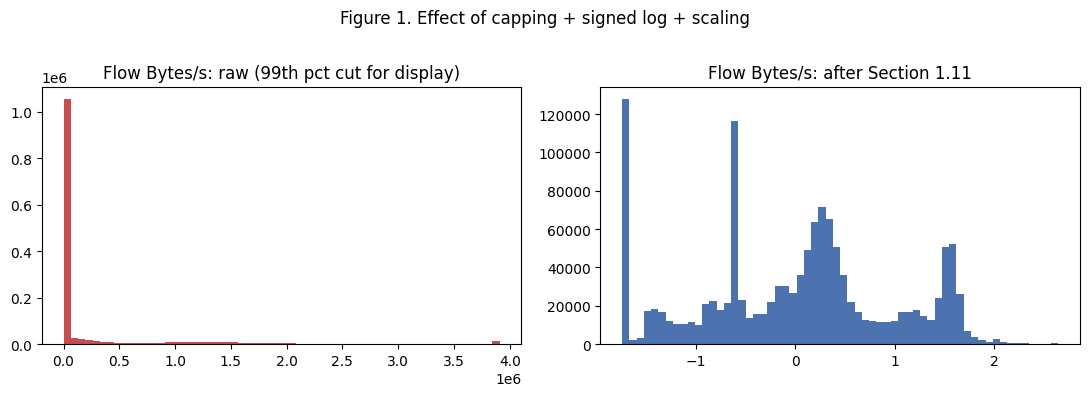

> #### Findings
> | Check | Result |
> |---|---|
> | Features transformed (continuous / binary) | 48 / 11 |
> | Missing indicators added | Flow Bytes/s, Flow Packets/s |
> | Train mean / std after scaling (continuous) | 0.000 / 1.000 |
> | Most-capped features (% of rows) | Flow Packets/s 0.0186%, Active Std 0.0112%, act_data_pkt_fwd 0.011% |
> | Non-finite values left | 0 ✔ |
>
> **Meaning:** all sets are on the same scale, defined by the training data alone.


In [16]:
t0 = time.time()
PARAMS = pl.fit_preprocessing(df.loc[TRAIN], FEATURES_MODEL, winsor_q=WINSOR_Q)
XT = pl.apply_preprocessing(df, PARAMS, passthrough=PORT_FEATURES)
MODEL_COLS = FEATURES_MODEL + [c + "__missing" for c in PARAMS["indicator_cols"]]
assert np.isfinite(XT.to_numpy()).all(), "Non-finite values after transformation"

chk = XT.loc[TRAIN, FEATURES_MODEL]
cont = [c for c in FEATURES_MODEL if c not in PARAMS["binary_cols"]]
clipped = {}
Xr = df[FEATURES_MODEL].to_numpy("float64")
lo, hi = np.asarray(PARAMS["clip_low"]), np.asarray(PARAMS["clip_high"])
clip_share = ((Xr < lo) | (Xr > hi)).mean(0)
CLIP_TABLE = pd.Series(clip_share * 100, index=FEATURES_MODEL).sort_values(ascending=False).head(10).round(4)
del Xr
print(f"({time.time() - t0:.1f} s)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
c0 = "Flow Bytes/s" if "Flow Bytes/s" in FEATURES_MODEL else cont[0]
axes[0].hist(df.loc[TRAIN, c0].dropna().clip(upper=df.loc[TRAIN, c0].quantile(0.99)), bins=60, color="#C44E52")
axes[0].set_title(f"{c0}: raw (99th pct cut for display)")
axes[1].hist(XT.loc[TRAIN, c0], bins=60, color="#4C72B0"); axes[1].set_title(f"{c0}: after Section 1.11")
plt.suptitle("Figure 1. Effect of capping + signed log + scaling"); plt.tight_layout()
plt.savefig(FIG_DIR / "transform_effect.png", dpi=200); plt.show()

findings([
    ("Features transformed (continuous / binary)", f"{len(cont)} / {len(PARAMS['binary_cols'])}"),
    ("Missing indicators added", ", ".join(PARAMS["indicator_cols"]) or "none"),
    ("Train mean / std after scaling (continuous)", f"{chk[cont].mean().abs().max():.3f} / {chk[cont].std().mean():.3f}"),
    ("Most-capped features (% of rows)", ", ".join(f"{k} {v}%" for k, v in CLIP_TABLE.head(3).items())),
    ("Non-finite values left", "0 ✔"),
], "all sets are on the same scale, defined by the training data alone.")
del chk

## 1.12 · Stratified, carefully selected training subsample
**Purpose:** BENIGN, DoS Hulk and DDoS dominate the training set. Training on all of it is slow and lets the large classes swamp the small ones. The subsample is built so that it stays **representative**:

* **Per original label, not per family:** each attack sub-type has its own cap, so e.g. DoS slowloris is not crowded out by DoS Hulk inside the DoS family.
* **Small labels kept whole:** every row of a label below its cap is used.
* **Stratified by capture day (`source_file`):** inside a capped label, each day keeps its share, so the subsample covers all days and traffic conditions instead of whichever day happens to be largest in a random draw.
* **Optional near-duplicate thinning** (`NEAR_DUP_THINNING = True`): within each stratum, one flow per coarse bin of the transformed feature space is taken first, so the budget is spent on *distinct* behaviour rather than thousands of almost identical tool-generated flows. This changes the within-class density, so it is off by default; calibration on the natural-mix `cal` set (Part 2) corrects probability shifts either way.
* **Only `train` is subsampled.** `cal`, `thr` and `test` keep the real class mix, so thresholds and metrics reflect reality.
* **Representativeness is verified** with a Kolmogorov–Smirnov test per feature (subsample vs full training data of the same label).

,train_rows,in_sample,capped
Label,,,
BENIGN,1138241,200000,True
DoS Hulk,103628,50000,True
DDoS,76807,50000,True
DoS GoldenEye,6172,6172,False
FTP-Patator,3560,3560,False
DoS slowloris,3230,3230,False
DoS Slowhttptest,3137,3137,False
SSH-Patator,1931,1931,False
PortScan,1111,1111,False


,label,max_day_share_difference_pp
0,BENIGN,0.0
1,DoS Hulk,0.0
2,DDoS,0.0


,label,median_KS,max_KS,worst_feature
0,BENIGN,0.0043,0.0066,Bwd Packet Length Min
1,DoS Hulk,0.0028,0.0064,Flow Packets/s
2,DDoS,0.0017,0.0032,eng_iat_cv


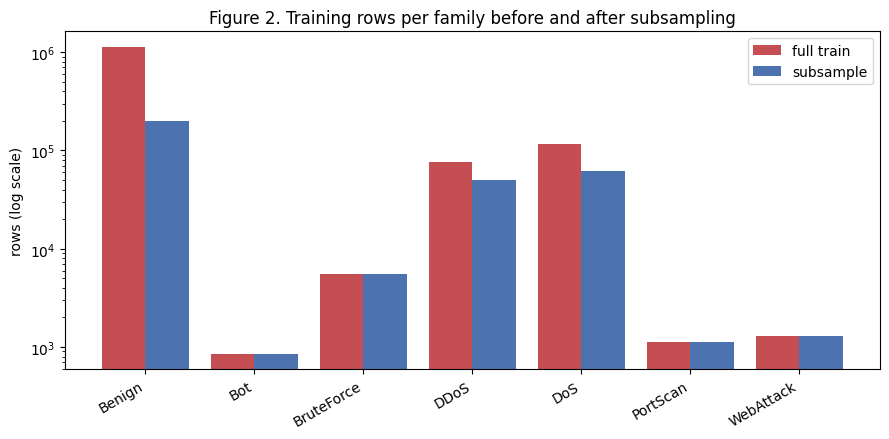

(5.7 s)


> #### Findings
> | Check | Result |
> |---|---|
> | Training rows → subsample | 1,339,953 → 321,277 |
> | Labels capped | BENIGN, DoS Hulk, DDoS |
> | Largest/smallest family ratio | 1,339 : 1 → 235 : 1 |
> | Day shares preserved (max difference) | 0.000 pp |
> | Worst median KS (subsample vs full) | 0.0043 |
> | Near-duplicate thinning | off (distribution-preserving) |
>
> **Meaning:** the subsample is far more balanced but still statistically representative of each label and each day (KS values near 0 mean the distributions match).


In [17]:
t0 = time.time()
def pick(idx, k, r, keys=None):
    if len(idx) <= k: return idx
    if keys is None: return r.choice(idx, size=k, replace=False)
    perm = r.permutation(len(idx)); idx_p, keys_p = idx[perm], keys[perm]
    first = ~pd.Series(keys_p).duplicated().to_numpy()
    return np.concatenate([idx_p[first], idx_p[~first]])[:k]

def alloc(sizes, k):
    """Split a budget k across strata in proportion to size (largest remainder), never above stratum size."""
    sizes = np.asarray(sizes); raw = k * sizes / sizes.sum()
    out = np.minimum(np.floor(raw).astype(int), sizes)
    for i in np.argsort(-(raw - out)):
        if out.sum() >= k: break
        if out[i] < sizes[i]: out[i] += 1
    return out

r = np.random.default_rng(SEED)
tr_df = df.loc[TRAIN, [LABEL_COL, "source_file"]]
keep = []
for lab, grp in sorted(tr_df.groupby(LABEL_COL).groups.items()):
    idx = np.asarray(grp); cap = TRAIN_CAPS.get(lab, TRAIN_CAPS["_default"])
    if len(idx) <= cap:
        keep.append(idx); continue
    strata = tr_df.loc[idx, SUBSAMPLE_STRATA].to_numpy() if SUBSAMPLE_STRATA else np.zeros(len(idx))
    names, inv = np.unique(strata, return_inverse=True)
    budget = alloc(np.bincount(inv), cap)
    for s in range(len(names)):
        sidx = idx[inv == s]
        keys = (pd.util.hash_pandas_object(XT.loc[sidx, FEATURES_MODEL].round(THIN_DECIMALS), index=False).to_numpy()
                if NEAR_DUP_THINNING else None)
        keep.append(pick(sidx, budget[s], r, keys))
SAMPLE_IDX = np.sort(np.concatenate(keep))
df["in_train_sample"] = False
df.loc[SAMPLE_IDX, "in_train_sample"] = True

SUBSAMPLE_TABLE = pd.DataFrame({"train_rows": df.loc[TRAIN, LABEL_COL].value_counts(),
                                "in_sample": df.loc[df["in_train_sample"], LABEL_COL].value_counts()}).fillna(0).astype(int)
SUBSAMPLE_TABLE["capped"] = SUBSAMPLE_TABLE["in_sample"] < SUBSAMPLE_TABLE["train_rows"]
SUBSAMPLE_TABLE = SUBSAMPLE_TABLE.sort_values("train_rows", ascending=False)
display(SUBSAMPLE_TABLE)

# Day coverage check for capped labels
capped = SUBSAMPLE_TABLE.index[SUBSAMPLE_TABLE["capped"]].tolist()
DAY_SHARE = []
for lab in capped:
    full = df.loc[TRAIN & (df[LABEL_COL] == lab).to_numpy(), "source_file"].value_counts(normalize=True)
    sub = df.loc[df["in_train_sample"] & (df[LABEL_COL] == lab), "source_file"].value_counts(normalize=True)
    DAY_SHARE.append({"label": lab, "max_day_share_difference_pp": round(100 * (full - sub.reindex(full.index).fillna(0)).abs().max(), 3)})
display(pd.DataFrame(DAY_SHARE))

# Representativeness (KS) for capped labels
REP = []
for lab in capped:
    full_idx = np.flatnonzero(TRAIN & (df[LABEL_COL] == lab).to_numpy())
    full_idx = r.choice(full_idx, size=min(50_000, len(full_idx)), replace=False)
    sub_idx = np.flatnonzero((df["in_train_sample"] & (df[LABEL_COL] == lab)).to_numpy())
    sub_idx = r.choice(sub_idx, size=min(50_000, len(sub_idx)), replace=False)
    ks = [ks_2samp(XT[c].to_numpy()[full_idx], XT[c].to_numpy()[sub_idx]).statistic for c in cont]
    REP.append({"label": lab, "median_KS": round(float(np.median(ks)), 4), "max_KS": round(float(np.max(ks)), 4),
                "worst_feature": cont[int(np.argmax(ks))]})
REP = pd.DataFrame(REP); display(REP)

fam_before = df.loc[TRAIN, TARGET_COL].value_counts()
fam_after = df.loc[df["in_train_sample"], TARGET_COL].value_counts()
fig, ax = plt.subplots(figsize=(9, 4.5)); xs = np.arange(len(MAIN_CLASSES)); w = 0.4
ax.bar(xs - w/2, fam_before.reindex(MAIN_CLASSES), w, label="full train", color="#C44E52")
ax.bar(xs + w/2, fam_after.reindex(MAIN_CLASSES), w, label="subsample", color="#4C72B0")
ax.set_yscale("log"); ax.set_xticks(xs); ax.set_xticklabels(MAIN_CLASSES, rotation=30, ha="right")
ax.set_ylabel("rows (log scale)"); ax.legend(); ax.set_title("Figure 2. Training rows per family before and after subsampling")
plt.tight_layout(); plt.savefig(FIG_DIR / "subsample_balance.png", dpi=200); plt.show()
print(f"({time.time() - t0:.1f} s)")

ratio_before = fam_before.max() / fam_before.min(); ratio_after = fam_after.max() / fam_after.min()
findings([
    ("Training rows → subsample", f"{int(TRAIN.sum()):,} → {len(SAMPLE_IDX):,}"),
    ("Labels capped", ", ".join(capped) or "none"),
    ("Largest/smallest family ratio", f"{ratio_before:,.0f} : 1 → {ratio_after:,.0f} : 1"),
    ("Day shares preserved (max difference)", f"{max([d['max_day_share_difference_pp'] for d in DAY_SHARE], default=0):.3f} pp"),
    ("Worst median KS (subsample vs full)", f"{REP['median_KS'].max():.4f}" if len(REP) else "n/a"),
    ("Near-duplicate thinning", "on" if NEAR_DUP_THINNING else "off (distribution-preserving)"),
], ("the subsample is far more balanced but still statistically representative of each label and each day "
    "(KS values near 0 mean the distributions match)." if capped else
    "no label exceeded its cap, so the whole training set is used."))

## 1.13 · Class imbalance: weights and SMOTE
Even after capping, small classes such as Bot, PortScan and WebAttack are hundreds of times smaller than Benign. Two standard remedies are prepared, class weights and SMOTE (Chawla *et al.*, 2002), and **Part 2 compares them** rather than this part choosing one:

| Option | What it does | Risk |
|---|---|---|
| **Class weights** | errors on rare classes cost more during training (`balanced` = n / (K·nₖ); a softer square-root version is also saved) | can raise false positives; handled by calibration and threshold tuning |
| **SMOTE** | creates synthetic minority flows by interpolating between real neighbours, in the transformed feature space | synthetic flows may be unrealistic; with only 13 SQL-injection rows they are near-copies of a handful of flows |

Rules that keep this honest: SMOTE is applied **only to the training subsample, after the split** (never before; otherwise synthetic copies of test flows leak into training); synthetic rows are marked `is_synthetic`; binary features are rounded back to 0/1; `cal`, `thr` and `test` are never resampled.

In [18]:
y_s = df.loc[df["in_train_sample"], TARGET_COL].to_numpy()
cw = compute_class_weight("balanced", classes=np.array(MAIN_CLASSES), y=y_s)
CLASS_WEIGHTS = {"balanced": dict(zip(MAIN_CLASSES, np.round(cw, 4))),
                 "sqrt_balanced": dict(zip(MAIN_CLASSES, np.round(np.sqrt(cw), 4))),
                 "by_label_id": {CLASS_MAP[k]: float(round(v, 4)) for k, v in zip(MAIN_CLASSES, cw)}}
display(pd.DataFrame({k: v for k, v in CLASS_WEIGHTS.items() if k != "by_label_id"}))

SMOTE_TABLE, TRAIN_SMOTE = pd.DataFrame(), None
if IMBALANCE_STRATEGY in {"smote", "both"}:
    from imblearn.over_sampling import SMOTE
    S = df["in_train_sample"].to_numpy()
    Xs = XT.loc[S, MODEL_COLS].to_numpy("float32")
    ys = df.loc[S, LABEL_COL].to_numpy()
    counts = pd.Series(ys).value_counts()
    target = {lab: SMOTE_MIN_PER_LABEL for lab, n in counts.items() if n < SMOTE_MIN_PER_LABEL}
    if target:
        k = int(min(SMOTE_K, counts[list(target)].min() - 1))
        sm = SMOTE(sampling_strategy=target, k_neighbors=k, random_state=SEED)
        Xr, yr = sm.fit_resample(Xs, ys)
        n_new = len(yr) - len(ys)
        bin_cols = [i for i, c in enumerate(MODEL_COLS) if c in PARAMS["binary_cols"] or c.endswith("__missing")]
        Xr[len(ys):, bin_cols] = np.clip(np.round(Xr[len(ys):, bin_cols]), 0, 1)
        TRAIN_SMOTE = pd.DataFrame(Xr, columns=MODEL_COLS)
        TRAIN_SMOTE[LABEL_COL] = yr
        TRAIN_SMOTE[TARGET_COL] = TRAIN_SMOTE[LABEL_COL].map(FAMILY_MAP)
        TRAIN_SMOTE["label_id"] = TRAIN_SMOTE[TARGET_COL].map(CLASS_MAP).astype("int16")
        TRAIN_SMOTE["is_attack"] = (TRAIN_SMOTE[LABEL_COL] != "BENIGN").astype("int8")
        TRAIN_SMOTE["is_synthetic"] = np.r_[np.zeros(len(ys), bool), np.ones(n_new, bool)]
        SMOTE_TABLE = pd.DataFrame({"real": counts, "after_smote": pd.Series(yr).value_counts()}).fillna(0).astype(int)
        SMOTE_TABLE["synthetic"] = SMOTE_TABLE["after_smote"] - SMOTE_TABLE["real"]
        display(SMOTE_TABLE[SMOTE_TABLE["synthetic"] > 0])
        del Xs, Xr
findings([
    ("Strategy", IMBALANCE_STRATEGY),
    ("Highest balanced weight", f"{max(CLASS_WEIGHTS['balanced'], key=CLASS_WEIGHTS['balanced'].get)} "
                                f"({max(CLASS_WEIGHTS['balanced'].values()):.1f})"),
    ("SMOTE: labels oversampled", ", ".join(SMOTE_TABLE.index[SMOTE_TABLE["synthetic"] > 0]) if len(SMOTE_TABLE) else "not used"),
    ("SMOTE: synthetic rows", f"{int(SMOTE_TABLE['synthetic'].sum()):,}" if len(SMOTE_TABLE) else "0"),
], "both remedies affect training only. Report per-class recall and false-positive rate for each option in Part 2; "
   "a gain from SMOTE on classes with very few real flows should be treated with caution.")

,balanced,sqrt_balanced
Benign,0.2295,0.4790
Bot,53.9961,7.3482
BruteForce,8.3585,2.8911
DDoS,0.9179,0.9581
DoS,0.7339,0.8567
PortScan,41.3112,6.4274
WebAttack,35.6895,5.9741


,real,after_smote,synthetic
Bot,850,2000,1150
PortScan,1111,2000,889
SSH-Patator,1931,2000,69
Web Attack - Brute Force,882,2000,1118
Web Attack - Sql Injection,13,2000,1987
Web Attack - XSS,391,2000,1609


> #### Findings
> | Check | Result |
> |---|---|
> | Strategy | both |
> | Highest balanced weight | Bot (54.0) |
> | SMOTE: labels oversampled | Bot, PortScan, SSH-Patator, Web Attack - Brute Force, Web Attack - Sql Injection, Web Attack - XSS |
> | SMOTE: synthetic rows | 6,822 |
>
> **Meaning:** both remedies affect training only. Report per-class recall and false-positive rate for each option in Part 2; a gain from SMOTE on classes with very few real flows should be treated with caution.


## 1.14 · Evaluation subsets
**Purpose:** some later steps are expensive: generating adversarial examples, computing SHAP values (for every flow, before and after attack) and, above all, calling LLM agents (token cost, O4). These run on **fixed, nested, stratified subsets**, so every configuration in Parts 3–5 is compared on exactly the same flows:

| Subset | Drawn from | Size | Used for |
|---|---|---|---|
| `thr-lite` | `thr` | ≤ 300 per family | tuning the confidence-aware mechanism under attack (Part 4) |
| `test-lite` | `test` | ≤ 300 per family | attacks, SHAP stability, final evaluation of non-LLM configurations (Parts 3–5) |
| `agent-eval` | **inside** `test-lite` | ≤ 50 per family | all LLM / multi-agent configurations (Part 5) |

Families are balanced (equal budget) so macro-F1 is not dominated by Benign, and each sub-type keeps at least 5 flows, so rare attacks such as SQL injection are always present. Because the subsets are balanced, precision on them is higher than in the natural traffic mix; non-LLM configurations are therefore **also** reported on the full natural-mix `test` set.

In [19]:
def stratified_subset(pool_mask, per_family, min_per_label, seed):
    r = np.random.default_rng(seed)
    pool = df.loc[pool_mask, [LABEL_COL, TARGET_COL]]
    keep = []
    for fam_name, g in pool.groupby(TARGET_COL):
        labs = g[LABEL_COL].value_counts()
        n = min(len(g), per_family)
        floor = np.minimum(labs.to_numpy(), min_per_label)
        if floor.sum() >= n:
            take = floor
        else:
            spare = labs.to_numpy() - floor
            take = floor + (alloc(spare, n - floor.sum()) if spare.sum() > 0 else 0)
        for lab, k in zip(labs.index, np.atleast_1d(take)):
            keep.append(r.choice(g.index[g[LABEL_COL] == lab].to_numpy(), size=int(k), replace=False))
    return np.sort(np.concatenate(keep))

THR_LITE  = stratified_subset((df["split"] == "thr").to_numpy(), LITE_PER_FAMILY, LITE_MIN_PER_LABEL, SEED)
TEST_LITE = stratified_subset((df["split"] == "test").to_numpy(), LITE_PER_FAMILY, LITE_MIN_PER_LABEL, SEED)
in_test_lite = df.index.isin(TEST_LITE)
AGENT = stratified_subset(in_test_lite, AGENT_PER_FAMILY, LITE_MIN_PER_LABEL, SEED + 1)
for name, idx in [("in_thr_lite", THR_LITE), ("in_test_lite", TEST_LITE), ("in_agent_eval", AGENT)]:
    df[name] = df.index.isin(idx)

SUBSETS = pd.DataFrame({
    "thr-lite": df.loc[df["in_thr_lite"], TARGET_COL].value_counts(),
    "test-lite": df.loc[df["in_test_lite"], TARGET_COL].value_counts(),
    "agent-eval": df.loc[df["in_agent_eval"], TARGET_COL].value_counts(),
}).fillna(0).astype(int).loc[MAIN_CLASSES]
SUBSETS.loc["total"] = SUBSETS.sum()
display(SUBSETS)
display(pd.crosstab(df.loc[df["in_test_lite"], LABEL_COL], "test-lite flows").T)
findings([
    ("thr-lite / test-lite / agent-eval", " / ".join(f"{int(SUBSETS.loc['total', c]):,}" for c in SUBSETS.columns)),
    ("agent-eval inside test-lite", "yes ✔" if df.loc[df["in_agent_eval"], "in_test_lite"].all() else "✘"),
    ("Unseen-family flows (all used)", f"{int((df['split'] == 'unseen').sum())}"),
], "all expensive experiments share the same flows; the LLM configurations use a nested subset small enough to "
   "afford, so token cost can be compared directly with the non-LLM configurations.")

,thr-lite,test-lite,agent-eval
label_family,,,
Benign,300,300,50
Bot,141,283,50
BruteForce,300,300,50
DDoS,300,300,50
DoS,300,300,50
PortScan,185,300,50
WebAttack,214,300,50
total,1740,2083,350


Label,BENIGN,Bot,DDoS,DoS GoldenEye,DoS Hulk,DoS Slowhttptest,DoS slowloris,FTP-Patator,PortScan,SSH-Patator,Web Attack - Brute Force,Web Attack - Sql Injection,Web Attack - XSS
col_0,,,,,,,,,,,,,
test-lite flows,300,283,300,20,255,12,13,193,300,107,205,4,91


> #### Findings
> | Check | Result |
> |---|---|
> | thr-lite / test-lite / agent-eval | 1,740 / 2,083 / 350 |
> | agent-eval inside test-lite | yes ✔ |
> | Unseen-family flows (all used) | 47 |
>
> **Meaning:** all expensive experiments share the same flows; the LLM configurations use a nested subset small enough to afford, so token cost can be compared directly with the non-LLM configurations.


## 1.15 · Threat model: the attacker-controllable feature space (O1)
**Purpose:** an adversarial example is only meaningful if a real attacker could produce it. CICIDS2017 features are computed *from packets*, so an attacker can only influence them through the packets they send. Following the problem-space view of realistic network attacks (e.g. Apruzzese et al., 2022; Teuffenbach et al., 2020), each feature gets one role:

| Role | Meaning | Examples |
|---|---|---|
| **controllable** | the attacker can change it by changing *their own* traffic | forward packet count and sizes (padding, extra packets), forward inter-arrival times and duration (delays), forward header length (TCP options), initial TCP window |
| **dependent** | a formula of other features, so it changes *only* as a consequence | rates (`Flow Bytes/s`), means (`Fwd Packet Length Mean`), subflow copies, engineered features |
| **uncontrollable** | decided by the victim/server or by the protocol | everything in the backward (server → client) direction, TCP flag semantics, destination port of the targeted service |

**Attacker assumptions** (stated for the report): the attacker controls the client side of the flow; they can **add** (padding, extra packets, delays) but cannot **remove** what the attack needs, so totals, maxima and durations may only *increase* (minima and standard deviations may move both ways, because extra small packets lower a minimum); values stay within the 99.9% training quantile (plausible traffic); counts and byte sizes stay integers; the −1 "not recorded" code is never changed.

`project_to_threat_model(original, proposed, spec)` enforces all of this: any attack in Part 3 proposes changes, and this function turns them into a realistic flow (dependent features recomputed, ordering rules such as *max ≥ mean ≥ min* restored).

In [20]:
CONTROLLABLE = {   # feature: (direction, integer, reason)
    "Flow Duration":               ("increase", False, "attacker can delay packets"),
    "Total Fwd Packets":           ("increase", True,  "attacker can send extra (dummy) packets"),
    "Total Length of Fwd Packets": ("increase", True,  "attacker can pad payloads"),
    "Fwd Packet Length Max":       ("increase", True,  "padding"),
    "Fwd Packet Length Min":       ("any",      True,  "padding raises it, small dummy packets lower it"),
    "Fwd Packet Length Std":       ("any",      False, "mixing padded and unpadded packets"),
    "Fwd IAT Total":               ("increase", False, "delays between own packets"),
    "Fwd IAT Max":                 ("increase", False, "delays"),
    "Fwd IAT Min":                 ("any",      False, "delays raise it, extra packets can lower it"),
    "Fwd IAT Std":                 ("any",      False, "irregular delays (jitter)"),
    "Fwd Header Length":           ("increase", True,  "TCP/IP options"),
    "act_data_pkt_fwd":            ("increase", True,  "extra packets with payload"),
    "Init_Win_bytes_forward":      ("any",      True,  "client chooses its TCP window"),
}
SPECIAL_BOUNDS = {"Init_Win_bytes_forward": (0.0, 65535.0)}
SENTINEL = {"Init_Win_bytes_forward": -1.0}
DEPENDENT = set(pl.FORMULAS) | set(FEATURES_ENG) | {"Max Packet Length", "Min Packet Length", "Packet Length Variance",
                                                     "Flow IAT Max", "Flow IAT Min", "Flow IAT Std", "Fwd IAT Mean"}

CTRL_PRESENT = [c for c in CONTROLLABLE if c in df.columns]
q_hi = df.loc[TRAIN, CTRL_PRESENT].quantile(BOUND_QUANTILE)
spec_rows = {}
for c in FEATURES_RAW + FEATURES_ENG:
    if c in CONTROLLABLE and c in df.columns:
        direction, integer, reason = CONTROLLABLE[c]
        lo, hi = SPECIAL_BOUNDS.get(c, (0.0, float(q_hi[c])))
        spec_rows[c] = dict(role="controllable", direction=direction, integer=integer, low=lo, high=hi,
                            keep_sentinel=SENTINEL.get(c), reason=reason)
    elif c in DEPENDENT:
        spec_rows[c] = dict(role="dependent", direction="derived", integer=False, low=None, high=None,
                            keep_sentinel=None, reason="formula of other features" if c in pl.FORMULAS or c in FEATURES_ENG
                                                       else "follows ordering rules (max/min/variance)")
    else:
        why = ("server / backward direction" if re.search(r"Bwd|Backward|backward", c) else
               "destination service" if c == PORT_COL else "protocol semantics or not attacker-driven")
        spec_rows[c] = dict(role="uncontrollable", direction="fixed", integer=False, low=None, high=None,
                            keep_sentinel=None, reason=why)
THREAT_SPEC = {"features": spec_rows, "bound_quantile": BOUND_QUANTILE,
               "assumptions": ["attacker controls the client (forward) side only",
                               "attacker can add padding, packets and delays but not remove attack content",
                               "values stay within the training 99.9% quantile",
                               "counts and byte sizes stay integers; the -1 code is never changed",
                               "dependent features are recomputed relatively; standard deviations are approximate"]}
SPEC_TABLE = pd.DataFrame(spec_rows).T
SPEC_TABLE["in_model"] = SPEC_TABLE.index.isin(FEATURES_MODEL)
display(SPEC_TABLE.loc[SPEC_TABLE.role == "controllable", ["direction", "integer", "low", "high", "reason"]])
ROLE_COUNTS = pd.crosstab(SPEC_TABLE["role"], SPEC_TABLE["in_model"].map({True: "model feature", False: "not in model"}))
display(ROLE_COUNTS)

,direction,integer,low,high,reason
Flow Duration,increase,False,0.0,119866793.624,attacker can delay packets
Total Fwd Packets,increase,True,0.0,327.048,attacker can send extra (dummy) packets
Total Length of Fwd Packets,increase,True,0.0,43906.0,attacker can pad payloads
Fwd Packet Length Max,increase,True,0.0,10135.0,padding
Fwd Packet Length Min,any,True,0.0,1375.0,"padding raises it, small dummy packets lower it"
Fwd Packet Length Std,any,False,0.0,4060.245892,mixing padded and unpadded packets
Fwd IAT Total,increase,False,0.0,120000000.0,delays between own packets
Fwd IAT Std,any,False,0.0,56900000.0,irregular delays (jitter)
Fwd IAT Max,increase,False,0.0,117000000.0,delays
Fwd IAT Min,any,False,0.0,113000000.0,"delays raise it, extra packets can lower it"


in_model,model feature,not in model
role,,
controllable,12,1
dependent,24,9
uncontrollable,23,12


**Validation of the threat model.** Three tests, so the attacks in Part 3 rest on a checked implementation:
1. **Identity:** projecting an unchanged flow must return it exactly.
2. **Formula fit:** each dependent-feature formula is compared with the real values in the data. A good fit means the formula captures the true relationship; a poor fit is reported as *approximate* (the relative update still moves the value correctly).
3. **Random attack:** every attack flow in `test-lite` gets random changes of up to ±20% on its controllable features; after projection, all constraints must hold.

In [21]:
t0 = time.time()
TL = df.loc[df["in_test_lite"], FEATURES_RAW + FEATURES_ENG].copy()

# 1. Identity
same, ch = pl.project_to_threat_model(TL, TL, THREAT_SPEC)
identity_ok = (not ch.any()) and np.allclose(same.to_numpy("float64"), TL.to_numpy("float64"), equal_nan=True)

# 2. Formula fit on real flows
FIT = []
for col, f in pl.FORMULAS.items():
    if col not in TL.columns: continue
    try:
        est = f(TL)
    except KeyError:
        continue
    real = TL[col].to_numpy("float64"); ok = np.isfinite(real) & np.isfinite(est)
    rel = np.abs(est[ok] - real[ok]) / np.maximum(np.abs(real[ok]), 1e-9)
    FIT.append({"dependent_feature": col, "median_rel_error": round(float(np.median(rel)), 4),
                "%_within_1%": round(100 * float((rel <= 0.01).mean()), 1)})
FIT = pd.DataFrame(FIT).sort_values("%_within_1%")
FIT["fit"] = np.where(FIT["%_within_1%"] >= 90, "exact", "approximate")
display(FIT)

# 3. Random attack on attack flows
atk = df.loc[TL.index, LABEL_COL].ne("BENIGN").to_numpy()
A = TL.loc[atk]
r = np.random.default_rng(SEED)
prop = A.copy()
for c in CONTROLLABLE:
    if c in prop.columns:
        prop[c] = prop[c] * (1 + r.uniform(-DEMO_BUDGET, DEMO_BUDGET, len(prop)))
adv, changed = pl.project_to_threat_model(A, prop, THREAT_SPEC)

viol = {}
for c, s in THREAT_SPEC["features"].items():
    if c not in adv.columns: continue
    o, n = A[c].to_numpy("float64"), adv[c].to_numpy("float64")
    if s["role"] == "uncontrollable":
        viol[f"{c} changed (uncontrollable)"] = int((~np.isclose(o, n, equal_nan=True)).sum())
    elif s["role"] == "controllable":
        if s["direction"] == "increase": viol[f"{c} decreased"] = int((n < o - 1e-9).sum())
        if s["integer"]: viol[f"{c} non-integer"] = int(((np.abs(n - np.round(n)) > 1e-9) & (n != o)).sum())
        viol[f"{c} out of bounds"] = int(((n < s["low"] - 1e-9) & (n != o)).sum() + ((n > max(s["high"], 0) + 1e-9) & (n > o)).sum())
for a, op, b in pl.ORDER_RULES:
    if a in adv.columns and b in adv.columns:
        oa, ob = A[a].to_numpy("float64"), A[b].to_numpy("float64")
        held = (oa >= ob - 1e-6) if op == ">=" else (oa <= ob + 1e-6)      # rule held in the original flow
        va, vb = adv[a].to_numpy("float64"), adv[b].to_numpy("float64")
        bad = (va < vb - 1e-6) if op == ">=" else (va > vb + 1e-6)
        viol[f"{a} {op} {b}"] = int((bad & held & changed).sum())
VIOL = pd.Series(viol); n_viol = int(VIOL.sum())
display(VIOL[VIOL > 0].to_frame("violations") if n_viol else Markdown("*No constraint violations.*"))

moved = (adv[CTRL_PRESENT] - A[CTRL_PRESENT]).abs().gt(0).mean().mul(100).round(1)
display(moved.to_frame("% of attack flows changed by the random attack"))
print(f"({time.time() - t0:.1f} s)")

ctrl_in_model = SPEC_TABLE[(SPEC_TABLE.role == "controllable") & SPEC_TABLE.in_model].index.tolist()
dep_in_model = SPEC_TABLE[(SPEC_TABLE.role == "dependent") & SPEC_TABLE.in_model].index.tolist()
findings([
    ("Controllable / dependent / uncontrollable features",
     " / ".join(str(int((SPEC_TABLE.role == k).sum())) for k in ["controllable", "dependent", "uncontrollable"])),
    ("Model features the attacker can move (directly / via formulas)", f"{len(ctrl_in_model)} / {len(dep_in_model)} of {len(FEATURES_MODEL)}"),
    ("Identity test", "pass ✔" if identity_ok else "✘ FAIL"),
    ("Dependent formulas exact / approximate", f"{int((FIT.fit == 'exact').sum())} / {int((FIT.fit == 'approximate').sum())}"),
    ("Random-attack flows changed", f"{int(changed.sum()):,} of {len(A):,}"),
    ("Constraint violations after projection", "0 ✔" if n_viol == 0 else f"{n_viol} ✘"),
], "the attacker's reach is limited to a defined part of the feature space, and every perturbation produced through "
   "`project_to_threat_model` is realistic by construction. Approximate formulas are a stated limitation.")
del TL, same, prop

,dependent_feature,median_rel_error,%_within_1%,fit
3,Packet Length Mean,0.0709,30.1,approximate
9,Down/Up Ratio,0.6667,35.9,approximate
4,Average Packet Size,0.0000,75.0,approximate
1,Avg Fwd Segment Size,0.0000,100.0,exact
2,Subflow Fwd Bytes,0.0000,100.0,exact
5,Flow Bytes/s,0.0000,100.0,exact
6,Flow Packets/s,0.0000,100.0,exact
0,Fwd Packet Length Mean,0.0000,100.0,exact
7,Fwd Packets/s,0.0000,100.0,exact
8,Bwd Packets/s,0.0000,100.0,exact


*No constraint violations.*

,% of attack flows changed by the random attack
Flow Duration,49.4
Total Fwd Packets,50.1
Total Length of Fwd Packets,31.5
Fwd Packet Length Max,33.7
Fwd Packet Length Min,6.0
Fwd Packet Length Std,56.9
Fwd IAT Total,34.3
Fwd IAT Max,45.7
Fwd IAT Min,87.5
Fwd IAT Std,81.3


(0.5 s)


> #### Findings
> | Check | Result |
> |---|---|
> | Controllable / dependent / uncontrollable features | 13 / 33 / 35 |
> | Model features the attacker can move (directly / via formulas) | 12 / 24 of 59 |
> | Identity test | pass ✔ |
> | Dependent formulas exact / approximate | 9 / 3 |
> | Random-attack flows changed | 1,783 of 1,783 |
> | Constraint violations after projection | 0 ✔ |
>
> **Meaning:** the attacker's reach is limited to a defined part of the feature space, and every perturbation produced through `project_to_threat_model` is realistic by construction. Approximate formulas are a stated limitation.


## 1.16 · Feature dictionary and feature groups
**Purpose:** many CICIDS2017 features measure the same thing in different ways (Section E8 shows the clusters). SHAP credit is then split between related features, and a ranking can "change" only because credit moves between two near-copies. Measuring SHAP stability **per feature group** as well as per feature (O1, O2) avoids over-stating instability. The dictionary also gives each feature a readable description and unit, which the LLM agents in Part 5 receive as evidence instead of raw column names.

In [22]:
GROUP_RULES = [   # (regex, group, unit, description)
    (r"^eng_",                                   "engineered",   "ratio/flag", "engineered behavioural feature (Section 1.6)"),
    (r"Destination Port|^port_",                 "port",         "category",   "destination service port"),
    (r"Bulk",                                    "bulk",         "bytes/packets", "bulk-transfer statistics"),
    (r"/s$",                                     "rate",         "per second", "rate over the flow duration"),
    (r"Flag",                                    "tcp_flags",    "count",      "TCP flag counts"),
    (r"Init_Win",                                "tcp_window",   "bytes",      "initial TCP window size"),
    (r"Header Length|min_seg_size",              "header",       "bytes",      "header size"),
    (r"^Fwd IAT",                                "timing_fwd",   "µs",         "time between forward packets"),
    (r"^Bwd IAT",                                "timing_bwd",   "µs",         "time between backward packets"),
    (r"^Flow IAT|Flow Duration",                 "timing_flow",  "µs",         "flow duration / time between packets"),
    (r"^Active|^Idle",                           "activity",     "µs",         "active and idle periods"),
    (r"Total Fwd Packets|Subflow Fwd Packets|act_data_pkt_fwd", "count_fwd", "packets", "forward packet count"),
    (r"Total Backward Packets|Subflow Bwd Packets", "count_bwd",  "packets",    "backward packet count"),
    (r"Fwd Packet Length|Length of Fwd|Avg Fwd Segment|Subflow Fwd Bytes", "size_fwd", "bytes", "forward packet sizes"),
    (r"Bwd Packet Length|Length of Bwd|Avg Bwd Segment|Subflow Bwd Bytes", "size_bwd", "bytes", "backward packet sizes"),
    (r"Packet Length|Packet Size",               "size_flow",    "bytes",      "packet sizes over the whole flow"),
    (r"Down/Up",                                 "ratio",        "ratio",      "download / upload packet ratio"),
]
STAT = [(r"Max", "maximum"), (r"Min", "minimum"), (r"Mean|Avg|Average", "mean"), (r"Std", "standard deviation"),
        (r"Variance", "variance"), (r"Total|Subflow", "total")]
rows = []
for c in FEATURES_RAW + FEATURES_ENG + PORT_FEATURES:
    grp, unit, desc = next(((g, u, d) for rx, g, u, d in GROUP_RULES if re.search(rx, c)), ("other", "", "flow statistic"))
    stat = next((s for rx, s in STAT if re.search(rx, c)), "")
    spec = THREAT_SPEC["features"].get(c, {"role": "uncontrollable" if c in PORT_FEATURES else "n/a"})
    rows.append({"feature": c, "group": grp, "statistic": stat, "unit": unit,
                 "description": f"{stat + ' of ' if stat else ''}{desc}",
                 "attacker_role": spec["role"], "in_model": c in FEATURES_MODEL,
                 "status": SELECTION.set_index("feature")["status"].get(c, "port ablation set" if c in PORT_FEATURES else "kept")})
FEATURE_DICT = pd.DataFrame(rows)
display(FEATURE_DICT.head(12))
GROUP_TABLE = FEATURE_DICT[FEATURE_DICT.in_model].groupby("group").agg(
    model_features=("feature", "size"), controllable=("attacker_role", lambda s: int((s == "controllable").sum())),
    dependent=("attacker_role", lambda s: int((s == "dependent").sum()))).sort_values("model_features", ascending=False)
display(GROUP_TABLE)
FEATURE_GROUPS = FEATURE_DICT[FEATURE_DICT.in_model].groupby("group")["feature"].apply(list).to_dict()
findings([
    ("Features described", f"{len(FEATURE_DICT)}"),
    ("Feature groups (model features)", f"{len(GROUP_TABLE)}"),
    ("Groups the attacker can influence", ", ".join(GROUP_TABLE.index[(GROUP_TABLE.controllable + GROUP_TABLE.dependent) > 0])),
    ("Groups fully out of the attacker's reach", ", ".join(GROUP_TABLE.index[(GROUP_TABLE.controllable + GROUP_TABLE.dependent) == 0]) or "none"),
], "SHAP stability can now be measured per feature and per group; groups outside the attacker's reach are expected to "
   "keep their importance under attack, which is a useful check in Part 3.")

,feature,group,statistic,unit,description,attacker_role,in_model,status
0,Destination Port,port,,category,destination service port,uncontrollable,False,kept
1,Flow Duration,timing_flow,,µs,flow duration / time between packets,controllable,True,kept
2,Total Fwd Packets,count_fwd,total,packets,total of forward packet count,controllable,True,kept
3,Total Backward Packets,count_bwd,total,packets,total of backward packet count,uncontrollable,True,kept
4,Total Length of Fwd Packets,size_fwd,total,bytes,total of forward packet sizes,controllable,True,kept
5,Total Length of Bwd Packets,size_bwd,total,bytes,total of backward packet sizes,uncontrollable,True,kept
6,Fwd Packet Length Max,size_fwd,maximum,bytes,maximum of forward packet sizes,controllable,True,kept
7,Fwd Packet Length Min,size_fwd,minimum,bytes,minimum of forward packet sizes,controllable,True,kept
8,Fwd Packet Length Mean,size_fwd,mean,bytes,mean of forward packet sizes,dependent,True,kept
9,Fwd Packet Length Std,size_fwd,standard deviation,bytes,standard deviation of forward packet sizes,controllable,True,kept


,model_features,controllable,dependent
group,,,
engineered,14,0,14
tcp_flags,7,0,0
size_fwd,5,4,1
size_bwd,4,0,0
size_flow,4,0,3
activity,4,0,0
header,3,1,0
timing_bwd,3,0,0
timing_flow,3,1,2


> #### Findings
> | Check | Result |
> |---|---|
> | Features described | 84 |
> | Feature groups (model features) | 15 |
> | Groups the attacker can influence | engineered, size_fwd, size_flow, header, timing_flow, timing_fwd, rate, count_fwd, tcp_window, ratio |
> | Groups fully out of the attacker's reach | tcp_flags, size_bwd, activity, timing_bwd, count_bwd |
>
> **Meaning:** SHAP stability can now be measured per feature and per group; groups outside the attacker's reach are expected to keep their importance under attack, which is a useful check in Part 3.


## 1.17 · Final checks
If any check fails the notebook stops.

In [23]:
main = (df["split"] != "unseen").to_numpy()
hashes = {s: set(df.loc[df["split"] == s, "feature_hash"]) for s in SPLIT_ORDER}
OVERLAP = {f"{a} ∩ {b}": len(hashes[a] & hashes[b]) for i, a in enumerate(SPLIT_ORDER) for b in SPLIT_ORDER[i + 1:]}
del hashes
checks = {
    "every row in exactly one set": bool(df["split"].isin(SPLIT_ORDER).all()),
    "no identical flows across sets": sum(OVERLAP.values()) == 0,
    "no identical feature vectors anywhere": bool(df["feature_hash"].is_unique),
    "subsample lies inside train": bool((df.loc[df["in_train_sample"], "split"] == "train").all()),
    "unseen families only in unseen set": not df.loc[main, TARGET_COL].isin(HOLDOUT_FAMILIES).any(),
    "every learned family in every set": bool((SPLIT_BY_FAMILY.loc[MAIN_CLASSES, ["train", "cal", "thr", "test"]] > 0).all().all()),
    "no NaN / inf in model-ready data": bool(np.isfinite(XT.to_numpy()).all()),
    "no negatives outside -1 code columns": not any((df[c] < 0).any() for c in FEATURES_RAW if c not in SENTINEL_COLS),
    "transform fitted on train only": len(PARAMS["median"]) == len(FEATURES_MODEL),
    "SMOTE rows only in the SMOTE training file": TRAIN_SMOTE is None or bool(TRAIN_SMOTE["is_synthetic"].any()),
    "row count matches the log": len(df) == CLEANING_LOG[-1]["rows_after"],
    "thr-lite inside thr, test-lite inside test": bool((df.loc[df["in_thr_lite"], "split"] == "thr").all()
                                                       and (df.loc[df["in_test_lite"], "split"] == "test").all()),
    "agent-eval inside test-lite": bool(df.loc[df["in_agent_eval"], "in_test_lite"].all()),
    "every learned family in every subset": bool((SUBSETS.loc[MAIN_CLASSES] > 0).all().all()),
    "threat model covers every model feature": all(c in THREAT_SPEC["features"] for c in FEATURES_MODEL),
    "threat model identity test": bool(identity_ok),
    "no constraint violations in random attack": n_viol == 0,
}
display(pd.DataFrame([(k, "✔ pass" if v else "✘ FAIL") for k, v in checks.items()], columns=["check", "result"]))
assert all(checks.values()), "A final check failed. See the table above."
findings([("Checks passed", f"{sum(checks.values())} of {len(checks)}"), ("Final rows", f"{len(df):,}")])

,check,result
0,every row in exactly one set,✔ pass
1,no identical flows across sets,✔ pass
2,no identical feature vectors anywhere,✔ pass
3,subsample lies inside train,✔ pass
4,unseen families only in unseen set,✔ pass
5,every learned family in every set,✔ pass
6,no NaN / inf in model-ready data,✔ pass
7,no negatives outside -1 code columns,✔ pass
8,transform fitted on train only,✔ pass
9,SMOTE rows only in the SMOTE training file,✔ pass


> #### Findings
> | Check | Result |
> |---|---|
> | Checks passed | 17 of 17 |
> | Final rows | 2,233,302 |


## 1.18 · Saved outputs

In [24]:
META_OUT = [LABEL_COL, TARGET_COL, "label_id", "is_attack", "source_file", "row_in_file",
            "split", "in_train_sample", "in_thr_lite", "in_test_lite", "in_agent_eval", "feature_hash"]
for c in [LABEL_COL, TARGET_COL, "split", "source_file"]:
    df[c] = df[c].astype("category")

clean_cols = FEATURES_RAW + FEATURES_ENG + PORT_FEATURES + META_OUT
df[clean_cols].to_parquet(OUT_DIR / "cicids2017_clean.parquet", compression="zstd", index=False)
model_ready = pd.concat([XT[MODEL_COLS + PORT_FEATURES], df[META_OUT]], axis=1)
model_ready.to_parquet(OUT_DIR / "cicids2017_model_ready.parquet", compression="zstd", index=False)
assert pq.read_metadata(OUT_DIR / "cicids2017_model_ready.parquet").num_rows == len(df)
if TRAIN_SMOTE is not None:
    TRAIN_SMOTE.to_parquet(OUT_DIR / "train_smote.parquet", compression="zstd", index=False)

FEATURE_SETS = {"label_col": LABEL_COL, "target_col": TARGET_COL, "classes": MAIN_CLASSES, "class_map": CLASS_MAP,
                "features_raw": FEATURES_RAW, "features_engineered": FEATURES_ENG,
                "features_model": FEATURES_MODEL, "model_cols": MODEL_COLS,
                "model_cols_with_port": MODEL_COLS + PORT_FEATURES, "port_features": PORT_FEATURES,
                "excluded_features": [PORT_COL], "dropped_missing": DROP_MISSING, "dropped_constant": DROP_CONSTANT,
                "dropped_redundant": DROP_CORR, "holdout_families": HOLDOUT_FAMILIES, "sentinel_cols": SENTINEL_COLS}
CONFIG = {k: v for k, v in dict(seed=SEED, split_fractions=SPLIT_FRACTIONS, train_caps=TRAIN_CAPS,
          subsample_strata=SUBSAMPLE_STRATA, near_dup_thinning=NEAR_DUP_THINNING, conflict_policy=CONFLICT_POLICY,
          corr_threshold=CORR_THRESHOLD, max_missing_frac=MAX_MISSING_FRAC, winsor_q=WINSOR_Q,
          imbalance_strategy=IMBALANCE_STRATEGY, smote_min_per_label=SMOTE_MIN_PER_LABEL, smote_k=SMOTE_K,
          neg_drop_row_cols=NEG_DROP_ROW_COLS, neg_clip_cols=NEG_CLIP_COLS, input=str(PATH_IN),
          source=SOURCE, environment=ENV).items()}
json.dump(FEATURE_SETS, open(OUT_DIR / "feature_sets.json", "w"), indent=2, default=to_builtin)
json.dump(CONFIG, open(OUT_DIR / "preprocessing_config.json", "w"), indent=2, default=to_builtin)
json.dump(PARAMS, open(OUT_DIR / "preprocessing_params.json", "w"), indent=2, default=to_builtin)
json.dump(CLASS_WEIGHTS, open(OUT_DIR / "class_weights.json", "w"), indent=2, default=to_builtin)
json.dump(CLASS_MAP, open(OUT_DIR / "class_map.json", "w"), indent=2)
json.dump(THREAT_SPEC, open(OUT_DIR / "threat_model.json", "w"), indent=2, default=to_builtin)
json.dump(FEATURE_GROUPS, open(OUT_DIR / "feature_groups.json", "w"), indent=2)
FEATURE_DICT.to_csv(OUT_DIR / "feature_dictionary.csv", index=False)
FIT.to_csv(OUT_DIR / "threat_model_formula_fit.csv", index=False)
SUBSETS.to_csv(OUT_DIR / "evaluation_subsets.csv")

pd.DataFrame(CLEANING_LOG).to_csv(OUT_DIR / "cleaning_log.csv", index=False)
MISSING_REPORT.to_csv(OUT_DIR / "missing_values.csv"); MISSING_BY_CLASS.to_csv(OUT_DIR / "missing_by_class.csv")
DUP_REMOVED.to_csv(OUT_DIR / "duplicates_removed_by_label.csv")
SELECTION.to_csv(OUT_DIR / "feature_selection.csv", index=False); CORR_PAIRS.to_csv(OUT_DIR / "correlated_pairs.csv", index=False)
SPLIT_BY_FAMILY.to_csv(OUT_DIR / "split_counts_by_family.csv"); SPLIT_BY_LABEL.to_csv(OUT_DIR / "split_counts_by_label.csv")
SUBSAMPLE_TABLE.to_csv(OUT_DIR / "subsample_by_label.csv"); REP.to_csv(OUT_DIR / "subsample_representativeness.csv", index=False)
ENG_BY_FAMILY.to_csv(OUT_DIR / "engineered_feature_medians_by_family.csv")
if len(SMOTE_TABLE): SMOTE_TABLE.to_csv(OUT_DIR / "smote_counts.csv")

display(pd.DataFrame([(str(p.relative_to(OUT_DIR)), round(p.stat().st_size / 1e6, 2))
                      for p in sorted(OUT_DIR.rglob("*")) if p.is_file() and "__pycache__" not in str(p)],
                     columns=["file", "size_mb"]))
display(pd.DataFrame(CLEANING_LOG))
sizes = df["split"].value_counts()
findings([
    ("Rows in → out", f"{ROWS_IN:,} → {len(df):,}"),
    ("train / cal / thr / test / unseen", " / ".join(f"{sizes.get(s, 0):,}" for s in SPLIT_ORDER)),
    ("Training subsample", f"{int(df['in_train_sample'].sum()):,}"),
    ("Model features (+ missing indicators)", f"{len(FEATURES_MODEL)} (+{len(PARAMS['indicator_cols'])})"),
    ("Classes", ", ".join(MAIN_CLASSES)),
    ("SMOTE training set", f"{len(TRAIN_SMOTE):,} rows" if TRAIN_SMOTE is not None else "not created"),
    ("thr-lite / test-lite / agent-eval", " / ".join(f"{int(SUBSETS.loc['total', c]):,}" for c in SUBSETS.columns)),
    ("Controllable model features", f"{len(ctrl_in_model)}"),
])

,file,size_mb
0,cicids2017_clean.parquet,331.40
1,cicids2017_model_ready.parquet,184.26
2,class_map.json,0.00
3,class_weights.json,0.00
4,cleaning_log.csv,0.00
5,correlated_pairs.csv,0.00
6,duplicates_removed_by_label.csv,0.00
7,engineered_feature_medians_by_family.csv,0.00
8,evaluation_subsets.csv,0.00
9,feature_dictionary.csv,0.01


,step,rows_before,rows_after,rows_removed,note
0,load,2830743,2830743,0,raw_csv: /kaggle/input/datasets/chethuhn/netwo...
1,hygiene,2830743,2830743,0,blank labels / empty rows dropped
2,negative_values,2830743,2830593,150,"group B dropped, group C set to 0"
3,exact_duplicates,2830593,2233846,596747,same main features + same label; first kept
4,conflicting_labels,2233846,2233302,544,policy = drop_all


> #### Findings
> | Check | Result |
> |---|---|
> | Rows in → out | 2,830,743 → 2,233,302 |
> | train / cal / thr / test / unseen | 1,339,953 / 223,325 / 223,326 / 446,651 / 47 |
> | Training subsample | 321,277 |
> | Model features (+ missing indicators) | 59 (+2) |
> | Classes | Benign, Bot, BruteForce, DDoS, DoS, PortScan, WebAttack |
> | SMOTE training set | 328,099 rows |
> | thr-lite / test-lite / agent-eval | 1,740 / 2,083 / 350 |
> | Controllable model features | 12 |


> #### Saved files
> | File | Use |
> |---|---|
> | `cicids2017_clean.parquet` | cleaned, **unscaled** features + engineered + port buckets + split columns (tree models) |
> | `cicids2017_model_ready.parquet` | imputed, capped, log-transformed, scaled features (LR, SMOTE, distance-based methods, adversarial attacks) |
> | `train_smote.parquet` | SMOTE-balanced training set (transformed space), with `is_synthetic` |
> | `preprocess_lib.py` + `preprocessing_params.json` | apply the identical transformation to any new data |
> | `class_weights.json`, `class_map.json`, `feature_sets.json` | weights, label ids, feature lists (main / with port) |
> | `threat_model.json`, `threat_model_formula_fit.csv` | attacker-controllable feature space and its validation (Part 3) |
> | `feature_dictionary.csv`, `feature_groups.json` | readable descriptions, units, groups for grouped SHAP stability |
> | `evaluation_subsets.csv` + `in_thr_lite`, `in_test_lite`, `in_agent_eval` columns | shared evaluation flows for Parts 3–5 |
> | `*.csv`, `figures/` | tables and figures for the report |


#### How later parts load this
```python
import sys, json, pandas as pd
D = "/kaggle/input/<notebook-1>/nb1_data_foundation"; sys.path.insert(0, D)
import preprocess_lib as pl
fs = json.load(open(f"{D}/feature_sets.json")); P = json.load(open(f"{D}/preprocessing_params.json"))
spec = json.load(open(f"{D}/threat_model.json"))
clean = pd.read_parquet(f"{D}/cicids2017_clean.parquet")          # real units: attacks are applied here
mr = pd.read_parquet(f"{D}/cicids2017_model_ready.parquet")      # transformed: model inputs
# attack: adv, changed = pl.project_to_threat_model(clean_rows, proposed_rows, spec)
#         X_adv = pl.apply_preprocessing(adv, P)[fs["model_cols"]]
```

## 1.E · Exploratory data analysis (training data only)
EDA of the **final, cleaned training data** (it runs after the split on purpose: every feature analysis uses `train` only, so nothing learned here can leak test information into later decisions). Each result is linked to the decision it supports.

In [25]:
del XT, model_ready
import gc; gc.collect()
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
from sklearn.feature_selection import mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
warnings.filterwarnings("ignore", category=RuntimeWarning)

EDA_OUT = OUT_DIR / "eda"; EDA_FIG = EDA_OUT / "figures"; EDA_FIG.mkdir(parents=True, exist_ok=True)
SAMPLE_PER_FAMILY = 20_000; MI_PER_FAMILY = 5_000; TOP_K = 8; HIGH_CORR = 0.90
RUN_TSNE = True; TSNE_PER_FAMILY = 1_500
rng = np.random.default_rng(SEED)
signed_log = pl.signed_log
def savefig(name):
    plt.tight_layout(); plt.savefig(EDA_FIG / name, dpi=200, bbox_inches="tight"); plt.show()

### 1.E2 · Cleaning overview
The saved cleaned table is reloaded (real units) for EDA.

2,233,302 rows loaded; train 1,339,953; EDA sample 68,738


,step,rows_before,rows_after,rows_removed,note
0,load,2830743,2830743,0,raw_csv: /kaggle/input/datasets/chethuhn/netwo...
1,hygiene,2830743,2830743,0,blank labels / empty rows dropped
2,negative_values,2830743,2830593,150,"group B dropped, group C set to 0"
3,exact_duplicates,2830593,2233846,596747,same main features + same label; first kept
4,conflicting_labels,2233846,2233302,544,policy = drop_all


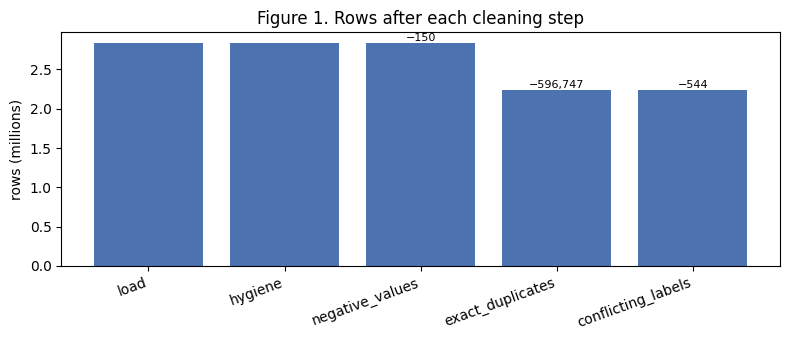

> #### Findings
> | Check | Result |
> |---|---|
> | Rows before → after cleaning | 2,830,743 → 2,233,302 (−21.1%) |
> | Original / engineered / model features | 66 / 15 / 59 |
> | Families learned / held out | 7 / 2 |
>
> **Meaning:** most of the reduction comes from duplicate removal (Section 1.8).


In [26]:
PATH = OUT_DIR / "cicids2017_clean.parquet"; D = OUT_DIR
df = pd.read_parquet(PATH)
fs = json.load(open(D / "feature_sets.json"))
LABEL, TARGET, CLASSES = fs["label_col"], fs["target_col"], fs["classes"]
RAW, ENG, MODEL = fs["features_raw"], fs["features_engineered"], fs["features_model"]
PORT = "Destination Port"
FEATS = [c for c in RAW + ENG if c != PORT]
for c in [LABEL, TARGET, "split", "source_file"]:
    df[c] = df[c].astype(str)

PALETTE = dict(zip(CLASSES + fs["holdout_families"],
                   plt.cm.tab10.colors[:len(CLASSES) + len(fs["holdout_families"])]))
TRAIN = (df["split"] == "train").to_numpy()
tr = df.loc[TRAIN]

# Stratified EDA sample from train (all rows of small families)
S = pd.concat([g.sample(n=min(len(g), SAMPLE_PER_FAMILY), random_state=SEED) for _, g in tr.groupby(TARGET)])
print(f"{len(df):,} rows loaded; train {TRAIN.sum():,}; EDA sample {len(S):,}")

log_path = D / "cleaning_log.csv"
if log_path.exists():
    LOG = pd.read_csv(log_path); display(LOG)
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.bar(LOG["step"], LOG["rows_after"] / 1e6, color="#4C72B0")
    for i, v in enumerate(LOG["rows_removed"]):
        if v: ax.text(i, LOG["rows_after"].iloc[i] / 1e6, f"−{v:,}", ha="center", va="bottom", fontsize=8)
    ax.set_ylabel("rows (millions)"); ax.set_title("Figure 1. Rows after each cleaning step")
    plt.xticks(rotation=20, ha="right"); savefig("01_cleaning_steps.png")
    removed = LOG["rows_removed"].sum(); start = LOG["rows_before"].iloc[0]
else:
    removed, start = 0, len(df)

findings([
    ("Rows before → after cleaning", f"{start:,} → {len(df):,} (−{100 * removed / start:.1f}%)"),
    ("Original / engineered / model features", f"{len(RAW)} / {len(ENG)} / {len(MODEL)}"),
    ("Families learned / held out", f"{len(CLASSES)} / {len(fs['holdout_families'])}"),
], "most of the reduction comes from duplicate removal (Section 1.8).")

### 1.E3 · Class distribution
Counts only, so all splits can be shown. The day × family table matters for the project: if each attack occurs on only one day, a model may learn *day-specific* conditions rather than the attack itself, and a time-based split is impossible without losing whole classes.

,rows,family,% of data
Label,,,
BENIGN,1897069,Benign,84.9446
DoS Hulk,172714,DoS,7.7336
DDoS,128013,DDoS,5.7320
DoS GoldenEye,10286,DoS,0.4606
FTP-Patator,5933,BruteForce,0.2657
DoS slowloris,5383,DoS,0.2410
DoS Slowhttptest,5228,DoS,0.2341
SSH-Patator,3219,BruteForce,0.1441
PortScan,1851,PortScan,0.0829


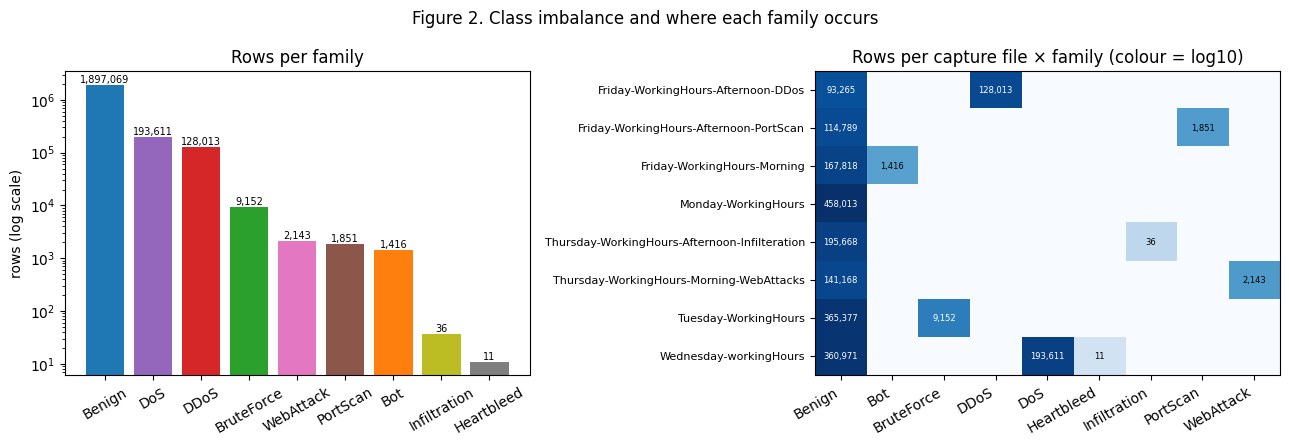

split,cal,test,thr,train,unseen
label_family,,,,,
Benign,189707,379414,189707,1138241,0
Bot,142,283,141,850,0
BruteForce,915,1830,916,5491,0
DDoS,12801,25603,12802,76807,0
DoS,19360,38723,19361,116167,0
Heartbleed,0,0,0,0,11
Infiltration,0,0,0,0,36
PortScan,185,370,185,1111,0
WebAttack,215,428,214,1286,0


> #### Findings
> | Check | Result |
> |---|---|
> | Largest / smallest learned family | Benign 1,897,069 / Bot 1,416 |
> | Imbalance ratio (learned families) | 1,340 : 1 |
> | Labels below 1,000 rows | Web Attack - XSS, Infiltration, Web Attack - Sql Injection, Heartbleed |
> | Attack families found in only one file | Bot, BruteForce, DDoS, DoS, Heartbleed, Infiltration, PortScan, WebAttack |
>
> **Meaning:** accuracy is meaningless at this imbalance; use macro-F1, per-class recall and PR-AUC. Attacks tied to a single capture day are why a stratified split is used: a time-based split would lose whole classes, which is stated as a threat to validity.


In [27]:
LAB_COUNTS = df[LABEL].value_counts().to_frame("rows")
LAB_COUNTS["family"] = LAB_COUNTS.index.map(df.drop_duplicates(LABEL).set_index(LABEL)[TARGET])
LAB_COUNTS["% of data"] = (100 * LAB_COUNTS["rows"] / len(df)).round(4)
display(LAB_COUNTS)

fam = df[TARGET].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(fam.index, fam.values, color=[PALETTE.get(f, "grey") for f in fam.index])
axes[0].set_yscale("log"); axes[0].set_ylabel("rows (log scale)"); axes[0].set_title("Rows per family")
for i, v in enumerate(fam.values): axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=7)
axes[0].tick_params(axis="x", rotation=30)
DAY = pd.crosstab(df["source_file"].str.replace(".pcap_ISCX.csv", "", regex=False), df[TARGET])
im = axes[1].imshow(np.log10(DAY.to_numpy() + 1), aspect="auto", cmap="Blues")
axes[1].set_xticks(range(DAY.shape[1])); axes[1].set_xticklabels(DAY.columns, rotation=30, ha="right")
axes[1].set_yticks(range(DAY.shape[0])); axes[1].set_yticklabels(DAY.index, fontsize=8)
for i in range(DAY.shape[0]):
    for j in range(DAY.shape[1]):
        if DAY.iat[i, j]:
            dark = np.log10(DAY.iat[i, j] + 1) > 0.6 * np.log10(DAY.to_numpy().max() + 1)
            axes[1].text(j, i, f"{DAY.iat[i, j]:,}", ha="center", va="center", fontsize=6, color="white" if dark else "black")
axes[1].set_title("Rows per capture file × family (colour = log10)")
plt.suptitle("Figure 2. Class imbalance and where each family occurs"); savefig("02_class_distribution.png")

attack_days = (DAY.drop(columns=["Benign"], errors="ignore") > 0).sum()
display(pd.crosstab(df[TARGET], df["split"]))
IMB = fam[CLASSES].max() / fam[CLASSES].min()
findings([
    ("Largest / smallest learned family", f"{fam[CLASSES].idxmax()} {fam[CLASSES].max():,} / {fam[CLASSES].idxmin()} {fam[CLASSES].min():,}"),
    ("Imbalance ratio (learned families)", f"{IMB:,.0f} : 1"),
    ("Labels below 1,000 rows", ", ".join(LAB_COUNTS.index[LAB_COUNTS["rows"] < 1000]) or "none"),
    ("Attack families found in only one file", ", ".join(attack_days.index[attack_days == 1]) or "none"),
], "accuracy is meaningless at this imbalance; use macro-F1, per-class recall and PR-AUC. "
   + ("Attacks tied to a single capture day are why a stratified split is used: a time-based split would lose whole classes, "
      "which is stated as a threat to validity." if (attack_days == 1).any() else
      "Attack families are spread over several files, so day confounding is limited."))

### 1.E4 · Descriptive statistics (train)
Skewness and the share of zeros explain the transformation choices in this part (signed log, wide outlier caps).

,median,mean,std,min,max,skew,kurtosis,%_zero,%_missing,n_unique,in_model
Total Length of Fwd Packets,74.000,686.561,13016.840,0.0,1.290000e+07,744.757,721686.790,9.928,0.000,14445,True
Subflow Fwd Bytes,74.000,686.539,12994.910,0.0,1.287034e+07,743.510,719929.053,9.928,0.000,14445,False
Fwd URG Flags,0.000,0.000,0.003,0.0,1.000000e+00,321.046,103068.692,99.999,0.000,2,True
act_data_pkt_fwd,1.000,6.987,752.083,0.0,2.075010e+05,240.209,58792.291,26.260,0.000,859,True
Subflow Bwd Bytes,190.000,22385.750,2762256.751,0.0,6.410014e+08,200.849,41384.404,18.548,0.000,47471,False
eng_total_bytes,288.000,23073.361,2766420.357,0.0,6.422883e+08,200.845,41384.733,9.386,0.000,53081,True
Total Length of Bwd Packets,190.000,22386.800,2762334.733,0.0,6.410014e+08,200.836,41378.145,18.548,0.000,47455,True
Total Backward Packets,2.000,13.824,1223.578,0.0,2.912600e+05,200.355,41254.746,9.731,0.000,1372,True
eng_total_packets,4.000,25.862,2140.060,2.0,5.099180e+05,200.194,41151.383,0.000,0.000,1821,True
Total Fwd Packets,2.000,12.038,916.942,1.0,2.186580e+05,200.106,41084.947,0.000,0.000,1109,True


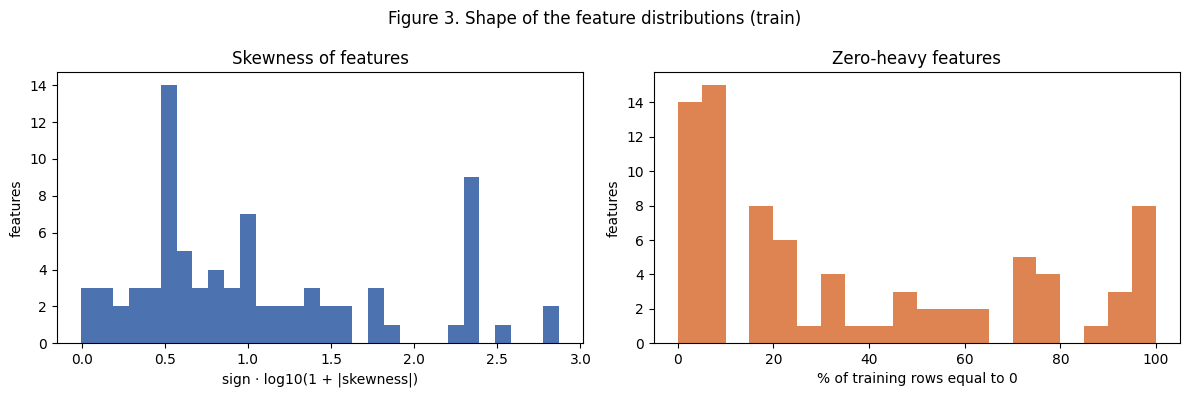

> #### Findings
> | Check | Result |
> |---|---|
> | Features with |skewness| > 10 | 30 of 80 |
> | Most skewed | Total Length of Fwd Packets (745), Subflow Fwd Bytes (744), Fwd URG Flags (321) |
> | Features with > 50% zeros | 27 |
> | Median ratio max / median (scale range) | 9,193× |
>
> **Meaning:** the features are extremely heavy-tailed and zero-inflated, so a log-type transform is needed for linear and distance-based models; tree models are unaffected by monotonic transforms.


In [28]:
X = tr[FEATS]
DESC = pd.DataFrame({
    "median": X.median(), "mean": X.mean(), "std": X.std(), "min": X.min(), "max": X.max(),
    "skew": X.skew(), "kurtosis": X.kurt(), "%_zero": (100 * (X == 0).mean()), "%_missing": 100 * X.isna().mean(),
    "n_unique": X.nunique(), "in_model": [c in MODEL for c in FEATS],
}).round(3)
display(DESC.sort_values("skew", ascending=False).head(15))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sk = DESC["skew"].replace([np.inf, -np.inf], np.nan).dropna()
axes[0].hist(np.sign(sk) * np.log10(1 + sk.abs()), bins=30, color="#4C72B0")
axes[0].set_xlabel("sign · log10(1 + |skewness|)"); axes[0].set_ylabel("features"); axes[0].set_title("Skewness of features")
axes[1].hist(DESC["%_zero"], bins=20, color="#DD8452")
axes[1].set_xlabel("% of training rows equal to 0"); axes[1].set_ylabel("features"); axes[1].set_title("Zero-heavy features")
plt.suptitle("Figure 3. Shape of the feature distributions (train)"); savefig("03_skew_zeros.png")

findings([
    ("Features with |skewness| > 10", f"{int((sk.abs() > 10).sum())} of {len(sk)}"),
    ("Most skewed", ", ".join(f"{k} ({v:,.0f})" for k, v in sk.abs().sort_values(ascending=False).head(3).items())),
    ("Features with > 50% zeros", f"{int((DESC['%_zero'] > 50).sum())}"),
    ("Median ratio max / median (scale range)", f"{np.nanmedian((DESC['max'] / DESC['median'].replace(0, np.nan)).abs()):,.0f}×"),
], "the features are extremely heavy-tailed and zero-inflated, so a log-type transform is needed for linear and "
   "distance-based models; tree models are unaffected by monotonic transforms.")

### 1.E5 · Feature relevance (mutual information, train)
Mutual information (MI) measures how much knowing a feature reduces uncertainty about the family. Unlike correlation it captures non-linear relations. Computed on a class-balanced training sample, on signed-log values.

,feature,MI,engineered,in_model,rank
0,Average Packet Size,1.4585,False,False,1
1,Packet Length Mean,1.4340,False,True,2
2,eng_total_bytes,1.4323,True,True,3
3,eng_bytes_per_pkt_ratio,1.3694,True,True,4
4,Subflow Fwd Bytes,1.3499,False,False,5
5,Total Length of Fwd Packets,1.3487,False,True,6
6,Max Packet Length,1.3134,False,True,7
7,Packet Length Std,1.3087,False,True,8
8,Init_Win_bytes_backward,1.3085,False,True,9
9,Packet Length Variance,1.3072,False,False,10


(10.1 s)


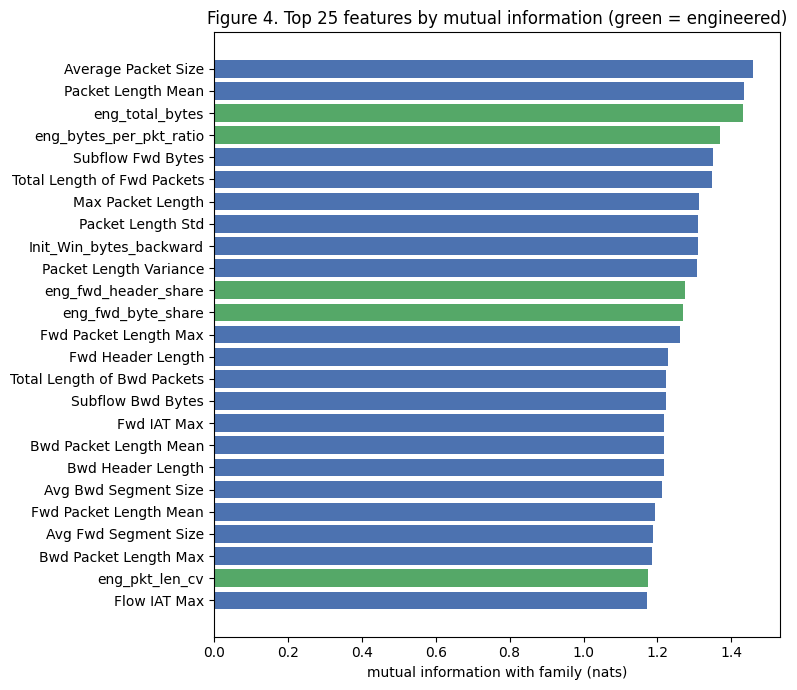

> #### Findings
> | Check | Result |
> |---|---|
> | Top 5 features | Average Packet Size, Packet Length Mean, eng_total_bytes, eng_bytes_per_pkt_ratio, Subflow Fwd Bytes |
> | Best engineered feature | eng_total_bytes (rank 3) |
> | Engineered features in top 20 | 4 |
> | Near-zero MI features (< 0.01) | 6: ECE Flag Count, RST Flag Count, Bwd PSH Flags, Fwd URG Flags, eng_single_packet, eng_zero_duration |
>
> **Meaning:** information is spread over many size- and timing-related features. Near-zero-MI features are candidates for removal, but MI is computed one feature at a time and misses interactions, so they are kept for now.


In [29]:
t0 = time.time()
M = pd.concat([g.sample(n=min(len(g), MI_PER_FAMILY), random_state=SEED) for _, g in tr.groupby(TARGET)])
Xm = signed_log(M[FEATS].to_numpy("float64"))
Xm = np.where(np.isnan(Xm), np.nanmedian(Xm, axis=0), Xm)
mi = mutual_info_classif(Xm, M[TARGET].to_numpy(), random_state=SEED, n_neighbors=3)
MI = pd.DataFrame({"feature": FEATS, "MI": mi.round(4), "engineered": [c in ENG for c in FEATS],
                   "in_model": [c in MODEL for c in FEATS]}).sort_values("MI", ascending=False).reset_index(drop=True)
MI["rank"] = np.arange(1, len(MI) + 1)
display(MI.head(20))
print(f"({time.time() - t0:.1f} s)")

top = MI.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top["feature"], top["MI"], color=["#55A868" if e else "#4C72B0" for e in top["engineered"]])
ax.set_xlabel("mutual information with family (nats)")
ax.set_title("Figure 4. Top 25 features by mutual information (green = engineered)")
savefig("04_mutual_information.png")

TOP = [c for c in MI["feature"] if c in MODEL][:TOP_K]
weak = MI.loc[MI["MI"] < 0.01, "feature"].tolist()
findings([
    ("Top 5 features", ", ".join(MI["feature"].head(5))),
    ("Best engineered feature", f"{MI.loc[MI.engineered, 'feature'].iloc[0]} (rank {MI.loc[MI.engineered, 'rank'].iloc[0]})"
                                if MI.engineered.any() else "n/a"),
    ("Engineered features in top 20", f"{int(MI.head(20)['engineered'].sum())}"),
    ("Near-zero MI features (< 0.01)", f"{len(weak)}" + (f": {', '.join(weak[:6])}" + ("…" if len(weak) > 6 else "") if weak else "")),
], "information is spread over many size- and timing-related features. Near-zero-MI features are candidates for "
   "removal, but MI is computed one feature at a time and misses interactions, so they are kept for now.")

### 1.E6 · Distributions of the top features by family (train)
Box plots on the signed-log scale (whiskers 5–95%, outliers hidden). Families whose boxes do not overlap are easy to separate with that feature.

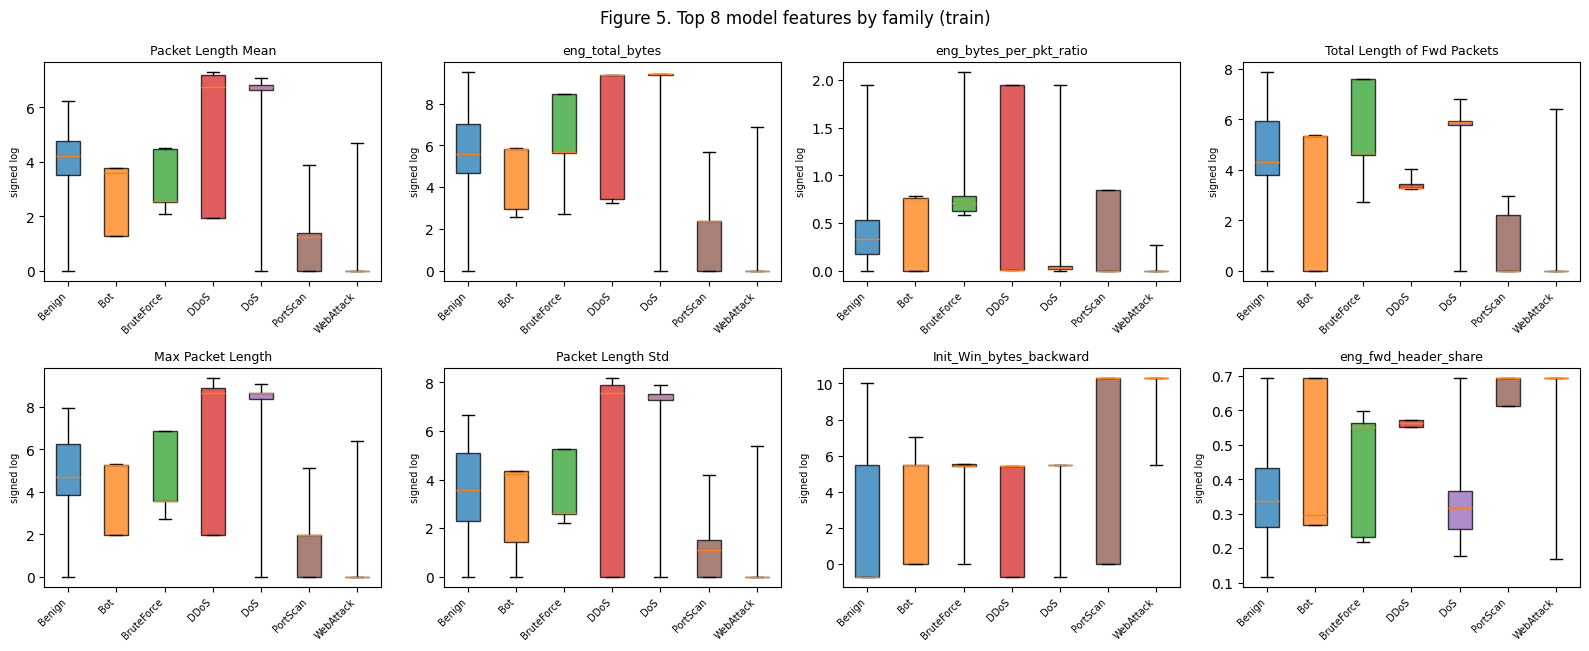

label_family,Benign,Bot,BruteForce,DDoS,DoS,PortScan,WebAttack
Packet Length Mean,66.20,35.70,11.80,833.50,851.29,2.4,0.0
eng_total_bytes,264.00,340.00,295.00,11627.00,11946.00,10.0,0.0
eng_bytes_per_pkt_ratio,0.40,1.13,1.04,0.00,0.03,0.0,0.0
Total Length of Fwd Packets,74.00,206.00,107.00,26.00,354.00,0.0,0.0
Max Packet Length,110.00,194.00,34.00,5755.00,5792.00,6.0,0.0
Packet Length Std,35.05,68.39,12.68,1896.92,1621.20,2.0,0.0
Init_Win_bytes_backward,-1.00,237.00,227.00,229.00,235.00,28960.0,28960.0
eng_fwd_header_share,0.40,0.34,0.73,0.75,0.37,1.0,1.0


> #### Findings
> | Check | Result |
> |---|---|
> | Most distinct family (mean |z| of medians) | WebAttack (1.28) |
> | Least distinct family | BruteForce (0.44) |
>
> **Meaning:** families with distinct medians on several top features should be easy for every model; the least distinct family is the one most likely to be confused with others, so watch its recall and the confusion matrix.


In [30]:
def family_boxes(cols, title, fname):
    n = len(cols); ncol = 4; nrow = int(np.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3.3 * nrow), squeeze=False)
    for ax, c in zip(axes.ravel(), cols):
        data = [signed_log(S.loc[S[TARGET] == f, c].dropna().to_numpy()) for f in CLASSES]
        bp = ax.boxplot(data, whis=(5, 95), showfliers=False, patch_artist=True)
        for patch, f in zip(bp["boxes"], CLASSES): patch.set_facecolor(PALETTE[f]); patch.set_alpha(0.75)
        ax.set_xticks(range(1, len(CLASSES) + 1)); ax.set_xticklabels(CLASSES, rotation=45, ha="right", fontsize=7)
        ax.set_title(c, fontsize=9); ax.set_ylabel("signed log", fontsize=7)
    for ax in axes.ravel()[n:]: ax.axis("off")
    plt.suptitle(title); savefig(fname)

family_boxes(TOP, f"Figure 5. Top {len(TOP)} model features by family (train)", "05_top_features_by_family.png")

# How distinct is each family? Median of each top feature, z-scored across families
MED = S.groupby(TARGET)[TOP].median().loc[CLASSES]
Zm = signed_log(MED); Zm = (Zm - Zm.mean()) / Zm.std().replace(0, 1)
display(MED.T.round(2))
most_distinct = Zm.abs().mean(axis=1).sort_values(ascending=False)
findings([
    ("Most distinct family (mean |z| of medians)", f"{most_distinct.index[0]} ({most_distinct.iloc[0]:.2f})"),
    ("Least distinct family", f"{most_distinct.index[-1]} ({most_distinct.iloc[-1]:.2f})"),
], "families with distinct medians on several top features should be easy for every model; the least distinct "
   "family is the one most likely to be confused with others, so watch its recall and the confusion matrix.")

### 1.E7 · Engineered features (train)
Checks whether the behavioural features from this part add separation, and which survived the redundancy filter.

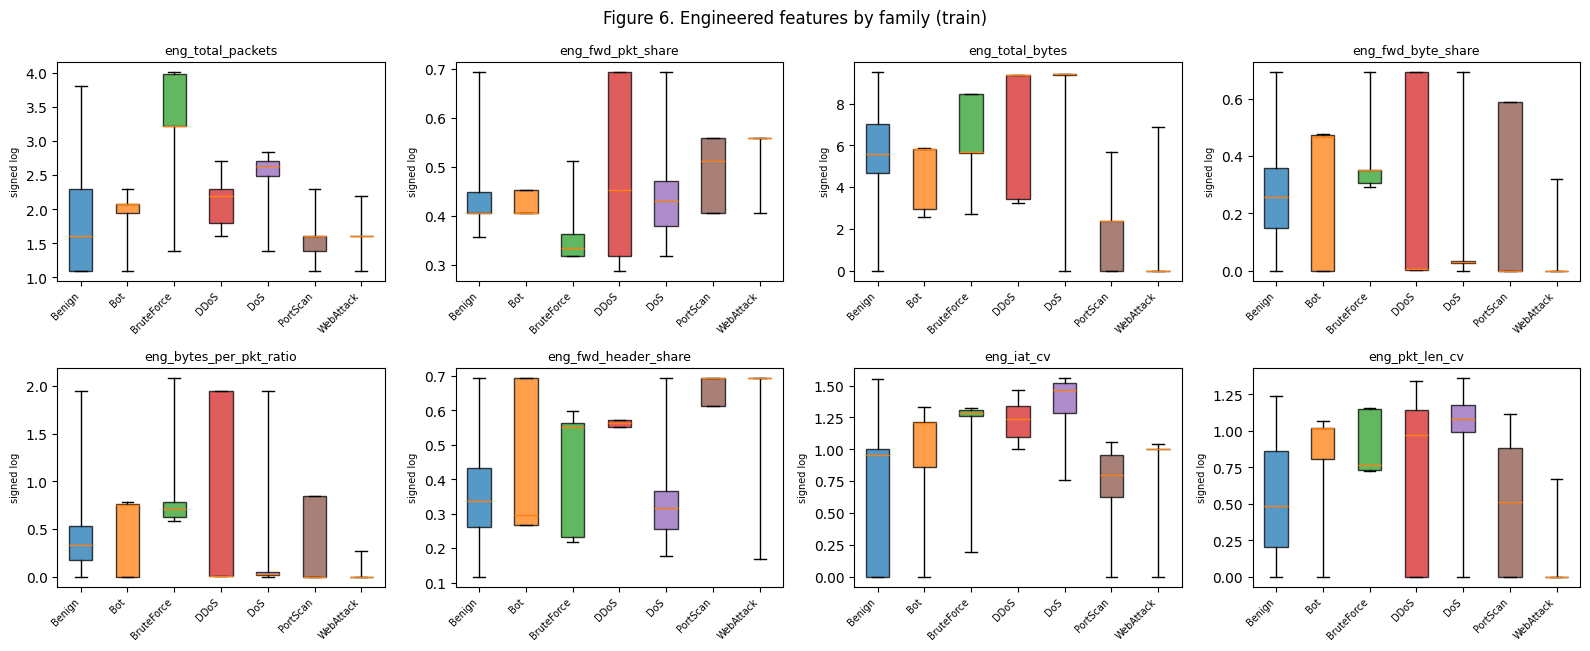

label_family,Benign,Bot,BruteForce,DDoS,DoS,PortScan,WebAttack
% of flows with flag = 1,,,,,,,
eng_no_fwd_payload,10.74,34.35,2.91,0.00,7.61,59.86,92.30
eng_zero_duration,0.04,0.24,0.04,0.00,0.00,0.00,0.00
eng_init_win_fwd_missing,47.95,0.00,0.00,0.00,0.00,0.45,0.00
eng_init_win_bwd_missing,55.71,0.00,0.76,36.48,8.18,3.42,0.86


,feature,MI,rank,in_model
2,eng_total_bytes,1.4323,3,True
3,eng_bytes_per_pkt_ratio,1.3694,4,True
10,eng_fwd_header_share,1.2736,11,True
11,eng_fwd_byte_share,1.2686,12,True
23,eng_pkt_len_cv,1.1756,24,True
35,eng_iat_cv,1.0572,36,True
41,eng_total_packets,0.8933,42,True
42,eng_fwd_pkt_share,0.8841,43,True
55,eng_active_idle_ratio,0.4035,56,True
62,eng_flag_total,0.2055,63,True


> #### Findings
> | Check | Result |
> |---|---|
> | Engineered features kept / created | 14 / 15 |
> | Median MI rank of engineered features | 43 of 80 |
>
> **Meaning:** engineered features that rank high in MI or show different flag rates across families add real information; their value for the model is tested properly by the ablation and SHAP analysis in later parts.


In [31]:
ENG_KEPT = [c for c in ENG if c in MODEL]
ENG_CONT = [c for c in ENG_KEPT if S[c].nunique() > 2]
ENG_BIN  = [c for c in ENG_KEPT if S[c].nunique() <= 2]
if ENG_CONT:
    family_boxes(ENG_CONT[:8], "Figure 6. Engineered features by family (train)", "06_engineered_by_family.png")
if ENG_BIN:
    display((100 * S.groupby(TARGET)[ENG_BIN].mean()).loc[CLASSES].round(2).T.rename_axis("% of flows with flag = 1"))
eng_rank = MI[MI.engineered][["feature", "MI", "rank", "in_model"]]
display(eng_rank)
findings([
    ("Engineered features kept / created", f"{len(ENG_KEPT)} / {len(ENG)}"),
    ("Median MI rank of engineered features", f"{int(eng_rank['rank'].median())} of {len(MI)}" if len(eng_rank) else "n/a"),
], "engineered features that rank high in MI or show different flag rates across families add real information; "
   "their value for the model is tested properly by the ablation and SHAP analysis in later parts.")

### 1.E8 · Correlation structure (train)
Spearman correlation (rank-based, robust to heavy tails) between the final model features, ordered by hierarchical clustering so groups of related features sit together. this part already removed pairs with |r| ≥ 0.98 (Pearson on signed log); this shows what redundancy remains.

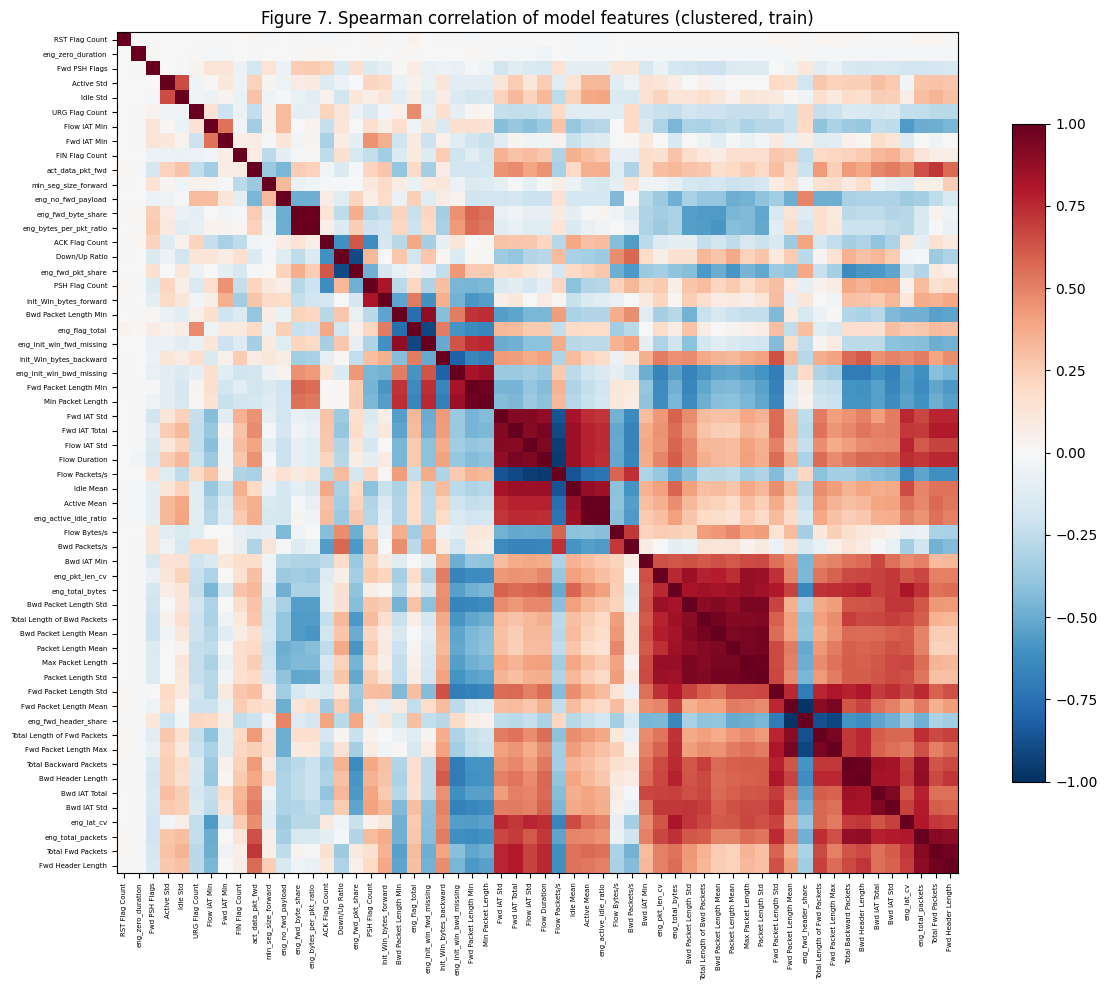

,a,b,spearman
0,Active Mean,eng_active_idle_ratio,0.991
1,Max Packet Length,Packet Length Std,0.984
2,Total Backward Packets,Bwd Header Length,0.980
3,eng_fwd_byte_share,eng_bytes_per_pkt_ratio,0.978
4,Fwd Packet Length Mean,eng_fwd_header_share,-0.977
5,Fwd Packet Length Min,Min Packet Length,0.970
6,Total Fwd Packets,Fwd Header Length,0.963
7,Bwd Packet Length Mean,Packet Length Std,0.960
8,Total Length of Bwd Packets,Bwd Packet Length Mean,0.956
9,Flow Duration,Flow Packets/s,-0.955


> #### Findings
> | Check | Result |
> |---|---|
> | Model features | 58 |
> | Pairs with |ρ| ≥ 0.9 | 33 of 1,653 |
> | Strongest remaining pair | Active Mean ~ eng_active_idle_ratio (ρ = 0.991) |
>
> **Meaning:** clusters of strongly related features remain (sizes, lengths, timings). This does not hurt tree models, but it splits SHAP credit across related features (RQ1, RQ2), so explanations should be read at the level of feature groups, and Logistic Regression needs regularisation.


In [32]:
CF = [c for c in MODEL if S[c].nunique() > 1]
C = S[CF].rank().corr().fillna(0).to_numpy().copy()
np.fill_diagonal(C, 1.0)
order = leaves_list(linkage(squareform(1 - np.abs(C), checks=False), method="average"))
Co = C[np.ix_(order, order)]; names = [CF[i] for i in order]
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(Co, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=90, fontsize=5)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=5)
plt.colorbar(im, fraction=0.03); ax.set_title("Figure 7. Spearman correlation of model features (clustered, train)")
savefig("07_correlation_heatmap.png")

iu = np.triu_indices(len(CF), 1)
PAIRS = pd.DataFrame({"a": np.array(CF)[iu[0]], "b": np.array(CF)[iu[1]], "spearman": C[iu]})
PAIRS = PAIRS.reindex(PAIRS["spearman"].abs().sort_values(ascending=False).index).reset_index(drop=True)
display(PAIRS.head(15).round(3))
n_high = int((PAIRS["spearman"].abs() >= HIGH_CORR).sum())
findings([
    ("Model features", f"{len(CF)}"),
    (f"Pairs with |ρ| ≥ {HIGH_CORR}", f"{n_high:,} of {len(PAIRS):,}"),
    ("Strongest remaining pair", f"{PAIRS.a[0]} ~ {PAIRS.b[0]} (ρ = {PAIRS.spearman[0]:.3f})"),
], "clusters of strongly related features remain (sizes, lengths, timings). This does not hurt tree models, but it "
   "splits SHAP credit across related features (RQ1, RQ2), so explanations should be read at the level of feature groups, "
   "and Logistic Regression needs regularisation.")

### 1.E9 · Zeros and missing values by family (train)
In flow data a zero or a missing value is often *meaningful* (no payload, no backward packets, zero duration). If the rate differs strongly by family, the indicator itself is informative, which supports keeping indicator features rather than dropping rows.

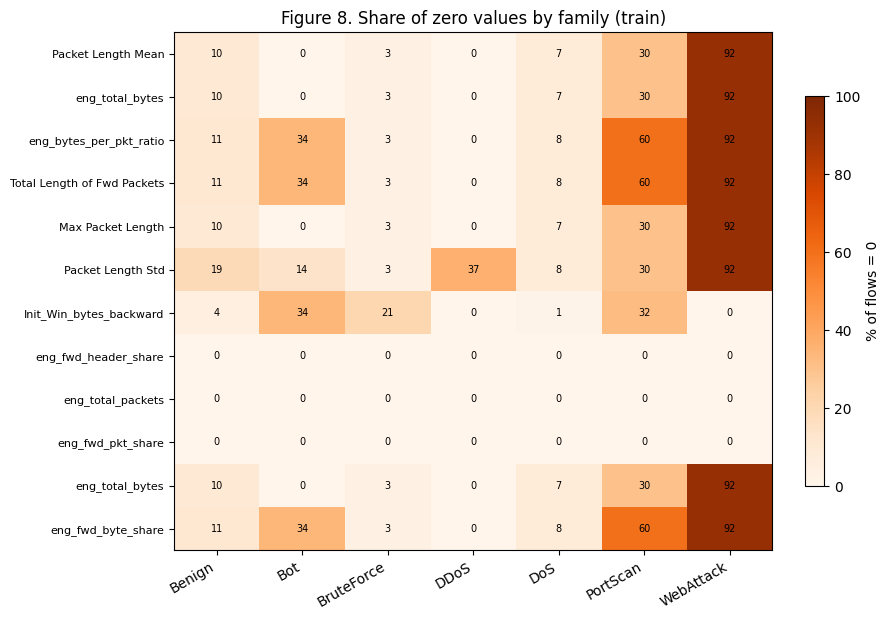

,Flow Bytes/s,Flow Packets/s
label_family,,
Benign,0.041,0.041
Bot,0.235,0.235
BruteForce,0.036,0.036
DDoS,0.001,0.001
DoS,0.001,0.001
PortScan,0.000,0.000
WebAttack,0.000,0.000


> #### Findings
> | Check | Result |
> |---|---|
> | Feature whose zero-rate differs most between families | Packet Length Mean (92 percentage points) |
> | Features with missing values (train) | Flow Bytes/s, Flow Packets/s |
>
> **Meaning:** zero-rates differ strongly between families, so zeros are information, not noise; this supports the zero-duration and missing-value indicators and argues against treating zeros as missing.


In [33]:
ZERO = (100 * (S[TOP + ENG_CONT[:4]] == 0).groupby(S[TARGET]).mean()).loc[CLASSES].T
fig, ax = plt.subplots(figsize=(9, 0.4 * len(ZERO) + 1.5))
im = ax.imshow(ZERO.to_numpy(), cmap="Oranges", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES, rotation=30, ha="right")
ax.set_yticks(range(len(ZERO))); ax.set_yticklabels(ZERO.index, fontsize=8)
for i in range(ZERO.shape[0]):
    for j in range(ZERO.shape[1]):
        ax.text(j, i, f"{ZERO.iat[i, j]:.0f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, fraction=0.03, label="% of flows = 0")
ax.set_title("Figure 8. Share of zero values by family (train)"); savefig("08_zeros_by_family.png")

MISS = (100 * tr[FEATS].isna().groupby(tr[TARGET]).mean())
MISS = MISS.loc[:, MISS.max() > 0].round(3)
display(MISS if MISS.shape[1] else Markdown("*No missing values in the cleaned training data.*"))
spread = (ZERO.max(axis=1) - ZERO.min(axis=1)).sort_values(ascending=False)
findings([
    ("Feature whose zero-rate differs most between families", f"{spread.index[0]} ({spread.iloc[0]:.0f} percentage points)"),
    ("Features with missing values (train)", ", ".join(MISS.columns) or "none"),
], ("zero-rates differ strongly between families, so zeros are information, not noise; this supports the zero-duration "
    "and missing-value indicators and argues against treating zeros as missing." if spread.iloc[0] >= 20 else
    "zero-rates are similar across families, so zeros carry little class information on their own."))
ZEROS_INFORMATIVE = bool(spread.iloc[0] >= 20)

### 1.E10 · Outliers by family (train)
Share of flows outside the 3×IQR fences (Tukey's far-out rule) on the signed-log scale, per family. If outliers concentrate in attack families, they are attack behaviour rather than recording errors, which is why this part caps only at the 0.01% / 99.99% quantiles instead of removing outliers.

label_family,Benign,Bot,BruteForce,DDoS,DoS,PortScan,WebAttack
Packet Length Mean,0.00,0.00,0.00,0.0,0.0,0.0,0.0
eng_total_bytes,0.00,0.00,0.00,0.0,0.0,0.0,0.0
eng_bytes_per_pkt_ratio,4.02,2.82,0.22,0.0,2.4,0.0,0.0
Total Length of Fwd Packets,0.00,0.00,0.00,0.0,0.0,0.0,0.0
Max Packet Length,0.00,0.00,0.00,0.0,0.0,0.0,0.0
Packet Length Std,0.00,0.00,0.00,0.0,0.0,0.0,0.0
Init_Win_bytes_backward,0.00,0.00,0.00,0.0,0.0,0.0,0.0
eng_fwd_header_share,0.00,0.00,0.00,0.0,0.0,0.0,0.0


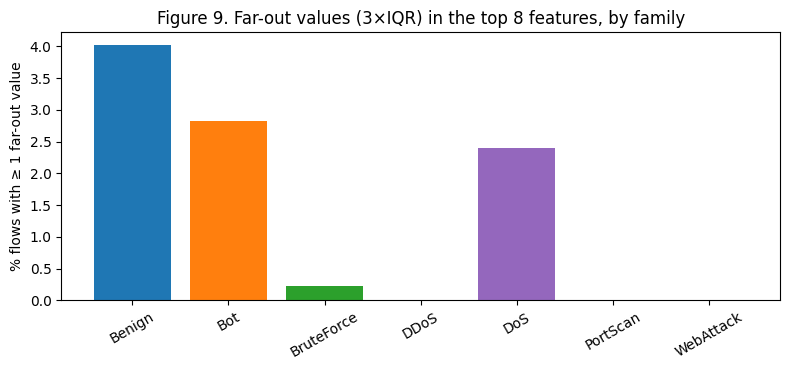

> #### Findings
> | Check | Result |
> |---|---|
> | Family with most far-out flows | Benign (4.0%) |
> | Benign flows with a far-out value | 4.0% |
>
> **Meaning:** far-out values are not concentrated in attack families; wide capping is still preferred over removal so that no attack flows are lost.


In [34]:
L = signed_log(S[TOP].to_numpy("float64"))
q1, q3 = np.nanpercentile(L, 25, axis=0), np.nanpercentile(L, 75, axis=0)
iqr = q3 - q1
out = (L < q1 - 3 * iqr) | (L > q3 + 3 * iqr)
OUT = pd.DataFrame(out, columns=TOP, index=S.index).groupby(S[TARGET]).mean().loc[CLASSES].mul(100).round(2)
display(OUT.T)
any_out = pd.Series(out.any(axis=1), index=S.index).groupby(S[TARGET]).mean().loc[CLASSES].mul(100)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(any_out.index, any_out.values, color=[PALETTE[f] for f in any_out.index])
ax.set_ylabel("% flows with ≥ 1 far-out value"); ax.tick_params(axis="x", rotation=30)
ax.set_title(f"Figure 9. Far-out values (3×IQR) in the top {len(TOP)} features, by family"); savefig("09_outliers_by_family.png")
att = any_out.drop(index="Benign", errors="ignore")
OUTLIERS_SIGNAL = bool(att.max() >= 1 and att.max() > 2 * any_out.get("Benign", 0))
findings([
    ("Family with most far-out flows", f"{any_out.idxmax()} ({any_out.max():.1f}%)"),
    ("Benign flows with a far-out value", f"{any_out.get('Benign', float('nan')):.1f}%"),
], ("far-out values concentrate in attack families, so they carry information and removing outliers would delete attacks; "
    "wide capping is the safer choice." if OUTLIERS_SIGNAL else
    "far-out values are not concentrated in attack families; wide capping is still preferred over removal so that "
    "no attack flows are lost."))

### 1.E11 · Destination Port (train)
The port is excluded from the main feature set because it may act as a shortcut. This shows how concentrated each family is on a few ports.

In [35]:
if PORT in df.columns:
    P = tr[[PORT, TARGET]]
    rows = []
    for f, g in P.groupby(TARGET):
        vc = g[PORT].value_counts(normalize=True)
        rows.append({"family": f, "distinct_ports": int(g[PORT].nunique()),
                     "top_3_ports": ", ".join(f"{int(p)} ({100 * s:.0f}%)" for p, s in vc.head(3).items()),
                     "top_port_share_%": round(100 * vc.iloc[0], 1)})
    PORTS = pd.DataFrame(rows).set_index("family").loc[CLASSES]
    display(PORTS)
    port_mi = MI.loc[MI.feature == PORT, "rank"]
    findings([
        ("Families ≥ 90% on one port", ", ".join(PORTS.index[PORTS["top_port_share_%"] >= 90]) or "none"),
        ("Benign distinct ports", f"{PORTS.loc['Benign', 'distinct_ports']:,}" if "Benign" in PORTS.index else "n/a"),
    ], "families sitting almost entirely on port 80 could be recognised by port alone in this lab capture but not in a real "
       "network, where web traffic of all kinds uses port 80. Excluding the raw port (with an ablation) is justified.")
else:
    print("Destination Port not present.")

,distinct_ports,top_3_ports,top_port_share_%
family,,,
Benign,42494,"53 (46%), 443 (25%), 80 (11%)",46.3
Bot,105,"8080 (88%), 1841 (0%), 1845 (0%)",87.8
BruteForce,2,"21 (65%), 22 (35%)",64.8
DDoS,2,"80 (100%), 64873 (0%)",100.0
DoS,1,80 (100%),100.0
PortScan,267,"80 (21%), 22 (13%), 21 (13%)",20.5
WebAttack,1,80 (100%),100.0


> #### Findings
> | Check | Result |
> |---|---|
> | Families ≥ 90% on one port | DDoS, DoS, WebAttack |
> | Benign distinct ports | 42,494 |
>
> **Meaning:** families sitting almost entirely on port 80 could be recognised by port alone in this lab capture but not in a real network, where web traffic of all kinds uses port 80. Excluding the raw port (with an ablation) is justified.


### 1.E12 · Low-dimensional views: PCA and t-SNE (train)
PCA shows how many directions carry the variance; t-SNE shows local neighbourhood structure. Both use the signed-log, standardised model features. t-SNE distances between clusters are **not** meaningful; only whether points of a family group together.

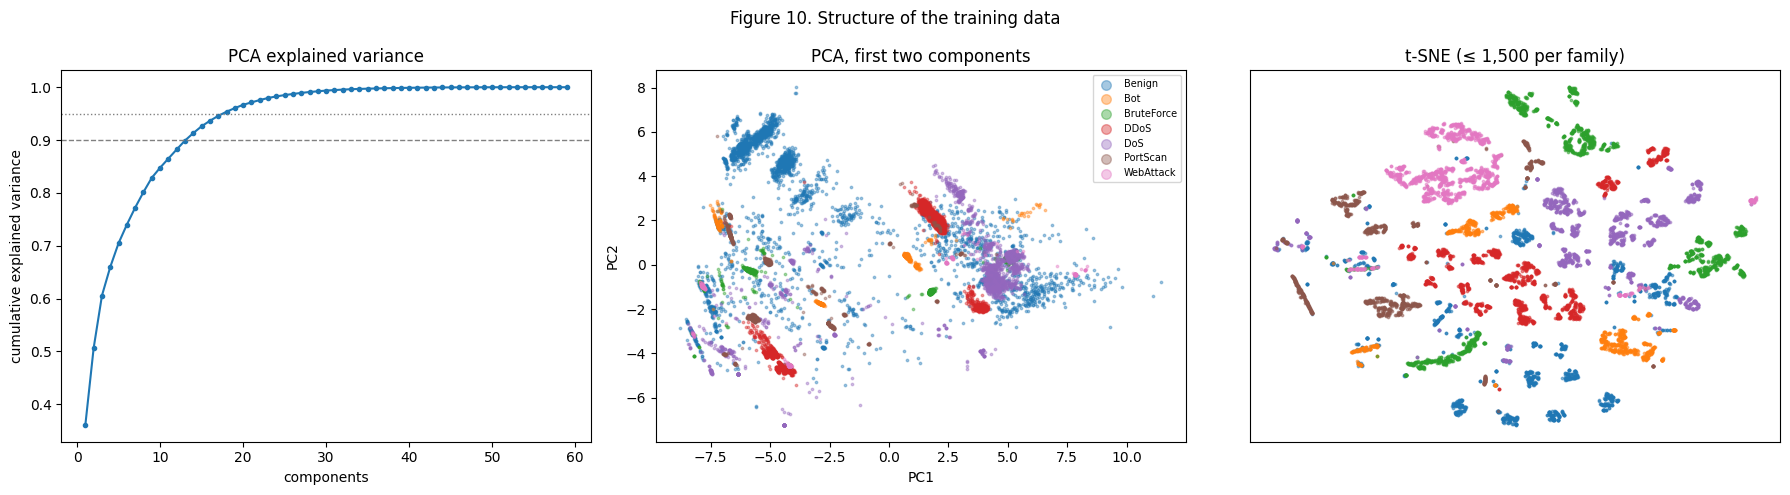

(41.6 s)


> #### Findings
> | Check | Result |
> |---|---|
> | Components for 90% / 95% of variance | 14 / 18 (of 59 features) |
> | PC1 + PC2 explain | 50.6% |
> | Features driving PC1 | Bwd IAT Std, Bwd Packet Length Std, Bwd IAT Total |
>
> **Meaning:** the information is spread over many directions, so a 2-D picture shows only part of the structure. Families that form their own clusters should be easy; families mixed into Benign are where false negatives and the confidence-aware policy will matter most.


In [36]:
t0 = time.time()
V = signed_log(S[MODEL].to_numpy("float64")); V = np.where(np.isnan(V), np.nanmedian(V, axis=0), V)
sd = V.std(0); sd[sd == 0] = 1; V = (V - V.mean(0)) / sd
pca = PCA(random_state=SEED).fit(V)
cum = np.cumsum(pca.explained_variance_ratio_)
n90, n95 = int(np.searchsorted(cum, 0.90) + 1), int(np.searchsorted(cum, 0.95) + 1)
P2 = pca.transform(V)[:, :2]

ncols = 3 if RUN_TSNE else 2
fig, axes = plt.subplots(1, ncols, figsize=(6 * ncols, 5))
axes[0].plot(np.arange(1, len(cum) + 1), cum, marker=".")
axes[0].axhline(0.9, ls="--", c="grey", lw=1); axes[0].axhline(0.95, ls=":", c="grey", lw=1)
axes[0].set_xlabel("components"); axes[0].set_ylabel("cumulative explained variance"); axes[0].set_title("PCA explained variance")
fam_S = S[TARGET].to_numpy()
for f in CLASSES:
    m = fam_S == f; idx = np.flatnonzero(m)[:3000]
    axes[1].scatter(P2[idx, 0], P2[idx, 1], s=3, alpha=0.4, color=PALETTE[f], label=f)
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2"); axes[1].set_title("PCA, first two components")
axes[1].legend(markerscale=4, fontsize=7)

if RUN_TSNE:
    T_idx = np.concatenate([rng.choice(np.flatnonzero(fam_S == f), size=min(TSNE_PER_FAMILY, int((fam_S == f).sum())),
                                       replace=False) for f in CLASSES])
    Vt = PCA(n_components=min(30, V.shape[1]), random_state=SEED).fit_transform(V[T_idx])
    T2 = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(Vt)
    for f in CLASSES:
        m = fam_S[T_idx] == f
        axes[2].scatter(T2[m, 0], T2[m, 1], s=3, alpha=0.5, color=PALETTE[f], label=f)
    axes[2].set_title(f"t-SNE (≤ {TSNE_PER_FAMILY:,} per family)"); axes[2].set_xticks([]); axes[2].set_yticks([])
plt.suptitle("Figure 10. Structure of the training data"); savefig("10_pca_tsne.png")
print(f"({time.time() - t0:.1f} s)")

LOAD = pd.DataFrame(pca.components_[:2].T, index=MODEL, columns=["PC1", "PC2"])
top_pc1 = LOAD["PC1"].abs().sort_values(ascending=False).head(3).index.tolist()
findings([
    ("Components for 90% / 95% of variance", f"{n90} / {n95} (of {len(MODEL)} features)"),
    ("PC1 + PC2 explain", f"{100 * cum[1]:.1f}%"),
    ("Features driving PC1", ", ".join(top_pc1)),
], "the information is spread over many directions, so a 2-D picture shows only part of the structure. Families that "
   "form their own clusters should be easy; families mixed into Benign are where false negatives and the "
   "confidence-aware policy will matter most.")

### 1.E13 · Split check: train vs cal
Kolmogorov–Smirnov statistic per feature between `train` and `cal` (same family mix by construction). Values near 0 mean the split produced sets from the same distribution. `test` is deliberately not used.

In [37]:
CAL = (df["split"] == "cal").to_numpy()
a = df.loc[TRAIN, MODEL].sample(n=min(100_000, int(TRAIN.sum())), random_state=SEED)
b = df.loc[CAL, MODEL].sample(n=min(100_000, int(CAL.sum())), random_state=SEED)
KS = pd.Series({c: ks_2samp(a[c].dropna(), b[c].dropna()).statistic for c in MODEL}).sort_values(ascending=False)
display(KS.head(10).round(4).to_frame("KS train vs cal"))
findings([
    ("Largest KS statistic", f"{KS.index[0]} ({KS.iloc[0]:.4f})"),
    ("Median KS statistic", f"{KS.median():.4f}"),
], "train and cal come from the same distribution, as expected from a stratified random split. Note that this does "
   "not show how the model would do on traffic from a different network (a limitation to state in the report).")

,KS train vs cal
Total Length of Fwd Packets,0.0047
Fwd Packet Length Mean,0.0041
Max Packet Length,0.0040
Packet Length Mean,0.0040
Packet Length Std,0.0040
eng_pkt_len_cv,0.0040
eng_fwd_header_share,0.0039
Bwd Packet Length Mean,0.0039
Flow IAT Std,0.0037
eng_total_bytes,0.0035


> #### Findings
> | Check | Result |
> |---|---|
> | Largest KS statistic | Total Length of Fwd Packets (0.0047) |
> | Median KS statistic | 0.0024 |
>
> **Meaning:** train and cal come from the same distribution, as expected from a stratified random split. Note that this does not show how the model would do on traffic from a different network (a limitation to state in the report).


### 1.E14 · Summary

In [38]:
SUMMARY = pd.DataFrame([
    ("Class imbalance", f"{IMB:,.0f} : 1 between learned families",
     "macro-F1, per-class recall, PR-AUC; class weights vs SMOTE and calibration (Part 2)"),
    ("Attacks tied to capture days", ", ".join(attack_days.index[attack_days == 1]) or "none",
     "stratified split is the main split; state day confounding as a threat to validity"),
    ("Heavy tails", f"{int((sk.abs() > 10).sum())} features with |skew| > 10", "signed log + scaling for LR / SMOTE / distance methods"),
    ("Zeros by family", f"{spread.index[0]}: {spread.iloc[0]:.0f} pp spread",
     "keep zero/missing indicators, do not impute zeros" if ZEROS_INFORMATIVE else "zeros not strongly class-specific"),
    ("Outliers by family", f"most in {any_out.idxmax()} ({any_out.max():.1f}%)",
     "outliers carry attack information: wide capping only" if OUTLIERS_SIGNAL else "wide capping only; no removal"),
    ("Remaining redundancy", f"{n_high} pairs |ρ| ≥ {HIGH_CORR}", "group-level reading of SHAP; regularised LR"),
    ("Most informative features", ", ".join(MI['feature'].head(3)), "check that SHAP agrees (RQ1, RQ2)"),
    ("Port shortcut", ", ".join(PORTS.index[PORTS['top_port_share_%'] >= 90]) if PORT in df.columns else "n/a",
     "port excluded from main set; with/without ablation"),
    ("Separability", f"{n90} components for 90% variance", "expect high scores for clustered families; watch families mixed with Benign"),
], columns=["Observation", "Evidence (this run)", "Consequence for modelling"])
display(SUMMARY)

SUMMARY.to_csv(EDA_OUT / "eda_summary.csv", index=False)
DESC.to_csv(EDA_OUT / "descriptive_stats_train.csv"); MI.to_csv(EDA_OUT / "mutual_information.csv", index=False)
PAIRS.head(200).to_csv(EDA_OUT / "top_correlated_pairs.csv", index=False); OUT.to_csv(EDA_OUT / "outliers_by_family.csv")
ZERO.to_csv(EDA_OUT / "zeros_by_family.csv"); LAB_COUNTS.to_csv(EDA_OUT / "label_counts.csv")
KS.to_frame("ks").to_csv(EDA_OUT / "split_check_train_vs_cal.csv")
if PORT in df.columns: PORTS.to_csv(EDA_OUT / "ports_by_family.csv")
display(pd.DataFrame([(str(p.relative_to(EDA_OUT)), round(p.stat().st_size / 1e6, 3))
                      for p in sorted(EDA_OUT.rglob("*")) if p.is_file()], columns=["file", "size_mb"]))

,Observation,Evidence (this run),Consequence for modelling
0,Class imbalance,"1,340 : 1 between learned families","macro-F1, per-class recall, PR-AUC; class weig..."
1,Attacks tied to capture days,"Bot, BruteForce, DDoS, DoS, Heartbleed, Infilt...",stratified split is the main split; state day ...
2,Heavy tails,30 features with |skew| > 10,signed log + scaling for LR / SMOTE / distance...
3,Zeros by family,Packet Length Mean: 92 pp spread,"keep zero/missing indicators, do not impute zeros"
4,Outliers by family,most in Benign (4.0%),wide capping only; no removal
5,Remaining redundancy,33 pairs |ρ| ≥ 0.9,group-level reading of SHAP; regularised LR
6,Most informative features,"Average Packet Size, Packet Length Mean, eng_t...","check that SHAP agrees (RQ1, RQ2)"
7,Port shortcut,"DDoS, DoS, WebAttack",port excluded from main set; with/without abla...
8,Separability,14 components for 90% variance,expect high scores for clustered families; wat...


,file,size_mb
0,descriptive_stats_train.csv,0.007
1,eda_summary.csv,0.001
2,figures/01_cleaning_steps.png,0.073
3,figures/02_class_distribution.png,0.190
4,figures/03_skew_zeros.png,0.073
5,figures/04_mutual_information.png,0.190
6,figures/05_top_features_by_family.png,0.167
7,figures/06_engineered_by_family.png,0.184
8,figures/07_correlation_heatmap.png,0.328
9,figures/08_zeros_by_family.png,0.160


### Summary of preprocessing decisions
| # | Decision | Default | Section |
|---|---|---|---|
| 1 | Missing values | keep rows; train-median imputation + indicators | 4, 11 |
| 2 | Duplicates / conflicts | remove before split; drop all conflicting | 8 |
| 3 | Destination Port | excluded; IANA buckets for ablation | 7 |
| 4 | Imbalance | per-label caps stratified by day; class weights and SMOTE both saved | 12, 13 |
| 5 | Evaluation subsets | 300 / family (attacks, SHAP); 50 / family nested (LLM agents) | 14 |
| 6 | Threat model | client-side features only; totals, maxima and durations increase-only; minima and spreads both ways; within train 99.9% quantile | 15 |
| 7 | SHAP stability | measured per feature and per feature group | 16 |

**Known limitation to state in the report:** published audits (Engelen et al., 2021) found labelling errors in the original CICIDS2017 files. This project uses the original labels for comparability with prior work; duplicate and conflict removal (Section 1.8) reduces but does not remove this noise.

### Contribution to the research questions
| RQ | What this part provides |
|---|---|
| **RQ1** | the validated threat model (attacker-controllable feature space) and the fixed flows that will be attacked; feature groups for SHAP stability |
| **RQ2** | a transformation fitted on `train` only, so indicators computed on attacked flows are on the same scale as on clean flows |
| **RQ3** | identical evaluation subsets for every configuration, including the nested `agent-eval` set for the LLM systems |
| **RQ4** | `agent-eval` sized so the LLM configurations fit within Kaggle's GPU budget |

#### Next: Part 2 · Detectors
Train the selected classifiers and anomaly detectors (benign training flows only), calibrate classifier confidence on `cal`, compute the clean SHAP baseline, and measure latency and cost.

> #### ✅ Part 1 · Key takeaways (reported run)
> - **2,830,743 → 2,233,302 flows (−21.1 %)**: 596,747 exact duplicates (PortScan was 98.8 % duplicated) and 544 flows with conflicting labels were removed *before* splitting, so no flow can appear in both training and test data.
> - 7 attack/benign families are learned; **Heartbleed and Infiltration (47 flows) are held out as never-seen attacks**. Class imbalance falls from 1,340 : 1 to 235 : 1 in the training subsample, which stays statistically representative (KS ≤ 0.004).
> - 59 model features (+ 2 missing-value indicators) after training-only selection; *Destination Port* is excluded because it is a lab-specific shortcut.
> - **Threat model:** 13 attacker-controllable, 33 dependent and 35 uncontrollable features; the projection passed all validation tests with **0 constraint violations**. All 17 final checks passed.

[↑ back to contents](#top)

---
## Viva guide for this notebook

**Suggested demonstration path (about 5 minutes)**
1. **Figure 0.1** (project pipeline) at the top: the whole project in one picture.
2. **Figure 1.1** and the cleaning table in **1.8**: duplicates removed *before* the split, PortScan 98.8 % duplicated.
3. **1.9**: the stratified split and the two never-seen families.
4. **1.15** and **Figure 1.2**: the threat model and its three validation tests (0 violations).
5. **1.E3** (class distribution) and **1.E5** (mutual information): imbalance and engineered features.
6. **1.17**: all 17 final checks passed.

**Likely questions and short answers**

| Question | Answer |
|---|---|
| Why remove duplicates before splitting? | Otherwise the same flow appears in training and test, and the model is rewarded for memorising. PortScan was 98.8 % duplicated. |
| Why not a time-based split? | Every attack family occurs on only one capture day, so a time split would remove whole classes from training. I used a stratified split and treat the day confound as a limitation. |
| How did you prevent leakage? | Row-wise rules run before the split; everything that learns numbers (medians, caps, scaling, feature selection) is fitted on the training split only and saved. |
| Why exclude Destination Port? | DoS, DDoS and WebAttack are 100 % on port 80 in this lab capture, a shortcut that would not hold on real networks. Notebook 2 shows it adds only +0.0002 macro-F1. |
| Why cap outliers instead of removing them? | Extreme values are concentrated in attack families, so they are signal, not noise. |
| How do you know the threat model is correct? | Three tests: an unchanged flow is returned exactly; 9 of 12 dependent formulas reproduce the data exactly (3 approximate); random perturbations of all 1,783 attack flows give 0 violations. |
| Why hold out Heartbleed and Infiltration? | To test whether the mechanism notices attacks the classifier has never seen (Notebook 4: 100 % and 92 % not accepted). |